# Dunelm — Market Performance, Forecast & Growth Opportunities
### Customer Analytics case study · SQL-first analysis (DuckDB) with Python for modelling and visuals

**Brief (Customer Director):**
1. In the context of the market, how is Dunelm performing?
2. What do we forecast the market size to be in the future, and what could impact this?
3. What opportunities exist for Dunelm to grow?
4. What actions could Dunelm take to achieve this growth, and how would we assess their success?

**Approach.** The notebook follows a layered pipeline so every number is traceable:

| Layer | What happens | Tool |
|---|---|---|
| `raw_*` | Excel sheets loaded untouched | Python → DuckDB |
| `stg_*` | Renamed, typed columns — no rows changed | SQL views |
| Data quality | 20+ checks: grain, nulls, duplicates, calendar, logic, outliers, cross-source reconciliation | SQL |
| `clean_*` | Documented fixes applied, derived fields added | SQL tables |
| `mart_*` | Analysis-ready aggregates per question | SQL |
| Modelling & visuals | Forecasting, backtesting, power calculations, charts | Python (statsmodels, scipy, matplotlib) |

> **Reading guide.** Each section ends with a *So what* box — the line that goes on the slide. Section 0 collects them as the executive summary.

## 0. Executive summary
*(Numbers below are produced by the cells in this notebook; the final cell of Section 11 re-prints the headline figures from the data so they can be checked.)*

**1 · Performance: Dunelm is outgrowing a flat market, and 2023 was the turning point.** The market was flat in 2023 (**+0.1%**, £9.48bn; rest of market −0.4%) while Dunelm grew **+5.8%** to £807m, lifting value share from **8.05% → 8.51%**, with gains in both categories. On a like-for-like basis, share was flat in 2022 and jumped in 2023. Growth is **volume-led, not price-led**: Dunelm units +4.2% while the rest of the market lost 6.7%, and Dunelm's price per unit rose only +1.6% vs +6.8%, so it became relatively better value. Internally, growth came from **more customers (+3.5%) shopping more often (+6.9%)**, partly offset by **smaller baskets (AOV −4.4%)**, concentrated in Segment 3, the most valuable customers.

**2 · Forecast: a flat-to-slightly-declining market, ~£9.36bn in 2024 easing to ~£9.12bn by 2026 (80% range £8.8–9.6bn).** Market value is held up by price (+5% per unit) while volume falls (−6%), for the second year running. As inflation eases, value drifts down unless volume recovers. The forecast is a per-category ensemble chosen by backtest (holdout WAPE 5.2%, bias −0.3%); scenarios range from £8.4bn to £10.4bn by 2026. **Holding today's share is not enough:** at 8.5% of the central forecast, Dunelm's sales would fall by about £30m by 2026.

**3 · Opportunities: growth has to come from share, using five levers worth ~£4–22m a year each (not additive).**
- **Basket value in the loyal core (~£21m, highest confidence):** Segment 3 customers grew 9.7%, but spend per customer fell 10%, about 80% of it from **fewer items per order**.
- **Reach (~£22m per +1pp):** Dunelm reaches 31% of market households vs 60% for Competitor B; the gap is widest in C2/D/E. Price seekers spend almost as much as other customers in the same grade, so value-conscious households are not low-value.
- **Category 1 cross-sell (~£17m per +0.5pp):** share is 6.5% vs 9.6% in Category 2, despite pricing in line with the market.
- **Compete on the customer's calendar (~£8m, indicative):** Dunelm under-trades January (Category 1) and the Black Friday → Christmas run (Category 2), then wins share back in its own post-Christmas sale.
- **Move light shoppers up (~£4m):** Segment 1 frequency already rose 19%.

**4 · Actions & measurement.** Five plays in priority order: (1) basket value, (2) reach in C2/D/E, (3) Category 1 cross-sell, (4) peak timing, (5) light-shopper frequency. Each has one primary KPI, guardrails, a 2023 baseline and a test sized before launch. Customer-level tests are very sensitive (a 10% holdout of Segment 1 detects a **~1–1.5% uplift**). National share is too noisy to judge a single campaign (~1pp minimum detectable change in Category 2 over 12 weeks), so share is the strategic outcome, tracked quarterly, and incrementality is proven with holdouts and geo tests.

## 1. Setup

In [1]:
import warnings, math
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display, Markdown
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import STL
from statsmodels.stats.power import NormalIndPower
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# --- Paths ---------------------------------------------------------------
DATA_FILE = Path("data/dunelm_task.xlsx")      # copy of 'Presentation Task Customer Analytics - Candidate Version.xlsx'
FIG_DIR   = Path("figures");  FIG_DIR.mkdir(exist_ok=True)
OUT_DIR   = Path("outputs");  OUT_DIR.mkdir(exist_ok=True)

# --- DuckDB in-memory database ----------------------------------------------
con = duckdb.connect(database=":memory:")

def q(sql: str) -> pd.DataFrame:
    # Run a SQL statement in DuckDB and return a pandas DataFrame.
    return con.sql(sql).df()

def run(sql: str) -> None:
    # Execute DDL / DML (no result expected).
    con.execute(sql)

print("DuckDB", duckdb.__version__, "| pandas", pd.__version__)

DuckDB 2.0.0 | pandas 3.1.0


In [2]:
# --- Chart style: one consistent, colour-blind-validated palette ------------
# Colours validated with a CVD (colour-vision-deficiency) checker:
#   Dunelm / Category 1 = blue, Category 2 = orange, Competitor A = aqua, Competitor B = yellow.
C = dict(dunelm="#2a78d6", cat1="#2a78d6", cat2="#eb6834",
         comp_a="#1baf7a", comp_b="#eda100", market="#8a8984",
         ink="#0b0b0b", ink2="#52514e", grid="#e6e5e1", neg="#e34948")
CAT_COL = {"Category 1": C["cat1"], "Category 2": C["cat2"]}

plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 110, "savefig.dpi": 160,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C["ink2"], "axes.labelcolor": C["ink2"],
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": C["ink2"], "ytick.color": C["ink2"],
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "lines.linewidth": 2, "legend.frameon": False,
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

pct = mtick.PercentFormatter(1.0, decimals=1)
gbp_m = mtick.FuncFormatter(lambda x, _: f"£{x/1e6:,.0f}m")

## 2. Load raw data (no changes)
The workbook has three data sheets plus a task sheet. They are loaded exactly as delivered into `raw_*` tables. Loading through pandas keeps the notebook portable; DuckDB's `excel` extension (`read_xlsx`) is an alternative where extensions can be installed.

In [3]:
SHEETS = {
    "raw_market_weekly": "Market Data 1",   # weekly market + Dunelm sales by category
    "raw_internal":      "Internal Data",   # Dunelm annual sales by customer type
    "raw_market_hh":     "Market Data 2",   # households shopping the market / retailers (separate source)
}
for table, sheet in SHEETS.items():
    df = pd.read_excel(DATA_FILE, sheet_name=sheet)
    con.register("tmp_df", df)
    run(f"CREATE OR REPLACE TABLE {table} AS SELECT * FROM tmp_df")
    con.unregister("tmp_df")

q('''
SELECT table_name, COUNT(*) AS n_columns
FROM information_schema.columns
WHERE table_name LIKE 'raw_%'
GROUP BY 1 ORDER BY 1
''').merge(
    pd.DataFrame([(t, q(f"SELECT COUNT(*) FROM {t}").iloc[0, 0]) for t in SHEETS],
                 columns=["table_name", "n_rows"]), on="table_name")

,table_name,n_columns,n_rows
0,raw_internal,8,72
1,raw_market_hh,4,20
2,raw_market_weekly,8,292


In [4]:
for t in SHEETS:
    print(f"--- {t}")
    display(q(f"DESCRIBE {t}")[["column_name", "column_type"]].T)

--- raw_market_weekly


,0,1,2,3,4,5,6,7
column_name,Calendar Year,Calendar Month,Calendar Week,Product Category,Market Sales Value (including Dunelm),Market Sales Volume (including Dunelm),Dunelm Sales Value,Dunelm Sales Volume
column_type,BIGINT,BIGINT,BIGINT,VARCHAR,DOUBLE,DOUBLE,DOUBLE,DOUBLE


--- raw_internal


,0,1,2,3,4,5,6,7
column_name,Calendar Year,Customer Segment,Grade,I Look For The Lowest Possible Prices When I G...,Customers,Sales Orders,Sales Volume,Sales Value
column_type,BIGINT,VARCHAR,VARCHAR,BIGINT,BIGINT,BIGINT,BIGINT,DOUBLE


--- raw_market_hh


,0,1,2,3
column_name,Retailer,Demographic Type,Demographic,Households
column_type,VARCHAR,VARCHAR,VARCHAR,BIGINT


## 3. Staging layer — rename and type, nothing else
Short, consistent column names make the SQL readable. Row counts are asserted to prove staging changes no data.

“I separate renaming and typing from cleaning. Staging only makes the data readable and correctly typed, and I assert that no rows change. All business decisions, like dropping the duplicated week, happen later in the clean layer, where each one is documented. If a number is ever questioned, I can trace it back through each layer to the original Excel cell.”

In [5]:
run('''
CREATE OR REPLACE VIEW stg_market_weekly AS
SELECT
    CAST("Calendar Year"  AS INTEGER)                       AS yr,
    CAST("Calendar Month" AS INTEGER)                       AS mth,
    CAST("Calendar Week"  AS INTEGER)                       AS wk,
    "Product Category"                                      AS category,
    CAST("Market Sales Value (including Dunelm)"  AS DOUBLE) AS mkt_value,
    CAST("Market Sales Volume (including Dunelm)" AS DOUBLE) AS mkt_volume,
    CAST("Dunelm Sales Value"  AS DOUBLE)                   AS dun_value,
    CAST("Dunelm Sales Volume" AS DOUBLE)                   AS dun_volume
FROM raw_market_weekly
''')

run('''
CREATE OR REPLACE VIEW stg_internal AS
SELECT
    CAST("Calendar Year" AS INTEGER)                        AS yr,
    "Customer Segment"                                      AS segment,
    "Grade"                                                 AS social_grade,
    CAST("I Look For The Lowest Possible Prices When I Go Shopping" AS INTEGER) AS price_seeker_flag,
    CAST("Customers"    AS DOUBLE)                          AS customers,
    CAST("Sales Orders" AS DOUBLE)                          AS orders,
    CAST("Sales Volume" AS DOUBLE)                          AS units,
    CAST("Sales Value"  AS DOUBLE)                          AS sales_value
FROM raw_internal
''')

run('''
CREATE OR REPLACE VIEW stg_market_hh AS
SELECT
    "Retailer"                      AS retailer,
    "Demographic Type"              AS demographic_type,
    "Demographic"                   AS demographic,
    CAST("Households" AS DOUBLE)    AS households
FROM raw_market_hh
''')

for raw, stg in [("raw_market_weekly","stg_market_weekly"),("raw_internal","stg_internal"),("raw_market_hh","stg_market_hh")]:
    n_raw = q(f"SELECT COUNT(*) FROM {raw}").iloc[0, 0]
    n_stg = q(f"SELECT COUNT(*) FROM {stg}").iloc[0, 0]
    assert n_raw == n_stg, f"{stg} row count changed"
    print(f"{stg:<20} {n_stg:>4} rows  ✓ matches {raw}")

stg_market_weekly     292 rows  ✓ matches raw_market_weekly
stg_internal           72 rows  ✓ matches raw_internal
stg_market_hh          20 rows  ✓ matches raw_market_hh


## 4. Data quality checks
Every check is logged to a DQ register (`dq_log`) with its result and the action taken, so the cleaning decisions in Section 5 are explicit and reviewable.

### 4.1 Profile each table (`SUMMARIZE`)

In [6]:
dq_log = []
def log(dataset, check, result, status, action="None needed"):
    dq_log.append(dict(dataset=dataset, check=check, result=result, status=status, action=action))

for v in ["stg_market_weekly", "stg_internal", "stg_market_hh"]:
    print(f"--- {v}")
    display(q(f"SUMMARIZE {v}")[["column_name","column_type","min","max","approx_unique","null_percentage"]])

--- stg_market_weekly


,column_name,column_type,min,max,approx_unique,null_percentage
0,yr,INTEGER,2021,2023,3,0.0000
1,mth,INTEGER,1,12,12,0.0000
2,wk,INTEGER,1,53,53,0.0000
3,category,VARCHAR,Category 1,Category 2,2,0.0000
4,mkt_value,DOUBLE,37379039.9625,176619635.11,287,0.0000
5,mkt_volume,DOUBLE,1017575.625,33062646.445,280,0.0000
6,dun_value,DOUBLE,2851353.36,16945979.0445,288,0.0000
7,dun_volume,DOUBLE,54535.2,1601296.939,302,0.0000


--- stg_internal


,column_name,column_type,min,max,approx_unique,null_percentage
0,yr,INTEGER,2022,2023,2,0.0000
1,segment,VARCHAR,Segment1,Segment3,3,0.0000
2,social_grade,VARCHAR,Social grade A,Social grade E,6,0.0000
3,price_seeker_flag,INTEGER,0,1,2,0.0000
4,customers,DOUBLE,6746.0,928834.0,69,0.0000
5,orders,DOUBLE,8422.0,2955056.0,75,0.0000
6,units,DOUBLE,27205.0,10768035.0,73,0.0000
7,sales_value,DOUBLE,503954.92,138631640.66,74,0.0000


--- stg_market_hh


,column_name,column_type,min,max,approx_unique,null_percentage
0,retailer,VARCHAR,Competitor A,Total Market,4,0.0000
1,demographic_type,VARCHAR,Social Class,Social Class,1,0.0000
2,demographic,VARCHAR,Class AB,Class E,5,0.0000
3,households,DOUBLE,588257.0,8077562.0,20,0.0000


### 4.2 Completeness — nulls in any column

In [7]:
null_sql = '''
SELECT '{t}' AS dataset, SUM(CASE WHEN {cond} THEN 1 ELSE 0 END) AS rows_with_null, COUNT(*) AS rows_total FROM {t}
'''
def null_cond(t):
    cols = q(f"DESCRIBE {t}")["column_name"]
    return " OR ".join(f"{c} IS NULL" for c in cols)

nulls = pd.concat([q(null_sql.format(t=t, cond=null_cond(t))) for t in ["stg_market_weekly","stg_internal","stg_market_hh"]])
display(nulls)
for _, r in nulls.iterrows():
    log(r.dataset, "Null values", f"{int(r.rows_with_null)} rows with nulls", "PASS" if r.rows_with_null == 0 else "FAIL")

,dataset,rows_with_null,rows_total
0,stg_market_weekly,0.0000,292
0,stg_internal,0.0000,72
0,stg_market_hh,0.0000,20


### 4.3 Grain — is each row unique at its expected key?
Expected grain: market weekly = *year × week × category*; internal = *year × segment × grade × price-seeker flag*; households = *retailer × demographic*.

In [8]:
grain = q('''
SELECT 'stg_market_weekly' AS dataset, COUNT(*) AS duplicate_keys FROM (
    SELECT yr, wk, category FROM stg_market_weekly GROUP BY ALL HAVING COUNT(*) > 1)
UNION ALL
SELECT 'stg_internal', COUNT(*) FROM (
    SELECT yr, segment, social_grade, price_seeker_flag FROM stg_internal GROUP BY ALL HAVING COUNT(*) > 1)
UNION ALL
SELECT 'stg_market_hh', COUNT(*) FROM (
    SELECT retailer, demographic FROM stg_market_hh GROUP BY ALL HAVING COUNT(*) > 1)
''')
display(grain)
for _, r in grain.iterrows():
    log(r.dataset, "Unique at grain", f"{int(r.duplicate_keys)} duplicate keys", "PASS" if r.duplicate_keys == 0 else "FAIL")

# Completeness of the internal cube: 2 years x 3 segments x 6 grades x 2 flags = 72 rows
cube = q("SELECT COUNT(*) n, COUNT(DISTINCT yr)*COUNT(DISTINCT segment)*COUNT(DISTINCT social_grade)*COUNT(DISTINCT price_seeker_flag) expected FROM stg_internal")
display(cube)
log("stg_internal", "Full dimensional cube", f"{int(cube.n[0])} of {int(cube.expected[0])} combinations", "PASS" if cube.n[0]==cube.expected[0] else "WARN")

,dataset,duplicate_keys
0,stg_market_weekly,0
1,stg_internal,0
2,stg_market_hh,0


,n,expected
0,72,72


### 4.4 Hidden duplicates — identical measures under different keys
Unique keys don't guarantee unique data. A self-join on all four measures looks for weeks that have been copied.

In [9]:
dupe_content = q('''
SELECT a.category,
       a.yr AS yr_a, a.wk AS wk_a,
       b.yr AS yr_b, b.wk AS wk_b,
       a.mkt_value, a.dun_value
FROM stg_market_weekly a
JOIN stg_market_weekly b
  ON  a.category  = b.category
  AND a.mkt_value = b.mkt_value AND a.mkt_volume = b.mkt_volume
  AND a.dun_value = b.dun_value AND a.dun_volume = b.dun_volume
  AND (a.yr * 100 + a.wk) < (b.yr * 100 + b.wk)
ORDER BY 1
''')
display(dupe_content)
log("stg_market_weekly", "Copied weeks (identical measures)",
    f"{len(dupe_content)} rows: 2021 wk53 is identical to 2022 wk1 (both categories)", "FAIL",
    "Drop 2021 wk53 — see reconciliation in 4.8 for why this copy, not 2022 wk1")

,category,yr_a,wk_a,yr_b,wk_b,mkt_value,dun_value
0,Category 1,2021,53,2022,1,"65,031,464.9850","4,462,743.9680"
1,Category 2,2021,53,2022,1,"122,948,056.4900","15,433,693.0990"


“One full week was duplicated across the year boundary. It would have added £188m of non-existent market sales to 2021. I confirmed which copy was genuine against Dunelm’s internal sales before removing it.”

A pair counts as a match only if it’s the same category and all four measures are identical. Requiring all four makes a coincidence practically impossible: two genuine weeks might share one value by chance, but not four values to many decimal places.

In [10]:
# 4.4 (extended) — make sure the exact-match test is not missing anything
extra_dupes = q('''
SELECT 'Single measure repeated (same category)' AS check_name,
       (SELECT COUNT(*) FROM (SELECT category, mkt_value FROM stg_market_weekly GROUP BY ALL HAVING COUNT(*) > 1)) AS groups_found
UNION ALL
SELECT 'Value repeated across categories',
       (SELECT COUNT(*) FROM stg_market_weekly a JOIN stg_market_weekly b
          ON a.category <> b.category AND (a.mkt_value = b.mkt_value OR a.dun_value = b.dun_value))
UNION ALL
SELECT 'Near-duplicates (all 4 measures within 0.5%)',
       (SELECT COUNT(*) FROM stg_market_weekly a JOIN stg_market_weekly b
          ON a.category = b.category AND (a.yr*100 + a.wk) < (b.yr*100 + b.wk)
         WHERE ABS(a.mkt_value/b.mkt_value - 1) < 0.005 AND ABS(a.mkt_volume/b.mkt_volume - 1) < 0.005
           AND ABS(a.dun_value/b.dun_value - 1) < 0.005 AND ABS(a.dun_volume/b.dun_volume - 1) < 0.005)
UNION ALL
SELECT 'Internal Data rows with identical measures',
       (SELECT COUNT(*) FROM (SELECT customers, orders, units, sales_value FROM stg_internal GROUP BY ALL HAVING COUNT(*) > 1))
''')
display(extra_dupes)

boundary = q('''
SELECT a.category, a.yr, a.wk, ROUND(a.mkt_value/1e6, 1) AS mkt_value_m,
       b.yr AS next_yr, b.wk AS next_wk, ROUND(b.mkt_value/1e6, 1) AS next_mkt_value_m,
       a.mkt_value = b.mkt_value AS identical
FROM stg_market_weekly a
JOIN stg_market_weekly b ON a.category = b.category AND b.yr = a.yr + 1 AND b.wk = 1
WHERE a.wk = 53
ORDER BY a.category, a.yr
''')
display(boundary)

,check_name,groups_found
0,Single measure repeated (same category),2
1,Value repeated across categories,0
2,Near-duplicates (all 4 measures within 0.5%),2
3,Internal Data rows with identical measures,0


,category,yr,wk,mkt_value_m,next_yr,next_wk,next_mkt_value_m,identical
0,Category 1,2021,53,65.0000,2022,1,65.0000,True
1,Category 1,2022,53,63.0000,2023,1,76.2000,False
2,Category 2,2021,53,122.9000,2022,1,122.9000,True
3,Category 2,2022,53,127.8000,2023,1,129.3000,False


”I checked both year boundaries. Only 2021/22 contains a copied week; 2022/23 has two genuinely different weeks. So the 53-week years are real calendar weeks, not duplication.”

### 4.5 Calendar coverage and continuity
Checks the number of weeks per year, gaps in the week sequence, and how weeks map to months.

In [11]:
coverage = q('''
SELECT yr, COUNT(DISTINCT wk) AS weeks, MIN(wk) AS first_wk, MAX(wk) AS last_wk,
       COUNT(DISTINCT category) AS categories, COUNT(*) AS rows
FROM stg_market_weekly GROUP BY yr ORDER BY yr
''')
display(coverage)

gaps = q('''
WITH w AS (SELECT DISTINCT yr, wk FROM stg_market_weekly),
     l AS (SELECT yr, wk, LAG(wk) OVER (PARTITION BY yr ORDER BY wk) AS prev_wk FROM w)
SELECT * FROM l WHERE prev_wk IS NOT NULL AND wk - prev_wk <> 1
''')
print("Gaps inside a year:", len(gaps))

weeks_per_month = q('''
PIVOT (SELECT DISTINCT yr, mth, wk FROM stg_market_weekly)
ON yr USING COUNT(wk) GROUP BY mth ORDER BY mth
''')
display(weeks_per_month)

log("stg_market_weekly", "Partial year", "2021 starts at week 14 (Apr) — 40 week labels, 39 real weeks after removing the copy", "WARN",
    "Use full years 2022 vs 2023 for headline YoY; weeks 14–52 for 3-year like-for-like")
log("stg_market_weekly", "53-week years", "2022 and 2023 both contain a week 53", "WARN",
    "Keep (internal sales reconcile to 53 weeks); test a 52-week sensitivity")
log("stg_market_weekly", "Week→month mapping shifts", "e.g. Jan = 5 weeks in 2022 but 4 in 2023", "WARN",
    "Compare on week number / data-driven peak flags, not calendar month")
log("stg_market_weekly", "Gaps in week sequence", f"{len(gaps)} gaps", "PASS" if len(gaps)==0 else "FAIL")

,yr,weeks,first_wk,last_wk,categories,rows
0,2021,40,14,53,2,80
1,2022,53,1,53,2,106
2,2023,53,1,53,2,106


Gaps inside a year: 0


,mth,2021,2022,2023
0,1,0,5,4
1,2,0,4,4
2,3,0,4,4
3,4,4,5,5
4,5,5,4,4
5,6,4,4,4
6,7,5,5,5
7,8,4,4,4
8,9,4,4,5
9,10,5,5,4


In [12]:
calendar_check = q('''
WITH w AS (SELECT DISTINCT yr, mth, wk FROM stg_market_weekly),
d AS (
    -- Weeks run Sunday to Saturday; 1 January is always in week 1
    SELECT yr, mth, wk,
           CAST(make_date(yr, 1, 1) - (dayofweek(make_date(yr, 1, 1)) * INTERVAL 1 DAY)
                + ((wk - 1) * 7) * INTERVAL 1 DAY AS DATE) AS week_start
    FROM w
)
SELECT yr, wk, mth, week_start,
       CAST(week_start + INTERVAL 6 DAY AS DATE)  AS week_end,
       mth = month(week_start + INTERVAL 6 DAY)   AS month_matches_week_end
FROM d
WHERE (yr, wk) IN ((2021,52),(2021,53),(2022,1),(2022,2),(2022,53),(2023,1),(2023,53))
ORDER BY week_start, yr
''')
display(calendar_check)

,yr,wk,mth,week_start,week_end,month_matches_week_end
0,2021,52,12,2021-12-19,2021-12-25,True
1,2021,53,12,2021-12-26,2022-01-01,False
2,2022,1,1,2021-12-26,2022-01-01,True
3,2022,2,1,2022-01-02,2022-01-08,True
4,2022,53,12,2022-12-25,2022-12-31,True
5,2023,1,1,2023-01-01,2023-01-07,True
6,2023,53,12,2023-12-31,2024-01-06,False


Calendar coverage: The data is complete within each year, with no missing weeks and one row per category per week. Three calendar issues shape the analysis:

2021 is a partial year (April–December, 39 real weeks), so headline growth uses 2022 vs 2023, and any 3-year comparison uses the same weeks 14–52 in every year (39 weeks each).
2022 and 2023 both have 53 weeks. They’re genuine (they reconcile to internal sales), so they’re kept, and both years are compared on the same 53-week basis.
Weeks map to months differently each year (e.g. December 2023 has 6 weeks vs 5), so the analysis avoids month-on-month comparisons. It uses full years, matched week ranges, and peak weeks defined from the market’s actual sales, which works whichever week number Christmas falls on.

### 4.6 Business-logic checks

This cell asks one question of each dataset: do the numbers make business sense? Data can be complete and unique but still impossible, like Dunelm selling more than the whole market, or more customers than orders.

In [13]:
logic = q('''
SELECT
  SUM(CASE WHEN mkt_value <= 0 OR mkt_volume <= 0 OR dun_value <= 0 OR dun_volume <= 0 THEN 1 ELSE 0 END) AS non_positive,
  SUM(CASE WHEN dun_value  > mkt_value  THEN 1 ELSE 0 END) AS dunelm_value_gt_market,
  SUM(CASE WHEN dun_volume > mkt_volume THEN 1 ELSE 0 END) AS dunelm_volume_gt_market,
  MIN(dun_value / mkt_value) AS min_value_share, MAX(dun_value / mkt_value) AS max_value_share,
  MIN(mkt_value / mkt_volume) AS min_mkt_asp,   MAX(mkt_value / mkt_volume) AS max_mkt_asp
FROM stg_market_weekly
''')
display(logic)
log("stg_market_weekly", "Positive values; Dunelm ≤ market",
    f"{int(logic.non_positive[0])} non-positive, {int(logic.dunelm_value_gt_market[0])} Dunelm>market", "PASS")

internal_logic = q('''
SELECT
  SUM(CASE WHEN orders < customers THEN 1 ELSE 0 END) AS orders_lt_customers,
  SUM(CASE WHEN units  < orders    THEN 1 ELSE 0 END) AS units_lt_orders,
  SUM(CASE WHEN sales_value <= 0   THEN 1 ELSE 0 END) AS non_positive_value,
  SUM(CASE WHEN price_seeker_flag NOT IN (0,1) THEN 1 ELSE 0 END) AS bad_flag,
  MIN(orders/customers) AS min_freq, MAX(orders/customers) AS max_freq,
  MIN(sales_value/orders) AS min_aov, MAX(sales_value/orders) AS max_aov
FROM stg_internal
''')
display(internal_logic)
ok = (internal_logic[["orders_lt_customers","units_lt_orders","non_positive_value","bad_flag"]].sum(axis=1)[0] == 0)
log("stg_internal", "Orders ≥ customers, units ≥ orders, flag ∈ {0,1}", "All rows valid" if ok else "Violations", "PASS" if ok else "FAIL")

hh_logic = q('''
WITH t AS (SELECT demographic, households AS total FROM stg_market_hh WHERE retailer = 'Total Market')
SELECT r.retailer, r.demographic, r.households, t.total, r.households / t.total AS penetration
FROM stg_market_hh r JOIN t USING (demographic)
WHERE r.retailer <> 'Total Market' AND r.households > t.total
''')
print("Retailer households > total market households:", len(hh_logic))
log("stg_market_hh", "Retailer HH ≤ total market HH", f"{len(hh_logic)} violations", "PASS" if len(hh_logic)==0 else "FAIL")

,non_positive,dunelm_value_gt_market,dunelm_volume_gt_market,min_value_share,max_value_share,min_mkt_asp,max_mkt_asp
0,0.0000,0.0000,0.0000,0.0468,0.1326,5.0082,50.3979


,orders_lt_customers,units_lt_orders,non_positive_value,bad_flag,min_freq,max_freq,min_aov,max_aov
0,0.0000,0.0000,0.0000,0.0000,1.1641,3.3557,40.2823,82.0842


Retailer households > total market households: 0


Market Data 1: no zero or negative values, and Dunelm never exceeds the market in value or volume. Dunelm’s weekly share ranges from 4.7% to 13.3%, and market price per unit from £5.01 to £50.40. Both ranges are believable.
Internal Data: customers ≤ orders ≤ units holds in every row, there are no zero or negative sales, and the price-seeker flag is always 0 or 1. Orders per customer range from 1.16 to 3.36 and average order value from £40 to £82, both sensible.
Market Data 2: no retailer has more households than the total market in any social class.

Conclusion: the numbers are internally consistent across all three sources. Nothing needs fixing, and the data can be trusted for share, price and customer metrics.

### 4.7 Outliers — robust, seasonality-aware
A raw z-score would flag every Christmas week. Instead, each week is compared with the **rolling 7-week median for its category**, and the residual is scored with a **robust z (median absolute deviation)**. Flags are investigated, not deleted: an outlier in sales data is usually a real event.

In [14]:
outliers = q('''
WITH base AS (
    SELECT *, mkt_value / mkt_volume AS mkt_asp,
           yr * 100 + wk AS yrwk
    FROM stg_market_weekly
    WHERE NOT (yr = 2021 AND wk = 53)            -- exclude the known copy so it doesn't distort the windows
),
roll AS (
    SELECT *,
        MEDIAN(mkt_value) OVER w AS med_value,
        MEDIAN(mkt_asp)   OVER w AS med_asp
    FROM base
    WINDOW w AS (PARTITION BY category ORDER BY yrwk ROWS BETWEEN 3 PRECEDING AND 3 FOLLOWING)
),
resid AS (
    SELECT *, mkt_value / med_value - 1 AS r_value, mkt_asp / med_asp - 1 AS r_asp FROM roll
),
mad AS (
    SELECT category,
           MEDIAN(ABS(r_value)) AS mad_value,
           MEDIAN(ABS(r_asp))   AS mad_asp
    FROM resid GROUP BY category
)
SELECT r.yr, r.mth, r.wk, r.category,
       ROUND(r.mkt_value/1e6, 1) AS mkt_value_m, ROUND(r.mkt_asp, 2) AS mkt_asp,
       ROUND(0.6745 * r.r_value / m.mad_value, 1) AS robust_z_value,
       ROUND(0.6745 * r.r_asp   / m.mad_asp,   1) AS robust_z_asp
FROM resid r JOIN mad m USING (category)
WHERE ABS(0.6745 * r.r_value / m.mad_value) > 3.5 OR ABS(0.6745 * r.r_asp / m.mad_asp) > 3.5
ORDER BY category, r.yr, r.wk
''')
display(outliers)
log("stg_market_weekly", "Robust outliers (|z| > 3.5 vs rolling median)",
    f"{len(outliers)} weeks flagged — mostly Black Friday, Christmas, Boxing Day sale, and recurring mid-July / March spikes",
    "WARN", "Keep: recurring, explainable retail events (e.g. July marketplace sale events, Mother's Day). Flag as event weeks")

,yr,mth,wk,category,mkt_value_m,mkt_asp,robust_z_value,robust_z_asp
0,2021,4,15,Category 1,53.5000,39.8100,-3.2000,5.6000
1,2021,12,52,Category 1,37.4000,36.7300,-7.4000,-6.2000
2,2022,1,3,Category 1,72.2000,43.0800,0.0000,5.4000
3,2022,2,6,Category 1,72.0000,39.7500,0.0000,-4.6000
4,2022,12,52,Category 1,47.5000,41.0200,-4.6000,-5.7000
5,2022,12,53,Category 1,63.0000,41.6000,0.0000,-4.4000
6,2023,11,47,Category 1,68.6000,50.4000,1.2000,6.2000
7,2023,12,48,Category 1,64.4000,49.3800,0.2000,4.6000
8,2023,12,52,Category 1,50.3000,39.7900,-1.3000,-4.5000
9,2023,12,53,Category 1,66.9000,42.5900,4.7000,0.3000


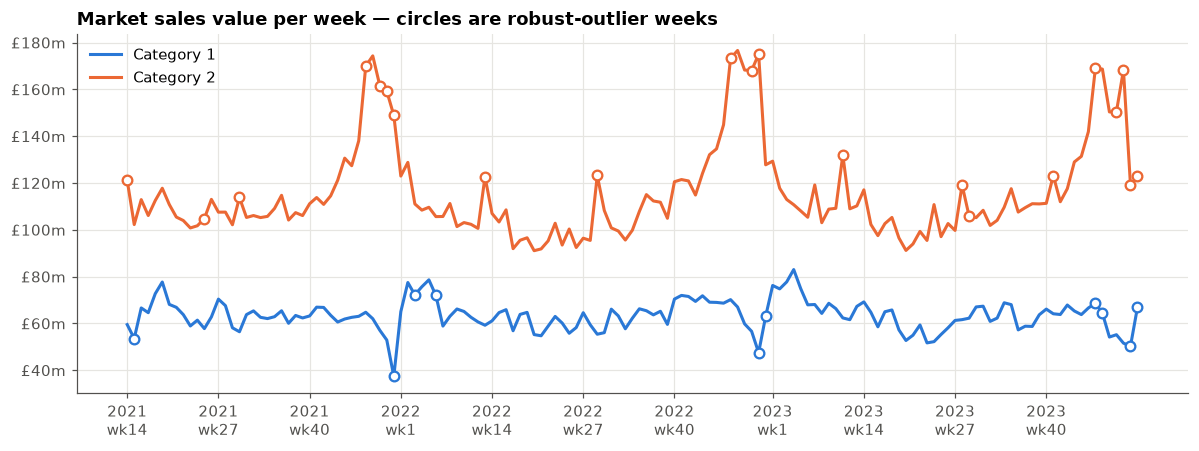

In [15]:
# Visual check: market weekly value by category, flagged weeks marked
mw = q("SELECT yr, wk, category, mkt_value, yr*100+wk AS yrwk FROM stg_market_weekly WHERE NOT (yr=2021 AND wk=53) ORDER BY yrwk")
mw["date_idx"] = mw.groupby("category").cumcount()
fl = outliers.assign(yrwk=outliers.yr*100+outliers.wk).merge(mw, on=["yrwk","category"])

fig, ax = plt.subplots()
for cat, g in mw.groupby("category"):
    ax.plot(g.date_idx, g.mkt_value, color=CAT_COL[cat], label=cat)
    f = fl[fl.category == cat]
    ax.scatter(f.date_idx, f.mkt_value, s=40, facecolor="white", edgecolor=CAT_COL[cat], linewidth=1.5, zorder=3)
ticks = mw[(mw.category=="Category 1") & (mw.wk.isin([14, 27, 40]) | (mw.wk==1))]
ax.set_xticks(ticks.date_idx, [f"{y}\nwk{w}" for y, w in zip(ticks.yr, ticks.wk)])
ax.yaxis.set_major_formatter(gbp_m)
ax.set_title("Market sales value per week — circles are robust-outlier weeks")
ax.legend(loc="upper left")
save(fig, "dq_outliers")

Outliers: a seasonality-aware test (each week vs its 7-week neighbourhood, robust z-score > 3.5) flags 31 weeks, 8 on sales value and 23 on price per unit. They’re almost all recurring retail events: Christmas (Category 2 price per unit falls to £5–6 as cheap items dominate; Category 1 dips in Christmas week), Black Friday (higher price per unit), and spikes in March and mid-July. Because they repeat every year, they’re genuine trading patterns, not data errors. They’re kept and flagged as event weeks, not deleted.

### 4.7b Distributions — weekly market value and price per unit, by category and year
Box plots show the typical week (median), the middle 50% of weeks (the box), and the spread.
Every week is also plotted as a dot, so nothing is hidden. Two things to check:
1. **Stability:** is the typical week similar across years, or has the level shifted?
2. **Tails:** are extreme weeks rare, explainable events (peaks, sales), or a sign of bad data?

Note: 2021 covers April–December only (no January), so its distribution is not fully comparable.
The copied week (2021 wk53) is excluded so it is not counted twice.

In [16]:
dist_stats = q('''
WITH base AS (
    SELECT yr, category,
           mkt_value,
           mkt_value / mkt_volume AS mkt_asp
    FROM stg_market_weekly
    WHERE NOT (yr = 2021 AND wk = 53)            -- exclude the copied week
),
long AS (
    UNPIVOT base ON mkt_value, mkt_asp INTO NAME measure VALUE val
),
s AS (
    SELECT measure, category, yr,
           COUNT(*)                     AS weeks,
           MIN(val)                     AS min_val,
           QUANTILE_CONT(val, 0.25)     AS q1,
           MEDIAN(val)                  AS median_val,
           QUANTILE_CONT(val, 0.75)     AS q3,
           MAX(val)                     AS max_val,
           STDDEV_SAMP(val) / AVG(val)  AS cv            -- coefficient of variation: spread relative to the mean
    FROM long
    GROUP BY measure, category, yr
)
SELECT s.*,
       q3 - q1 AS iqr,
       -- weeks outside the standard box-plot fences (1.5 x IQR beyond the box)
       (SELECT COUNT(*) FROM long l
        WHERE l.measure = s.measure AND l.category = s.category AND l.yr = s.yr
          AND (l.val < s.q1 - 1.5 * (s.q3 - s.q1) OR l.val > s.q3 + 1.5 * (s.q3 - s.q1))) AS weeks_outside_fences
FROM s
ORDER BY measure DESC, category, yr
''')

fmt_value = lambda v: f"£{v/1e6:,.1f}m"
fmt_asp   = lambda v: f"£{v:,.2f}"
show = dist_stats.copy()
for c in ["min_val", "q1", "median_val", "q3", "max_val", "iqr"]:
    show[c] = [fmt_value(v) if m == "mkt_value" else fmt_asp(v) for v, m in zip(show[c], show.measure)]
show["cv"] = show["cv"].map("{:.1%}".format)
display(show)

,measure,category,yr,weeks,min_val,q1,median_val,q3,max_val,cv,iqr,weeks_outside_fences
0,mkt_value,Category 1,2021,39,£37.4m,£60.3m,£62.9m,£65.4m,£77.7m,10.1%,£5.1m,2
1,mkt_value,Category 1,2022,53,£47.5m,£59.4m,£63.8m,£68.6m,£78.6m,9.8%,£9.2m,0
2,mkt_value,Category 1,2023,53,£50.3m,£58.7m,£64.1m,£67.4m,£83.0m,10.9%,£8.7m,1
3,mkt_value,Category 2,2021,39,£100.8m,£105.6m,£110.9m,£119.4m,£174.3m,16.6%,£13.8m,5
4,mkt_value,Category 2,2022,53,£91.1m,£100.3m,£108.3m,£122.7m,£176.6m,19.5%,£22.4m,5
5,mkt_value,Category 2,2023,53,£91.2m,£104.1m,£110.2m,£119.2m,£169.0m,15.9%,£15.1m,6
6,mkt_asp,Category 1,2021,39,£36.25,£37.29,£38.81,£39.62,£42.68,3.8%,£2.34,0
7,mkt_asp,Category 1,2022,53,£39.75,£42.06,£42.93,£44.31,£46.81,4.1%,£2.25,0
8,mkt_asp,Category 1,2023,53,£39.79,£42.98,£44.49,£45.76,£50.40,4.9%,£2.79,1
9,mkt_asp,Category 2,2021,39,£5.01,£7.25,£7.33,£7.56,£8.43,8.1%,£0.30,6


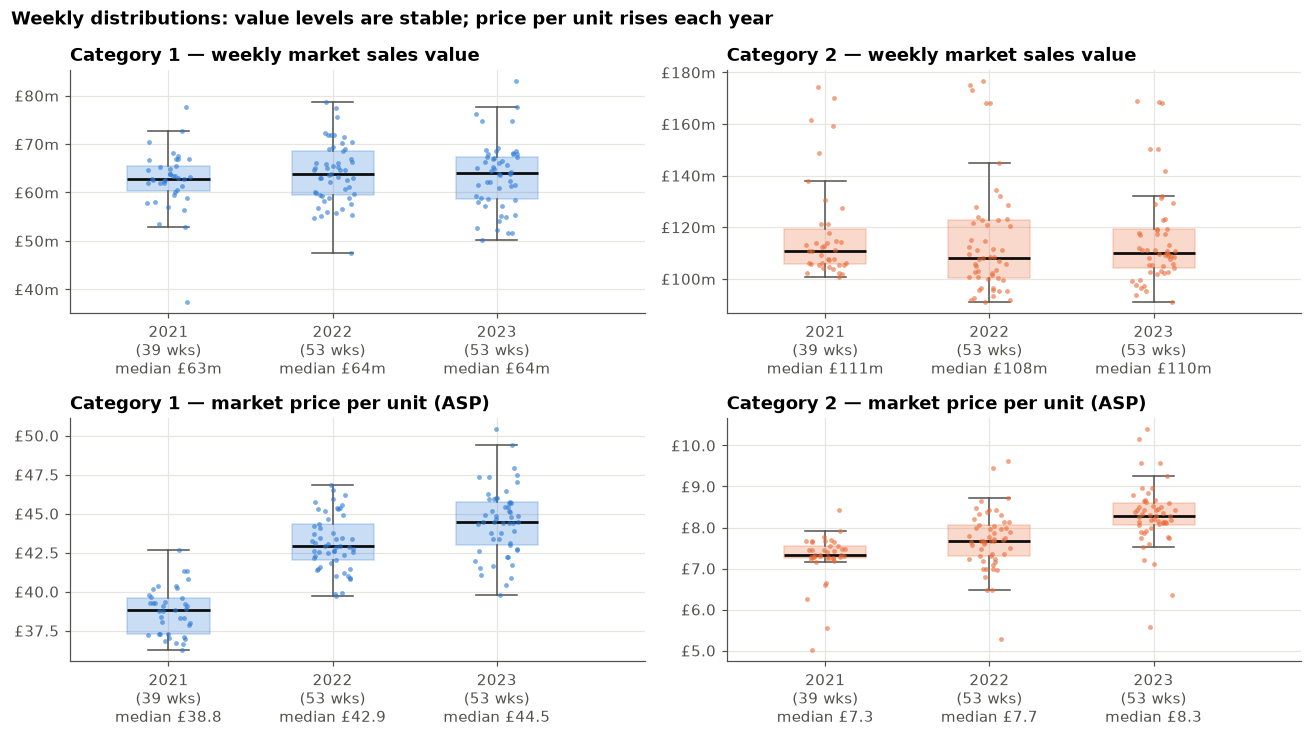

In [17]:
dist = q('''
SELECT yr, category, mkt_value, mkt_value / mkt_volume AS mkt_asp
FROM stg_market_weekly
WHERE NOT (yr = 2021 AND wk = 53)
''')

rng_jitter = np.random.default_rng(0)
years = sorted(dist.yr.unique())
panels = [("mkt_value", "weekly market sales value", gbp_m),
          ("mkt_asp",   "market price per unit (ASP)", mtick.FuncFormatter(lambda x, _: f"£{x:,.1f}"))]

fig, axes = plt.subplots(2, 2, figsize=(12, 6.8))
for j, cat in enumerate(["Category 1", "Category 2"]):
    for i, (col, title, fmt) in enumerate(panels):
        ax = axes[i, j]
        data = [dist[(dist.category == cat) & (dist.yr == y)][col].values for y in years]

        bp = ax.boxplot(data, positions=range(len(years)), widths=0.5, patch_artist=True,
                        showfliers=False,                       # every week is drawn as a dot below instead
                        medianprops=dict(color=C["ink"], lw=1.8),
                        whiskerprops=dict(color=C["ink2"]), capprops=dict(color=C["ink2"]))
        for box in bp["boxes"]:
            box.set(facecolor=CAT_COL[cat], alpha=0.25, edgecolor=CAT_COL[cat])

        for k, d in enumerate(data):                            # each week as a dot, slightly jittered
            ax.scatter(k + rng_jitter.uniform(-0.13, 0.13, len(d)), d, s=10,
                       color=CAT_COL[cat], alpha=0.6, zorder=3, linewidths=0)

        ax.set_xticks(range(len(years)), 
                      [f"{y}\n({len(d)} wks)\nmedian {fmt(np.median(d), None)}" for y, d in zip(years, data)])
        ax.set_xlim(-0.6, len(years) - 0.1)
        ax.yaxis.set_major_formatter(fmt)
        ax.set_title(f"{cat} — {title}")

fig.suptitle("Weekly distributions: value levels are stable; price per unit rises each year",
             x=0.01, ha="left", fontweight="bold")
save(fig, "dq_distributions")

n_out = int(dist_stats.weeks_outside_fences.sum())
log("stg_market_weekly", "Distributions by category & year (box plots, 1.5×IQR fences)",
    f"{n_out} category-weeks outside the fences; typical weekly value stable across years, ASP rising",
    "WARN" if n_out else "PASS",
    "Keep: tail weeks are the peak/sale weeks already flagged in 4.7")

Distributions: The data is well behaved, and the chart title holds.

Value is flat: the typical week is about £64m in Category 1 and £108–111m in Category 2, within ±2% across 2021–2023.
Price per unit rises every year: Category 1 +10.6% then +3.6%, Category 2 +4.8% then +7.8%. The whole distribution shifts, so this is broad-based inflation, not a few unusual weeks.
Flat value with rising prices means falling volume. That supports the Q2 finding: the market is being held up by price, not demand.
Category 2 is about twice as seasonal as Category 1. Its extreme weeks are recurring events: Christmas (high value, low price per unit) and Black Friday (high price per unit). They’re kept, not removed.

### 4.8 Cross-source reconciliation — internal vs market data
The Internal Data is described as a more detailed view of Dunelm sales. If it reconciles to the Dunelm columns in Market Data 1, it (a) validates both sources and (b) tells us **which** copy of the duplicated week is genuine.

In [18]:
recon = q('''
WITH mkt_as_delivered AS (
    SELECT yr, SUM(dun_value) AS mkt_file_dunelm_value, SUM(dun_volume) AS mkt_file_dunelm_units
    FROM stg_market_weekly GROUP BY yr
),
internal AS (
    SELECT yr, SUM(sales_value) AS internal_value, SUM(units) AS internal_units
    FROM stg_internal GROUP BY yr
)
SELECT i.yr,
       ROUND(m.mkt_file_dunelm_value, 2) AS market_file_value,
       ROUND(i.internal_value, 2)        AS internal_value,
       ROUND(i.internal_value - m.mkt_file_dunelm_value, 2) AS value_diff,
       ROUND(m.mkt_file_dunelm_units)    AS market_file_units,
       ROUND(i.internal_units)           AS internal_units,
       ROUND(i.internal_units / m.mkt_file_dunelm_units, 3) AS units_ratio
FROM internal i JOIN mkt_as_delivered m USING (yr)
ORDER BY yr
''')
display(recon)
log("cross-source", "Internal sales value = Dunelm value in market file",
    f"Match to within £{recon.value_diff.abs().max():.2f} (rounding) for 2022 (incl. wk1) and 2023 (53 weeks)", "PASS",
    "Confirms 2022 wk1 is genuine → 2021 wk53 is the copy; 53-week years are as reported")
log("cross-source", "Internal units vs market-file units",
    f"Units match exactly (ratio {recon.units_ratio.mean():.3f})", "PASS")

,yr,market_file_value,internal_value,value_diff,market_file_units,internal_units,units_ratio
0,2022,"762,481,795.8700","762,481,795.8100",-0.0600,"52,574,336.0000","52,574,336.0000",1.0000
1,2023,"806,635,567.2000","806,635,567.1800",-0.0200,"54,760,406.0000","54,760,406.0000",1.0000


Sum-up

Cross-source reconciliation: Dunelm’s sales in the market file match its internal sales to within 6p, and units match exactly, for both 2022 and 2023. This gives high confidence in the Dunelm figures. It also resolves the duplicate: 2022 week 1 is needed for the totals to match, so it’s genuine, and 2021 week 53 is the copy to remove. The 53-week years are real and are kept. The check covers annual Dunelm totals only; the rest of the market figures have no second source to compare against.


2021 ends with week 52, on Saturday 25 December 2021.</br>
2022 starts with week 1, on Sunday 26 December 2021.

### 4.9 Dimension alignment — social grades across sources

In [19]:
display(q('''
SELECT 'Internal Data' AS source, social_grade AS label FROM (SELECT DISTINCT social_grade FROM stg_internal)
UNION ALL
SELECT 'Market Data 2', demographic FROM (SELECT DISTINCT demographic FROM stg_market_hh)
ORDER BY 1, 2
''').groupby("source")["label"].apply(list).to_frame())

log("cross-source", "Social grade labels", "Internal has A and B separately; Market Data 2 has combined AB", "WARN",
    "Map A, B → AB to compare; harmonise labels to AB/C1/C2/D/E")
log("cross-source", "Customers vs households", "Internal 'customers' (6.5m) ≠ Market Data 2 Dunelm households (8.2m)", "WARN",
    "Separate sources, different units and periods — compare ratios and mixes, never join absolute counts")

,label
source,
Internal Data,"[Social grade A, Social grade B, Social grade ..."
Market Data 2,"[Class AB, Class C1, Class C2, Class D, Class E]"


In [20]:
mix_check = q('''
WITH internal AS (
    SELECT CASE WHEN social_grade IN ('Social grade A','Social grade B') THEN 'AB'
                ELSE REPLACE(social_grade, 'Social grade ', '') END AS grade_group,
           SUM(customers) AS n
    FROM stg_internal WHERE yr = 2023 GROUP BY 1
),
panel AS (
    SELECT REPLACE(demographic, 'Class ', '') AS grade_group, households AS n
    FROM stg_market_hh WHERE retailer = 'Dunelm'
)
SELECT i.grade_group,
       i.n / SUM(i.n) OVER () AS internal_customer_mix,
       p.n / SUM(p.n) OVER () AS panel_household_mix,
       (i.n / SUM(i.n) OVER () - p.n / SUM(p.n) OVER ()) * 100 AS gap_pp
FROM internal i JOIN panel p USING (grade_group)
ORDER BY CASE i.grade_group WHEN 'AB' THEN 1 WHEN 'C1' THEN 2 WHEN 'C2' THEN 3 WHEN 'D' THEN 4 ELSE 5 END
''')
display(mix_check.style.format({"internal_customer_mix": "{:.1%}", "panel_household_mix": "{:.1%}",
                                "gap_pp": "{:+.1f}pp"}).hide(axis="index"))

log("cross-source", "Grade mix: internal customers vs panel households",
    f"Largest gap {mix_check.gap_pp.abs().max():.1f}pp (C1 over-represented internally, D/E under)", "WARN",
    "Grade likely assigned differently by each source: use panel for reach, internal for value; never combine")

grade_group,internal_customer_mix,panel_household_mix,gap_pp
AB,24.7%,28.0%,-3.3pp
C1,50.0%,31.7%,+18.3pp
C2,11.5%,14.6%,-3.2pp
D,9.3%,16.8%,-7.5pp
E,4.5%,8.8%,-4.4pp


<b>Sum-up</b>

Dimension alignment: The two sources label social grade differently (“Social grade A/B…” vs “Class AB…”), and only the internal data splits A from B. Both are harmonised to AB, C1, C2, D, E in the cleaning step. </br>
<b>Internal customers (6.5m) </b> and panel households (8.2m) measure different things from different sources and periods, and even their grade mixes differ (C1 is 50% internally vs 32% in the panel). So each source is used only for what it measures: the panel for reach, internal data for customer value. <b>Their numbers are never combined.</b>

### 4.10 Data quality register

In [21]:
dq = pd.DataFrame(dq_log)
def colour_status(s):
    return [{"PASS":"background-color:#e3f4ea","WARN":"background-color:#fdf1d6","FAIL":"background-color:#fbe1e1"}.get(v,"") for v in s]
display(dq.style.apply(colour_status, subset=["status"]).hide(axis="index"))
print(dq.status.value_counts().to_dict())

dataset,check,result,status,action
stg_market_weekly,Null values,0 rows with nulls,PASS,None needed
stg_internal,Null values,0 rows with nulls,PASS,None needed
stg_market_hh,Null values,0 rows with nulls,PASS,None needed
stg_market_weekly,Unique at grain,0 duplicate keys,PASS,None needed
stg_internal,Unique at grain,0 duplicate keys,PASS,None needed
stg_market_hh,Unique at grain,0 duplicate keys,PASS,None needed
stg_internal,Full dimensional cube,72 of 72 combinations,PASS,None needed
stg_market_weekly,Copied weeks (identical measures),2 rows: 2021 wk53 is identical to 2022 wk1 (both categories),FAIL,"Drop 2021 wk53 — see reconciliation in 4.8 for why this copy, not 2022 wk1"
stg_market_weekly,Partial year,"2021 starts at week 14 (Apr) — 40 week labels, 39 real weeks after removing the copy",WARN,Use full years 2022 vs 2023 for headline YoY; weeks 14–52 for 3-year like-for-like
stg_market_weekly,53-week years,2022 and 2023 both contain a week 53,WARN,Keep (internal sales reconcile to 53 weeks); test a 52-week sensitivity


{'PASS': 13, 'WARN': 8, 'FAIL': 1}


> **So what (data):** the data is high quality and the three sources are coherent. One material defect — a **copied week** (2021 wk53 = 2022 wk1) — would have overstated 2021 market sales by ~£188m (Dunelm by ~£20m) if left in. The exact reconciliation between internal and market data gives high confidence in the Dunelm numbers. Remaining caveats (partial 2021, 53-week years, grade labels, unlinked household panel) are handled by design choices rather than data edits.

> **Data quality register: 22 checks, 13 PASS, 8 WARN, 1 FAIL.**

>**PASS (13):** no nulls, no duplicate keys, a complete internal data cube, no gaps in the weeks, all business rules hold (positive values, Dunelm ≤ market, customers ≤ orders ≤ units), and Dunelm’s sales and units reconcile exactly to internal data.</br>
**FAIL (1):** one duplicated week. The Christmas–New Year week (26 Dec 2021 – 1 Jan 2022) is listed as both 2021 wk53 and 2022 wk1. It’s kept once, in 2022, so no sales are lost.</br>
**WARN (8):** partial 2021, 53-week years, week→month shifts, recurring event weeks (outliers and distribution tails), grade labels (A/B vs AB), customers vs households, and different grade mixes between the two sources. All are handled by how the analysis is designed, not by changing the data.</br>

> **Conclusion:** the data is reliable. One defect is fixed, and every caveat has a documented action.

## 5. Cleaning — build the `clean_*` layer
Rules applied (each traceable to the DQ register):
1. Drop the copied week **2021 wk53**.
2. Add a continuous week index (`week_idx`), flags for full years and the like-for-like window (weeks 14–52, the same 39 weeks in every year), and event weeks from 4.7.
3. Derive share, average selling price (ASP) and *rest-of-market* (market excluding Dunelm) — the right benchmark for "is Dunelm out-performing?".
4. Harmonise social grades (A, B → AB) and label the price-seeker flag.

In [22]:
con.register("outlier_weeks", outliers[["yr","wk","category"]])

run('''
CREATE OR REPLACE TABLE clean_market_weekly AS
WITH f AS (
    SELECT * FROM stg_market_weekly
    WHERE NOT (yr = 2021 AND wk = 53)                         -- Rule 1
)
SELECT
    f.*,
    DENSE_RANK() OVER (ORDER BY yr, wk)            AS week_idx,           -- Rule 2
    yr IN (2022, 2023)                             AS is_full_year,
    wk BETWEEN 14 AND 52                           AS is_lfl_window,      -- same 39 weeks in every year    
    (o.yr IS NOT NULL)                             AS is_event_week,
    mkt_value - dun_value                          AS rom_value,          -- Rule 3: rest of market
    mkt_volume - dun_volume                        AS rom_volume,
    dun_value  / mkt_value                         AS dun_value_share,
    dun_volume / mkt_volume                        AS dun_volume_share,
    mkt_value  / mkt_volume                        AS mkt_asp,
    dun_value  / dun_volume                        AS dun_asp
FROM f
LEFT JOIN outlier_weeks o USING (yr, wk, category)
''')

run('''
CREATE OR REPLACE TABLE clean_internal AS
SELECT
    yr, segment, social_grade,
    REPLACE(social_grade, 'Social grade ', '')                                AS grade,
    CASE WHEN social_grade IN ('Social grade A','Social grade B') THEN 'AB'
         ELSE REPLACE(social_grade, 'Social grade ', '') END                  AS grade_group,   -- Rule 4
    price_seeker_flag,
    CASE price_seeker_flag WHEN 1 THEN 'Price seeker' ELSE 'Not price seeker' END AS shopper_type,
    customers, orders, units, sales_value
FROM stg_internal
''')

run('''
CREATE OR REPLACE TABLE clean_market_hh AS
SELECT retailer, REPLACE(demographic, 'Class ', '') AS grade_group, households
FROM stg_market_hh
WHERE demographic_type = 'Social Class'
''')

# Post-clean assertions
chk = q("SELECT COUNT(*) n, COUNT(DISTINCT week_idx) w, SUM(CASE WHEN yr=2021 AND wk=53 THEN 1 ELSE 0 END) dup FROM clean_market_weekly")
assert chk.dup[0] == 0 and chk.n[0] == 2 * chk.w[0] == 290
recon_after = q('''SELECT m.yr, ROUND(SUM(m.dun_value)-ANY_VALUE(i.v),2) diff FROM clean_market_weekly m
                   JOIN (SELECT yr, SUM(sales_value) v FROM clean_internal GROUP BY yr) i USING (yr) GROUP BY m.yr''')
assert (recon_after["diff"].abs() < 1).all()   # pennies of rounding
print("clean_market_weekly:", chk.n[0], "rows,", chk.w[0], "weeks ✓ | internal reconciles after cleaning ✓")
print("2021 value removed by dropping the copied week: £{:,.1f}m".format(dupe_content.dun_value.sum()/1e6), "(Dunelm),",
      "£{:,.1f}m (market)".format(dupe_content.mkt_value.sum()/1e6))

clean_market_weekly: 290 rows, 145 weeks ✓ | internal reconciles after cleaning ✓
2021 value removed by dropping the copied week: £19.9m (Dunelm), £188.0m (market)


> **Sum-up**

> **Cleaning:** applies the register’s decisions in three clean tables.

> **Weekly market data:** the duplicated week is removed (290 rows remain, 2 per week). Flags are added for full years, the like-for-like window and event weeks, along with derived measures: rest-of-market, value and volume share, and price per unit.
Internal data: grades are shortened and harmonised (A + B → AB), and the price-seeker flag is labelled.
Households: grade labels match the internal data.

Built-in checks confirm no duplicate remains, every week has both categories, and Dunelm’s sales still reconcile to internal data after cleaning.

## 5b. Exploratory overview

### 5b.1 Customer KPIs by social grade
Spend per customer breaks down into two parts:
**Spend per customer = Orders per customer × Average order value (AOV)**.
Showing all four KPIs side by side tells us not just *which* grades are worth more, but *why*:
because they shop more often, or because they spend more per order.
Bars are 2023; white dots are 2022.

,customers_2023,customer_mix,sales_mix,spend_per_customer,index_vs_avg,customers_chg,freq_chg,aov_chg,spend_chg
grade,,,,,,,,,
A,"171,013",2.6%,3.5%,£163.51,132,+1.4%,+5.6%,-2.3%,+3.2%
B,"1,440,460",22.1%,24.5%,£137.28,111,+0.2%,+4.3%,-5.0%,-0.9%
C1,"3,264,850",50.0%,48.7%,£120.28,97,+4.7%,+6.4%,-4.0%,+2.2%
C2,"748,718",11.5%,11.2%,£120.27,97,+3.0%,+8.8%,-4.8%,+3.5%
D,"609,326",9.3%,8.4%,£110.89,90,+5.8%,+11.1%,-1.8%,+9.1%
E,"290,967",4.5%,3.8%,£105.23,85,+5.5%,+11.1%,-2.3%,+8.6%


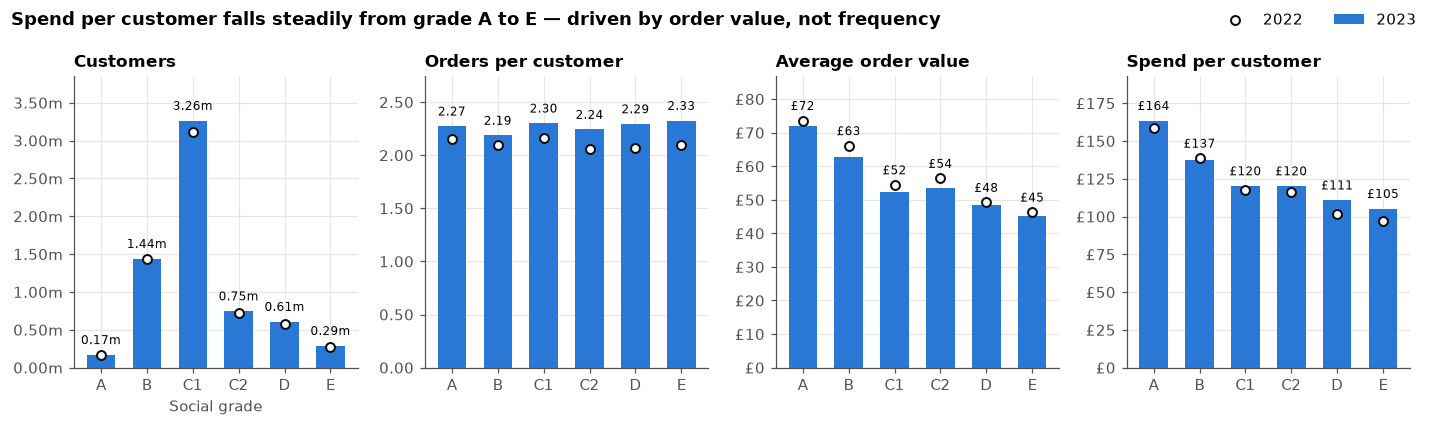

In [23]:
grade_kpi = q('''
SELECT yr, grade,
       SUM(customers)                       AS customers,
       SUM(orders)                          AS orders,
       SUM(sales_value)                     AS sales_value,
       SUM(orders)      / SUM(customers)    AS orders_per_customer,
       SUM(sales_value) / SUM(orders)       AS aov,
       SUM(sales_value) / SUM(customers)    AS spend_per_customer,
       SUM(customers)   / SUM(SUM(customers))   OVER (PARTITION BY yr) AS customer_mix,
       SUM(sales_value) / SUM(SUM(sales_value)) OVER (PARTITION BY yr) AS sales_mix
FROM clean_internal
GROUP BY yr, grade
ORDER BY yr, grade
''')

g23 = grade_kpi[grade_kpi.yr == 2023].set_index("grade")
g22 = grade_kpi[grade_kpi.yr == 2022].set_index("grade")
chg = pd.DataFrame({
    "customers_2023": g23.customers,
    "customer_mix": g23.customer_mix, "sales_mix": g23.sales_mix,
    "spend_per_customer": g23.spend_per_customer,
    "index_vs_avg": 100 * g23.spend_per_customer / (g23.sales_value.sum() / g23.customers.sum()),
    "customers_chg": g23.customers / g22.customers - 1,
    "freq_chg": g23.orders_per_customer / g22.orders_per_customer - 1,
    "aov_chg": g23.aov / g22.aov - 1,
    "spend_chg": g23.spend_per_customer / g22.spend_per_customer - 1,
})
display(chg.style.format({"customers_2023": "{:,.0f}", "customer_mix": "{:.1%}", "sales_mix": "{:.1%}",
                          "spend_per_customer": "£{:.2f}", "index_vs_avg": "{:.0f}",
                          "customers_chg": "{:+.1%}", "freq_chg": "{:+.1%}", "aov_chg": "{:+.1%}", "spend_chg": "{:+.1%}"}))

panels = [("customers",           "Customers",               lambda v: f"{v/1e6:.2f}m"),
          ("orders_per_customer", "Orders per customer",     lambda v: f"{v:.2f}"),
          ("aov",                 "Average order value",     lambda v: f"£{v:.0f}"),
          ("spend_per_customer",  "Spend per customer",      lambda v: f"£{v:.0f}")]
grades = list(g23.index)
x = np.arange(len(grades))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.9))
for ax, (col, title, fmt) in zip(axes, panels):
    ax.bar(x, g23[col], width=0.62, color=C["dunelm"], label="2023")
    ax.scatter(x, g22[col], s=34, facecolor="white", edgecolor=C["ink"], linewidth=1.3, zorder=3, label="2022")
    for xi, v, v_prev in zip(x, g23[col], g22[col]):
        ax.annotate(fmt(v), (xi, max(v, v_prev)), xytext=(0, 5), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x, grades)
    ax.set_ylim(0, max(g23[col].max(), g22[col].max()) * 1.18)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _, f=fmt: f(v)))
    ax.set_title(title, fontsize=11)
axes[0].set_xlabel("Social grade")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", ncols=2)
fig.suptitle("Spend per customer falls steadily from grade A to E — driven by order value, not frequency",
             x=0.01, ha="left", fontweight="bold")
save(fig, "eda_kpis_by_grade")

> **Customer KPIs by social grade: sum-up**

> **C1 is the core:** 3.26m customers, 50% of customers and 49% of sales. Any growth plan has to work for C1.
Every grade shops equally often: about 2.2–2.3 orders per customer in all grades.</br>
> **Value is driven by basket size:** average order value falls from £72 (A) to £45 (E), so spend per customer falls from £164 to £105. Grade A customers are worth 32% more than average, grade E 15% less.</br>
> <b> Smaller baskets everywhere: </b> order value fell in every grade in 2023 (−1.8% to −5.0%). Customers shopped more often (+4% to +11%) but spent less per order, so basket building is a business-wide lever.</br>
> <b> D and E are growing fastest: </b> customers +5.5–5.8%, frequency +11%, spend per customer +9%. Dunelm’s value offer is landing with price-conscious households.</br>
<b>B </b> is the only grade where spend per customer fell (−0.9%), because it had the biggest drop in order value (−5.0%).

### 5b.2 Where the value sits: segment × social grade
Each cell is one group of customers (segment × grade). Left: spend per customer in 2023, with the number of customers.
Right: change in spend per customer vs 2022 (blue = up, red = down, grey = no change).

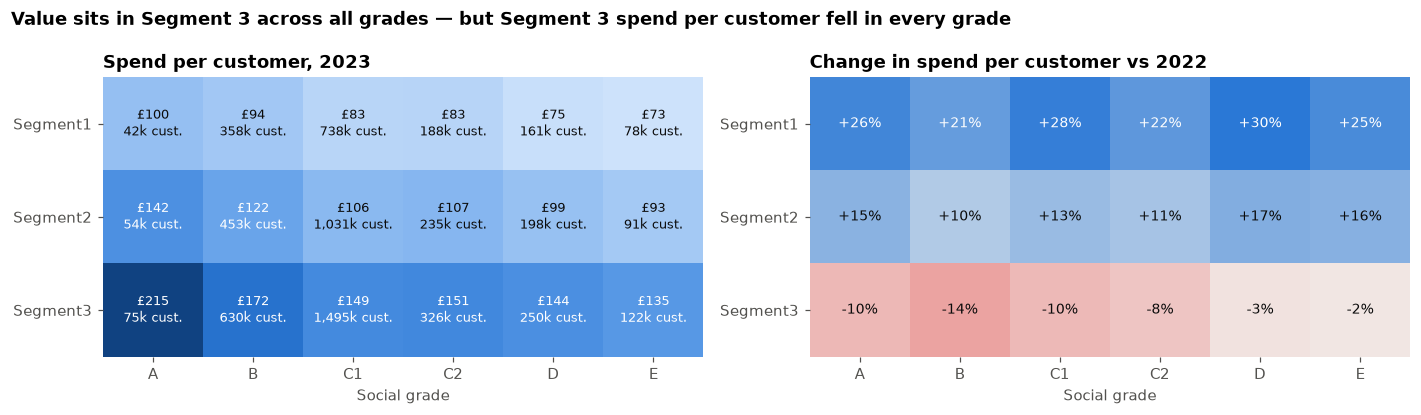

grade,A,B,C1,C2,D,E
segment,,,,,,
Segment1,+26.0%,+20.7%,+27.9%,+21.8%,+29.7%,+25.0%
Segment2,+15.4%,+9.6%,+13.1%,+11.2%,+16.7%,+15.9%
Segment3,-10.0%,-13.9%,-9.9%,-7.8%,-2.6%,-2.0%


In [24]:
# 5b.2 Segment x grade heatmap: spend per customer (2023) and change vs 2022
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

hm = q('''
SELECT yr, segment, grade,
       SUM(customers)                    AS customers,
       SUM(sales_value) / SUM(customers) AS spend_per_customer
FROM clean_internal
GROUP BY yr, segment, grade
''')
spc23 = hm[hm.yr == 2023].pivot(index="segment", columns="grade", values="spend_per_customer")
spc22 = hm[hm.yr == 2022].pivot(index="segment", columns="grade", values="spend_per_customer")
cust23 = hm[hm.yr == 2023].pivot(index="segment", columns="grade", values="customers")
chg = spc23 / spc22 - 1

seq = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#6da7ec", "#2a78d6", "#104281"])
div = LinearSegmentedColormap.from_list("div", ["#e34948", "#f3f2ef", "#2a78d6"])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
# Left: level (sequential, one hue)
ax = axes[0]
im = ax.imshow(spc23.values, cmap=seq, aspect="auto")
for i in range(spc23.shape[0]):
    for j in range(spc23.shape[1]):
        v = spc23.values[i, j]
        dark = v > np.nanpercentile(spc23.values, 55)
        ax.text(j, i, f"£{v:,.0f}\n{cust23.values[i, j]/1e3:,.0f}k cust.", ha="center", va="center",
                fontsize=8.5, color="white" if dark else C["ink"])
ax.set_title("Spend per customer, 2023")
# Right: change (diverging, grey midpoint at 0)
ax = axes[1]
lim = np.nanmax(np.abs(chg.values))
im2 = ax.imshow(chg.values, cmap=div, norm=TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim), aspect="auto")
for i in range(chg.shape[0]):
    for j in range(chg.shape[1]):
        v = chg.values[i, j]
        ax.text(j, i, f"{v:+.0%}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > lim * 0.6 else C["ink"])
ax.set_title("Change in spend per customer vs 2022")
for ax in axes:
    ax.set_xticks(range(spc23.shape[1]), spc23.columns)
    ax.set_yticks(range(spc23.shape[0]), spc23.index)
    ax.set_xlabel("Social grade")
    ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
fig.suptitle("Value sits in Segment 3 across all grades — but Segment 3 spend per customer fell in every grade",
             x=0.01, ha="left", fontweight="bold")
save(fig, "eda_heatmap_segment_grade")
display(chg.style.format("{:+.1%}"))

### 5b.2 Results: where the value sits

- **Segment 3 is the most valuable group in every grade.** Spend per customer ranges from **£135 (E) to £215 (A)**, well above Segments 1 and 2 in the same grade. The biggest single block is **Segment 3 × C1: 1.5m customers at £149 each**.
- **Value rises with both segment and grade.** The top-left (Segment 1, grade E, £73) is worth less than a third of the bottom-left corner (Segment 3, grade A, £215).
- **The change is driven by segment, not grade:**
  - **Segment 1:** spend per customer **up 21–30% in every grade**.
  - **Segment 2:** **up 10–17% in every grade**.
  - **Segment 3:** **down in every grade**, from −2% (E) to **−14% (B)**.
- **Segment 3's decline is steepest in the higher grades** (A −10%, B −14%, C1 −10%) and mild in D/E (−2 to −3%). The basket problem is concentrated among the highest-value customers.
- **Caveat:** if segments are defined by how often customers shop, part of this pattern can be **customers moving between segments**. New entrants to Segment 3 (+9.7% customers) may bring lower spend and dilute its average. The direction is clear; the exact size of the decline should be treated with care.

> **So what:** Dunelm's most valuable customers (Segment 3, especially grades A–C1) are where spend per customer is falling. The pattern is the same in every grade, so it's about **how the loyal core shops** (fewer items per basket, 6.7), not who they are. Protecting basket size in Segment 3 is the priority lever.

### 5b.3 Price seekers vs other customers, by grade
"Price seekers" answered yes to *"I look for the lowest possible prices when I go shopping"*.
Left: how common they are in each grade. Right: whether they spend less than other customers in the same grade.

grade,pct_price_seekers,spc_price_seeker,spc_other,freq_price_seeker,freq_other,spend_gap
A,17%,£158.39,£164.56,2.31,2.27,-3.8%
B,8%,£132.18,£137.69,2.20,2.19,-4.0%
C1,40%,£119.43,£120.85,2.22,2.36,-1.2%
C2,27%,£120.18,£120.30,2.20,2.26,-0.1%
D,71%,£109.51,£114.21,2.26,2.37,-4.1%
E,48%,£103.95,£106.44,2.28,2.37,-2.3%
All,34%,£117.73,£126.65,2.23,2.29,-7.0%


Customer growth 2022→2023: price seekers +5.2%, others +2.7%


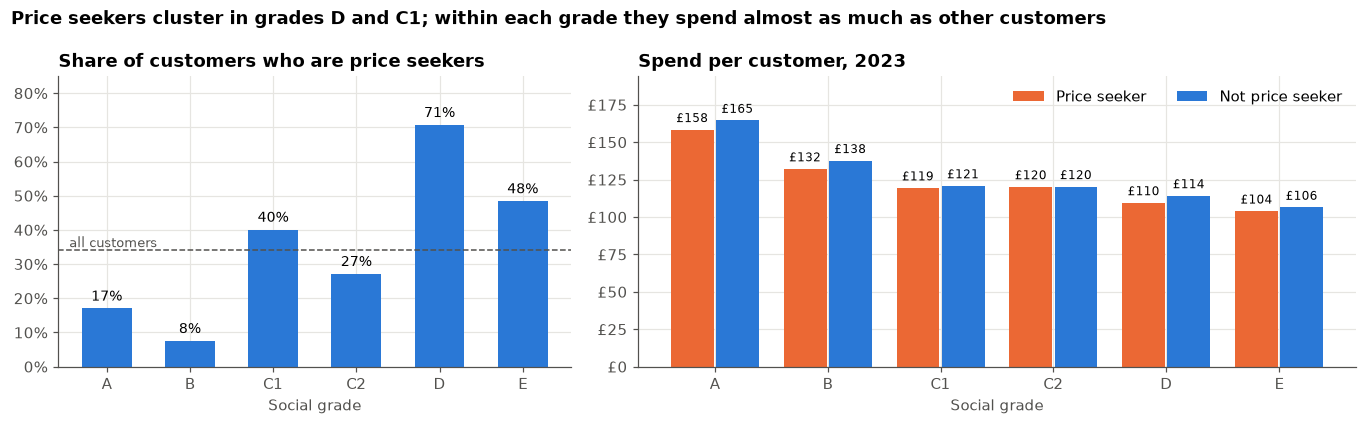

In [25]:
# 5b.3 Price seekers vs other customers, by grade (2023)
ps = q('''
SELECT grade,
       SUM(CASE WHEN price_seeker_flag = 1 THEN customers END) / SUM(customers)               AS pct_price_seekers,
       SUM(CASE WHEN price_seeker_flag = 1 THEN sales_value END)
         / SUM(CASE WHEN price_seeker_flag = 1 THEN customers END)                            AS spc_price_seeker,
       SUM(CASE WHEN price_seeker_flag = 0 THEN sales_value END)
         / SUM(CASE WHEN price_seeker_flag = 0 THEN customers END)                            AS spc_other,
       SUM(CASE WHEN price_seeker_flag = 1 THEN orders END)
         / SUM(CASE WHEN price_seeker_flag = 1 THEN customers END)                            AS freq_price_seeker,
       SUM(CASE WHEN price_seeker_flag = 0 THEN orders END)
         / SUM(CASE WHEN price_seeker_flag = 0 THEN customers END)                            AS freq_other
FROM clean_internal WHERE yr = 2023
GROUP BY ROLLUP (grade)
ORDER BY grade NULLS LAST
''')
ps["grade"] = ps["grade"].fillna("All")
ps["spend_gap"] = ps.spc_price_seeker / ps.spc_other - 1
display(ps.style.format({"pct_price_seekers": "{:.0%}", "spc_price_seeker": "£{:.2f}", "spc_other": "£{:.2f}",
                         "freq_price_seeker": "{:.2f}", "freq_other": "{:.2f}", "spend_gap": "{:+.1%}"}).hide(axis="index"))

growth = q('''
SELECT shopper_type,
       SUM(CASE WHEN yr = 2023 THEN customers END) / SUM(CASE WHEN yr = 2022 THEN customers END) - 1 AS customer_growth
FROM clean_internal GROUP BY shopper_type
''').set_index("shopper_type").customer_growth
print(f"Customer growth 2022→2023: price seekers {growth['Price seeker']:+.1%}, others {growth['Not price seeker']:+.1%}")

g = ps[ps.grade != "All"]
x = np.arange(len(g))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
bars = ax.bar(x, g.pct_price_seekers, color=C["dunelm"], width=0.6)
for b, v in zip(bars, g.pct_price_seekers):
    ax.annotate(f"{v:.0%}", (b.get_x() + b.get_width()/2, v), xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=9)
ax.axhline(ps.set_index("grade").pct_price_seekers["All"], color=C["ink2"], ls="--", lw=1)
ax.text(-0.45, ps.set_index("grade").pct_price_seekers["All"], "all customers", va="bottom", ha="left",
        fontsize=8.5, color=C["ink2"])
ax.set_xticks(x, g.grade); ax.set_ylim(0, 0.85)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title("Share of customers who are price seekers")

ax = axes[1]; w = 0.38
b1 = ax.bar(x - w/2 - 0.01, g.spc_price_seeker, w, color=C["cat2"], label="Price seeker")
b2 = ax.bar(x + w/2 + 0.01, g.spc_other, w, color=C["dunelm"], label="Not price seeker")
for bars_, vals in [(b1, g.spc_price_seeker), (b2, g.spc_other)]:
    for b, v in zip(bars_, vals):
        ax.annotate(f"£{v:.0f}", (b.get_x() + b.get_width()/2, v), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, g.grade); ax.set_ylim(0, g[["spc_price_seeker", "spc_other"]].max().max() * 1.18)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"£{v:.0f}"))
ax.set_title("Spend per customer, 2023"); ax.legend(loc="upper right", ncols=2)
for a in axes: a.set_xlabel("Social grade")
fig.suptitle("Price seekers cluster in grades D and C1; within each grade they spend almost as much as other customers",
             x=0.01, ha="left", fontweight="bold")
save(fig, "eda_price_seekers_by_grade")

### 5b.3 Results: price seekers vs other customers

- **About 1 in 3 customers (34%) are price seekers**, very unevenly spread across grades:
  - **Grade D: 71%**, E: 48%, C1: 40%
  - Much lower in **C2 (27%), A (17%) and B (8%)**
  - The pattern doesn't follow affluence neatly (A has more price seekers than B, and C1 more than C2), so the flag reflects shopping attitude, not just income.
- **Overall, price seekers spend 7% less** (£118 vs £127 per customer). **But within each grade the gap is small, only 0–4%:**
  - C2: £120 vs £120 (−0.1%)
  - C1: £119 vs £121 (−1.2%)
  - D: £110 vs £114 (−4.1%)
- **The overall 7% gap is mostly a mix effect.** Price seekers are concentrated in grades that spend less (D, C1, E), so on average they look lower-value. Compared with similar households, being a price seeker barely changes how much someone spends at Dunelm.
- **Shopping frequency is almost the same** (2.23 vs 2.29 orders a year). Price seekers in C1–E shop slightly less often; in A and B there's no difference.
- **Price seekers are growing faster:** customers **+5.2%** vs +2.7% for others.

> **So what:** Price-conscious customers are **not low-value customers** for Dunelm. Within each grade they spend almost as much as everyone else, and they're the faster-growing group. This supports the **reach opportunity in C2/D/E households** (where Competitor B leads): winning value-conscious shoppers with a strong value message can add customers **without diluting spend per customer**. The guardrail is to compete on value perception (range, everyday price), not deeper discounts that shrink baskets.

### 5b.4 Customer mix vs sales mix by segment
Compares each segment's share of customers with its share of sales.
**Value index = share of sales ÷ share of customers × 100**: above 100 means the segment's customers are worth more than average.
Bars are 2023; white dots are 2022.

yr,segment,customer_mix,sales_mix,value_index
2022,Segment1,26.1%,14.6%,56
2023,Segment1,24.0%,16.4%,68
2022,Segment2,32.0%,25.8%,80
2023,Segment2,31.6%,27.9%,88
2022,Segment3,41.9%,59.6%,142
2023,Segment3,44.4%,55.6%,125


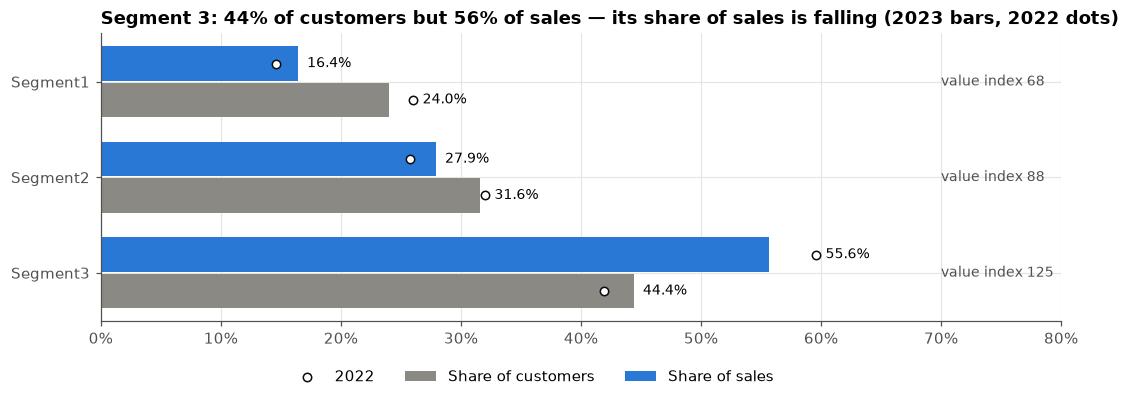

In [26]:
# 5b.4 Customer mix vs sales mix by segment
mix = q('''
SELECT yr, segment,
       SUM(customers)   / SUM(SUM(customers))   OVER (PARTITION BY yr) AS customer_mix,
       SUM(sales_value) / SUM(SUM(sales_value)) OVER (PARTITION BY yr) AS sales_mix
FROM clean_internal
GROUP BY yr, segment
ORDER BY segment, yr
''')
mix["value_index"] = 100 * mix.sales_mix / mix.customer_mix
display(mix.style.format({"customer_mix": "{:.1%}", "sales_mix": "{:.1%}", "value_index": "{:.0f}"}).hide(axis="index"))

m23 = mix[mix.yr == 2023].set_index("segment"); m22 = mix[mix.yr == 2022].set_index("segment")
y = np.arange(len(m23)); h = 0.36
fig, ax = plt.subplots(figsize=(10, 3.8))
b1 = ax.barh(y + h/2 + 0.01, m23.customer_mix, h, color=C["market"], label="Share of customers")
b2 = ax.barh(y - h/2 - 0.01, m23.sales_mix, h, color=C["dunelm"], label="Share of sales")
ax.scatter(m22.customer_mix, y + h/2 + 0.01, s=30, facecolor="white", edgecolor=C["ink"], zorder=3, label="2022")
ax.scatter(m22.sales_mix, y - h/2 - 0.01, s=30, facecolor="white", edgecolor=C["ink"], zorder=3)
for bars_, vals, prev in [(b1, m23.customer_mix, m22.customer_mix), (b2, m23.sales_mix, m22.sales_mix)]:
    for b, v, p in zip(bars_, vals, prev):
        ax.annotate(f"{v:.1%}", (max(v, p), b.get_y() + b.get_height()/2), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9)
for yi, (seg_name, r) in zip(y, m23.iterrows()):
    ax.text(0.70, yi, f"value index {r.value_index:.0f}", va="center", fontsize=9, color=C["ink2"])
ax.set_yticks(y, m23.index); ax.invert_yaxis()
ax.set_xlim(0, 0.8); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.12), ncols=3)
ax.set_title("Segment 3: 44% of customers but 56% of sales — its share of sales is falling (2023 bars, 2022 dots)")
save(fig, "eda_mix_by_segment")

### 5b.4 Results: customer mix vs sales mix by segment

- **Segment 3 is the core of the business:** **44% of customers but 56% of sales** in 2023. Its customers are worth **25% more than average** (value index 125).
- **But Segment 3 is losing value relative to its size:**
  - Share of customers **up** from 41.9% to 44.4% (+2.5pp)
  - Share of sales **down** from 59.6% to 55.6% (−4.0pp)
  - Value index fell sharply, **142 → 125**
  - It gained customers but each one spent less, the same basket problem seen in 6.7 and 5b.2.
- **Segments 1 and 2 became more valuable:**
  - **Segment 1:** customer share fell (26.1% → 24.0%) but sales share rose (14.6% → 16.4%); value index **56 → 68**.
  - **Segment 2:** sales share up from 25.8% to 27.9%; value index **80 → 88**.
- **The segments are converging:** the value gap between the most and least valuable segment narrowed from **142 vs 56** to **125 vs 68**. That's mainly because Segment 3 customers are spending less, and partly because lighter shoppers are spending more.
- **Caveat:** if segments are defined by shopping frequency, some of this shift reflects customers **moving between segments** (e.g. newer, lower-spending customers entering Segment 3), not only changes in behaviour.

> **So what:** Dunelm's sales are becoming **less concentrated in its most valuable segment**. That's partly healthy (lighter shoppers are spending more), but mostly a warning: the loyal core is growing in numbers while its value per customer falls. Restoring basket size in Segment 3 is worth more than any other single segment lever, because it covers over half of sales.

---
# Q1 · How is Dunelm performing in the context of the market?

### 6.1 Headline: full-year 2023 vs 2022

In [27]:
run('''
CREATE OR REPLACE TABLE mart_annual AS
WITH by_cat AS (
    SELECT yr, category,
           SUM(mkt_value) mkt_value, SUM(mkt_volume) mkt_volume,
           SUM(dun_value) dun_value, SUM(dun_volume) dun_volume,
           SUM(rom_value) rom_value, SUM(rom_volume) rom_volume
    FROM clean_market_weekly
    WHERE is_full_year
    GROUP BY ALL
),
allcat AS (
    SELECT yr, 'Total' AS category, SUM(mkt_value), SUM(mkt_volume), SUM(dun_value), SUM(dun_volume), SUM(rom_value), SUM(rom_volume)
    FROM by_cat GROUP BY yr
),
u AS (SELECT * FROM by_cat UNION ALL SELECT * FROM allcat)
SELECT *,
    dun_value / mkt_value   AS value_share,
    dun_volume / mkt_volume AS volume_share,
    mkt_value / mkt_volume  AS mkt_asp,
    dun_value / dun_volume  AS dun_asp,
    rom_value / rom_volume  AS rom_asp
FROM u
''')

headline = q('''
WITH a AS (
    SELECT category, yr, mkt_value, dun_value, rom_value, value_share, volume_share,
           LAG(mkt_value)   OVER w AS mkt_value_py,
           LAG(dun_value)   OVER w AS dun_value_py,
           LAG(rom_value)   OVER w AS rom_value_py,
           LAG(value_share) OVER w AS value_share_py,
           LAG(volume_share) OVER w AS volume_share_py
    FROM mart_annual
    WINDOW w AS (PARTITION BY category ORDER BY yr)
)
SELECT category,
       ROUND(mkt_value/1e6, 1)                  AS market_2023_m,
       ROUND(dun_value/1e6, 1)                  AS dunelm_2023_m,
       mkt_value / mkt_value_py - 1             AS market_growth,
       rom_value / rom_value_py - 1             AS rest_of_market_growth,
       dun_value / dun_value_py - 1             AS dunelm_growth,
       value_share_py                           AS value_share_2022,
       value_share                              AS value_share_2023,
       (value_share - value_share_py) * 100     AS value_share_chg_pp,
       (volume_share - volume_share_py) * 100   AS volume_share_chg_pp
FROM a WHERE yr = 2023 ORDER BY category
''')
display(headline.style.format({
    "market_2023_m":"£{:,.1f}m","dunelm_2023_m":"£{:,.1f}m",
    "market_growth":"{:+.1%}","rest_of_market_growth":"{:+.1%}","dunelm_growth":"{:+.1%}",
    "value_share_2022":"{:.2%}","value_share_2023":"{:.2%}",
    "value_share_chg_pp":"{:+.2f}pp","volume_share_chg_pp":"{:+.2f}pp"}).hide(axis="index"))

category,market_2023_m,dunelm_2023_m,market_growth,rest_of_market_growth,dunelm_growth,value_share_2022,value_share_2023,value_share_chg_pp,volume_share_chg_pp
Category 1,"£3,364.0m",£219.0m,-0.8%,-1.3%,+8.0%,5.98%,6.51%,+0.53pp,+0.74pp
Category 2,"£6,112.8m",£587.6m,+0.6%,+0.1%,+5.0%,9.21%,9.61%,+0.40pp,+0.64pp
Total,"£9,476.8m",£806.6m,+0.1%,-0.4%,+5.8%,8.05%,8.51%,+0.46pp,+0.65pp


### 6.1 Headline: full-year 2023 vs 2022

**How we approach it**
- **Full years only:** 2021 starts in April, so the headline compares 2022 vs 2023. Both are complete 53-week years, so they're directly comparable.
- **Rest of market as the benchmark:** the market total includes Dunelm, so Dunelm's own growth flatters it. Comparing Dunelm with *everyone else* is the fair test of outperformance.
- **Share = total Dunelm sales ÷ total market sales:** not an average of weekly shares, so big weeks carry their true weight.
- **Share change in percentage points (pp):** 8.05% → 8.51% is +0.46pp, which is clearer than a % change of a %.
- **Value and volume share both:** value share can rise from pricing alone; volume share shows whether Dunelm is really selling more.

**Results**
- **The market was flat:** £9.48bn in 2023, **+0.1%**. Excluding Dunelm, the **rest of the market fell 0.4%**.
- **Dunelm grew +5.8% to £807m**, outgrowing the rest of the market by about 6 points.
- **Value share rose from 8.05% to 8.51% (+0.46pp)**, and volume share rose too (+0.65pp), so the gain is in units as well as £.
- **Both categories gained share:**
  - **Category 1:** Dunelm +8.0% while the rest of the market fell 1.3%; share 5.98% → 6.51% (+0.53pp).
  - **Category 2:** Dunelm +5.0% while the rest of the market was flat (+0.1%); share 9.21% → 9.61% (+0.40pp).
- **Category 1 is growing faster but is still the smaller share** (6.5% vs 9.6%), which comes back as an opportunity in Q3.

> **So what:** Dunelm is clearly outperforming. It grew 5.8% in a flat market, gaining share in both categories and in both value and volume.

### 6.2 Three-year like-for-like view (weeks 14–52)
2021 starts at week 14 and, after removing the copied week, ends at week 52. A fair three-year comparison therefore uses weeks 14–52 (39 weeks) in every year. Note that 2021 is a pandemic year (non-essential retail reopened in April 2021 and home spending was elevated), so it is a high base.

In [28]:
lfl = q('''
SELECT yr, category,
       SUM(mkt_value) AS mkt_value, SUM(dun_value) AS dun_value,
       SUM(dun_value) / SUM(mkt_value) AS value_share
FROM clean_market_weekly WHERE is_lfl_window
GROUP BY ROLLUP (yr, category)
HAVING yr IS NOT NULL
ORDER BY category NULLS LAST, yr
''')
lfl["category"] = lfl["category"].fillna("Total")
lfl_p = lfl.pivot(index="category", columns="yr", values=["mkt_value","dun_value","value_share"])
lfl_tbl = pd.DataFrame({
    "Market 21→22": lfl_p["mkt_value"][2022]/lfl_p["mkt_value"][2021]-1,
    "Market 22→23": lfl_p["mkt_value"][2023]/lfl_p["mkt_value"][2022]-1,
    "Dunelm 21→22": lfl_p["dun_value"][2022]/lfl_p["dun_value"][2021]-1,
    "Dunelm 22→23": lfl_p["dun_value"][2023]/lfl_p["dun_value"][2022]-1,
    "Share 2021": lfl_p["value_share"][2021], "Share 2022": lfl_p["value_share"][2022], "Share 2023": lfl_p["value_share"][2023]})
display(lfl_tbl.style.format("{:+.1%}", subset=lfl_tbl.columns[:4]).format("{:.2%}", subset=lfl_tbl.columns[4:]))

,Market 21→22,Market 22→23,Dunelm 21→22,Dunelm 22→23,Share 2021,Share 2022,Share 2023
category,,,,,,,
Category 1,+0.5%,-2.7%,+6.6%,+6.7%,5.75%,6.10%,6.69%
Category 2,-1.6%,-0.0%,-3.9%,+5.4%,9.06%,8.85%,9.33%
Total,-0.9%,-1.0%,-1.2%,+5.7%,7.91%,7.88%,8.42%


### 6.2 Three-year like-for-like view (weeks 14–52)

**How we approach it**
- **Why a like-for-like window:** 2021 only starts in April (week 14), so comparing it with full years would be unfair. Every year is cut to the **same weeks 14–52**, giving 39 weeks per year.
- **Why weeks 14–52, not 14–53:** after removing the duplicated week, 2021 ends at week 52. Weeks 14–52 line up in calendar terms (e.g. week 52 is the week before Christmas every year), so each year covers the same part of the season.
- **Context:** 2021 is a pandemic-affected year (shops reopened in April 2021 and home spending was unusually high), so it's a strong base.
- **Why the 2022→2023 numbers differ slightly from 6.1:** this window excludes January–March and week 53, so it shows the trend within the comparable part of each year.

**Results**
- **The market declined in both years** on a like-for-like basis: **−0.9%** (2021→22) and **−1.0%** (2022→23).
- **Total Dunelm share was flat in 2022, then jumped in 2023:** 7.91% → 7.88% → **8.42%**. Dunelm fell 1.2% in 2022 (slightly worse than the market), then grew **+5.7% in 2023** against a market down 1.0%.
- **The two categories tell different stories:**
  - **Category 1, steady gains:** share rose every year (5.75% → 6.10% → 6.69%). Dunelm grew about +6.6% in *both* years while the market was flat to falling.
  - **Category 2, dip then recovery:** Dunelm fell 3.9% in 2022 (share 9.06% → 8.85%), then recovered strongly in 2023 (+5.4%, share **9.33%**, above 2021).

> **So what:** **2023 was the turning point.** Category 1 has been gaining share steadily since 2021; Category 2 lost ground in 2022 and won it back in 2023. The total share gain is therefore a 2023 story, driven by the Category 2 recovery on top of consistent Category 1 progress.

### 6.3 What drives growth — price or volume?
Value growth decomposes exactly as `(1 + value growth) = (1 + volume growth) × (1 + ASP growth)`. Dunelm is compared with the **rest of the market**, so its own sales don't flatter the benchmark.

category,dunelm_volume_g,dunelm_price_g,dunelm_value_g,rom_volume_g,rom_price_g,rom_value_g
Category 1,+9.0%,-0.9%,+8.0%,-4.5%,+3.4%,-1.3%
Category 2,+3.7%,+1.2%,+5.0%,-6.9%,+7.6%,+0.1%
Total,+4.2%,+1.6%,+5.8%,-6.7%,+6.8%,-0.4%


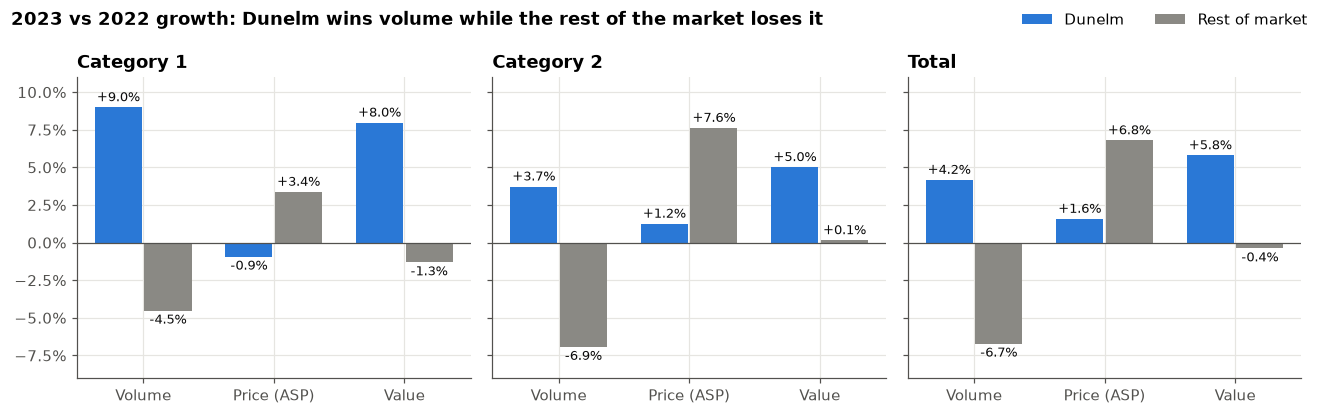

In [29]:
pv = q('''
WITH a AS (
    SELECT category, yr,
           mkt_value, mkt_volume, dun_value, dun_volume, rom_value, rom_volume
    FROM mart_annual
),
g AS (
    SELECT category, yr,
        dun_volume / LAG(dun_volume) OVER w - 1                                   AS dunelm_volume_g,
        (dun_value/dun_volume) / LAG(dun_value/dun_volume) OVER w - 1             AS dunelm_price_g,
        dun_value  / LAG(dun_value)  OVER w - 1                                   AS dunelm_value_g,
        rom_volume / LAG(rom_volume) OVER w - 1                                   AS rom_volume_g,
        (rom_value/rom_volume) / LAG(rom_value/rom_volume) OVER w - 1             AS rom_price_g,
        rom_value  / LAG(rom_value)  OVER w - 1                                   AS rom_value_g
    FROM a
    WINDOW w AS (PARTITION BY category ORDER BY yr)
)
SELECT * EXCLUDE (yr) FROM g WHERE yr = 2023 ORDER BY category
''')
display(pv.style.format("{:+.1%}", subset=pv.columns[1:]).hide(axis="index"))

# Chart: volume vs price growth, Dunelm vs rest of market, per category (small multiples, one axis each)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, (_, r) in zip(axes, pv.iterrows()):
    labels = ["Volume", "Price (ASP)", "Value"]
    d = [r.dunelm_volume_g, r.dunelm_price_g, r.dunelm_value_g]
    m = [r.rom_volume_g, r.rom_price_g, r.rom_value_g]
    x = np.arange(3); w = 0.36
    b1 = ax.bar(x - w/2 - 0.01, d, w, color=C["dunelm"], label="Dunelm")
    b2 = ax.bar(x + w/2 + 0.01, m, w, color=C["market"], label="Rest of market")
    for b, v in list(zip(b1, d)) + list(zip(b2, m)):
        ax.annotate(f"{v:+.1%}", (b.get_x()+b.get_width()/2, v), ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=8.5, color=C["ink"],
                    xytext=(0, 2 if v >= 0 else -2), textcoords="offset points")
    ax.axhline(0, color=C["ink2"], lw=0.8)
    ax.set_xticks(x, labels); ax.set_title(r.category); ax.yaxis.set_major_formatter(pct)
for ax in axes: ax.set_ylim(-0.09, 0.11)
h_, l_ = axes[0].get_legend_handles_labels(); fig.legend(h_, l_, loc="upper right", ncols=2)
fig.suptitle("2023 vs 2022 growth: Dunelm wins volume while the rest of the market loses it", x=0.01, ha="left", fontweight="bold")
save(fig, "q1_price_volume")

### 6.3 What drives growth: price or volume?

**How we approach it**
- **The question:** sales can grow because more units are sold (real demand) or because prices rise (inflation). These need very different responses, so we separate them.
- **The formula:** value growth splits exactly into volume growth and price-per-unit growth:
  **(1 + value growth) = (1 + volume growth) × (1 + price growth)**
- **Benchmark:** Dunelm is again compared with the **rest of the market** (market excluding Dunelm), so its own sales don't flatter the comparison.
- **Caveat:** "price" here is the average price per unit (value ÷ volume), so it reflects both **pricing and product mix**. It's a strong signal, not a like-for-like price comparison.

**Results (2023 vs 2022)**
- **The rest of the market grew through price and lost volume:** units **−6.7%**, price per unit **+6.8%**, so value was flat (−0.4%). Higher prices masked falling demand.
- **Dunelm did the opposite:** units **+4.2%** with only a modest price rise (+1.6%), giving value **+5.8%**. Its growth is **real demand, not inflation**.
- **Category 1, the clearest win:** Dunelm units **+9.0%** while its price per unit **fell 0.9%**. The rest of the market lost 4.5% of units while raising prices 3.4%.
- **Category 2:** Dunelm units +3.7% and price +1.2%. The rest of the market lost 6.9% of units and raised prices **7.6%**, so its value only held flat (+0.1%) because of price.
- **Mix effect to note:** Dunelm's total price rose **+1.6%**, more than in either category (−0.9% and +1.2%). That's because Dunelm's volume grew fastest in Category 1, where items cost much more (~£45 vs ~£12). The shift towards higher-priced items raises the overall average without any price increase. This shows why the category view is the reliable one.

> **So what:** Dunelm is winning on **volume, not price**. The rest of the market raised prices and lost customers' units; Dunelm held prices broadly flat and won units in both categories. That makes the share gain more durable, because it rests on real demand, and Dunelm's relative price position improved (see 6.4).

### 6.4 Relative price position
Price index = Dunelm ASP ÷ market ASP × 100. Above 100 means Dunelm sells at a higher average price per unit — this mixes *pricing* and *product mix* (premium ranges, bigger items), so treat it as a positioning signal rather than a like-for-like price comparison.

In [30]:
price_idx = q('''
SELECT category, yr, ROUND(dun_asp, 2) AS dunelm_asp, ROUND(mkt_asp, 2) AS market_asp,
       ROUND(100 * dun_asp / mkt_asp, 1) AS price_index
FROM mart_annual ORDER BY category, yr
''')
display(price_idx.pivot(index="category", columns="yr", values=["dunelm_asp","market_asp","price_index"]))

dunelm_asp         market_asp         price_index         
yr               2022    2023       2022    2023        2022     2023
category                                                             
Category 1    45.8400 45.4100    43.0500 44.3900    106.5000 102.3000
Category 2    11.6200 11.7700     7.6200  8.1800    152.5000 143.8000
Total         14.5000 14.7300    10.8100 11.5200    134.2000 127.9000

### 6.4 Relative price position

**How we approach it**
- **Price index = Dunelm's average price per unit ÷ the market's average price per unit × 100.**
  100 means the same average price as the market; above 100 means Dunelm's average item costs more.
- **Why:** it turns the price findings from 6.3 into one easy number for positioning: is Dunelm getting relatively cheaper or more expensive than the market?
- **Caveat:** average price per unit mixes **pricing and product mix**. An index above 100 can mean Dunelm sells bigger or more premium items, not that the same item costs more. Use the **direction of change** as the signal, and the category view rather than the total (the total is affected by the mix between categories).

**Results**
- **Dunelm became relatively cheaper in both categories.** The market's average price rose much faster than Dunelm's:
  - **Category 1:** market +3.1% (£43.05 → £44.39); Dunelm −0.9% (£45.84 → £45.41). Index **106.5 → 102.3**.
  - **Category 2:** market +7.3% (£7.62 → £8.18); Dunelm +1.3% (£11.62 → £11.77). Index **152.5 → 143.8**.
- **Category 1: Dunelm is priced almost in line with the market** (index 102). Its lower share in Category 1 (6.5% vs 9.6% in Category 2) is therefore **not a price problem**. It points to range, awareness or cross-selling, which feeds into Q3.
- **Category 2: the high index (144) mostly reflects mix.** Dunelm likely sells larger or more premium items in this category, rather than charging 44% more for the same products.
- **Total index 134 → 128:** the same direction, driven by both categories.

> **So what:** Dunelm held its prices while the market raised them, so its relative price position improved in both categories. Combined with 6.3, this shows Dunelm gained share by **offering better relative value**, not by discounting. In Category 1 it's already priced at market level, so price isn't what's holding back its share there.

### 6.5 Weekly share trend
A 13-week rolling share removes week-to-week promotional noise. The faint line is the weekly value.

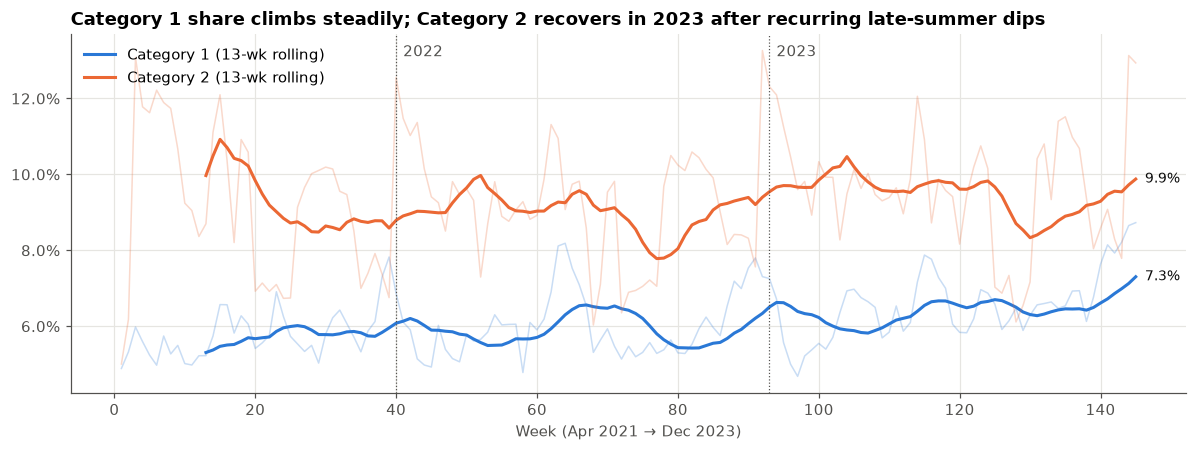

In [31]:
wk = q('''
SELECT week_idx, yr, wk, category, dun_value_share,
       SUM(dun_value) OVER w / SUM(mkt_value) OVER w AS share_13w
FROM clean_market_weekly
WINDOW w AS (PARTITION BY category ORDER BY week_idx ROWS BETWEEN 12 PRECEDING AND CURRENT ROW)
ORDER BY category, week_idx
''')
fig, ax = plt.subplots()
for cat, g in wk.groupby("category"):
    ax.plot(g.week_idx, g.dun_value_share, color=CAT_COL[cat], alpha=0.25, lw=1)
    gg = g[g.week_idx >= 13]
    ax.plot(gg.week_idx, gg.share_13w, color=CAT_COL[cat], label=f"{cat} (13-wk rolling)")
    ax.annotate(f"{gg.share_13w.iloc[-1]:.1%}", (gg.week_idx.iloc[-1], gg.share_13w.iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color=C["ink"], fontsize=9)
for y in [2022, 2023]:
    x0 = wk[(wk.yr == y) & (wk.wk == 1)].week_idx.min()
    ax.axvline(x0, color=C["ink2"], lw=0.8, ls=":"); ax.text(x0 + 1, ax.get_ylim()[1]*0.98, str(y), va="top", color=C["ink2"])
ax.yaxis.set_major_formatter(pct); ax.set_xlabel("Week (Apr 2021 → Dec 2023)")
ax.set_title("Category 1 share climbs steadily; Category 2 recovers in 2023 after recurring late-summer dips")
ax.legend(loc="upper left")
save(fig, "q1_share_trend")

### 6.5 Weekly share trend

**How we approach it**
- **Why a rolling share:** weekly share jumps around with promotions (Dunelm's own sale weeks push it to 12–13%), which hides the underlying trend.
- **13-week rolling share = Dunelm sales over the last 13 weeks ÷ market sales over the same 13 weeks.** Thirteen weeks is one quarter: long enough to smooth out promotions, short enough to show turning points.
- **Ratio of totals:** big weeks carry their true weight, as in 6.1.
- The faint lines are the raw weekly shares; the bold lines are the rolling trend.

**Results**
- **Category 1, steady upward trend:** from about **5.3–5.5% in mid-2021 to 7.3% at the end of 2023**. There are temporary dips (late 2022, around January, its peak season, as seen in 6.6), but each recovery reaches a higher level. It ends the year **well above its 2023 average (6.5%)**, so momentum is strong.
- **Category 2, cyclical with a 2023 recovery:**
  - High in spring 2021 (~10–11%, when shops reopened after lockdown), then down to ~8.5% by late 2021.
  - A **sharp dip every late summer**: to ~7.8% in 2022 and ~8.3% in 2023 (weeks ~33–38), the same pattern noted in Q1.
  - **2023 runs at a higher level than 2022** (mostly 9.5–10.5%), ending at **9.9%**.
- **Caveat on the end-points:** the final 13 weeks include Dunelm's post-Christmas sale weeks, when its weekly share is very high, so the 9.9% end-point for Category 2 is flattered. Category 1's rise is broad-based through December, so its momentum is more convincing.

> **So what:** Category 1 shows a **sustained share gain**, with no sign of slowing. Category 2 is **recovering**: higher in 2023 than 2022, but held back by a recurring late-summer dip and by under-trading the Black Friday → Christmas run (6.6). Both are timing issues Dunelm can act on.

### 6.6 Seasonality — when does Dunelm win and lose share?
Peak weeks are defined from the **market** only (not from Dunelm's result, to avoid circularity): weeks where the market's sales are ≥ 15% above that category-year's average week.

In [32]:
run('''
CREATE OR REPLACE TABLE mart_peak AS
SELECT m.*,
       mkt_value / AVG(mkt_value) OVER (PARTITION BY yr, category) AS mkt_week_index,
       (mkt_value / AVG(mkt_value) OVER (PARTITION BY yr, category)) >= 1.15 AS is_peak
FROM clean_market_weekly m
WHERE is_full_year
''')
peak = q('''
SELECT yr, category,
       SUM(CASE WHEN is_peak THEN 1 ELSE 0 END)                                         AS peak_weeks,
       SUM(CASE WHEN is_peak THEN mkt_value END) / SUM(mkt_value)                       AS peak_pct_of_market,
       SUM(CASE WHEN is_peak THEN dun_value END) / SUM(CASE WHEN is_peak THEN mkt_value END)       AS share_peak,
       SUM(CASE WHEN NOT is_peak THEN dun_value END) / SUM(CASE WHEN NOT is_peak THEN mkt_value END) AS share_non_peak
FROM mart_peak GROUP BY ALL ORDER BY category, yr
''')
peak["share_gap_pp"] = (peak.share_peak - peak.share_non_peak) * 100
display(peak.style.format({"peak_pct_of_market":"{:.1%}","share_peak":"{:.2%}","share_non_peak":"{:.2%}","share_gap_pp":"{:+.2f}pp"}).hide(axis="index"))
print("Peak weeks (2023):")
display(q("SELECT category, LIST(wk ORDER BY wk) AS peak_weeks FROM mart_peak WHERE is_peak AND yr=2023 GROUP BY category ORDER BY 1"))

yr,category,peak_weeks,peak_pct_of_market,share_peak,share_non_peak,share_gap_pp
2022,Category 1,3.000000,6.8%,5.41%,6.03%,-0.62pp
2023,Category 1,5.000000,11.5%,5.83%,6.60%,-0.77pp
2022,Category 2,8.000000,20.9%,8.65%,9.36%,-0.70pp
2023,Category 2,6.000000,15.5%,8.50%,9.82%,-1.32pp


Peak weeks (2023):


,category,peak_weeks
0,Category 1,"[1, 2, 3, 4, 5]"
1,Category 2,"[46, 47, 48, 49, 50, 51]"


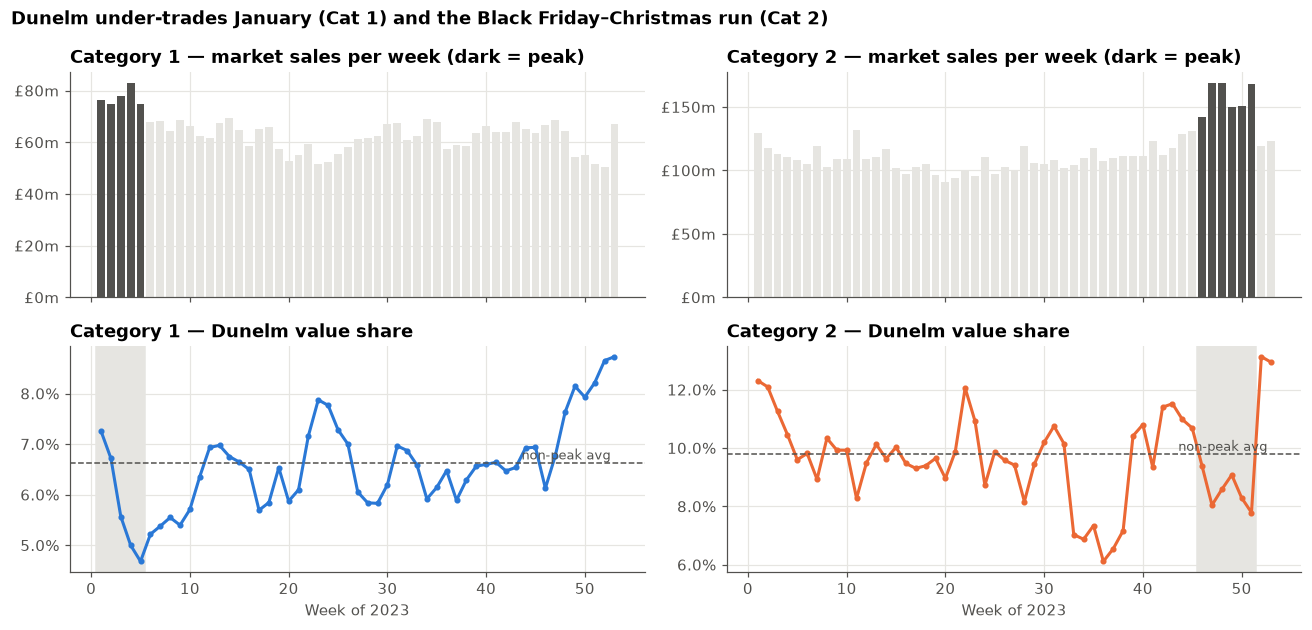

In [33]:
# Small multiples: market seasonality (top) and Dunelm share (bottom) for 2023 — two charts, never a dual axis
s = q("SELECT category, wk, mkt_value, dun_value_share, is_peak FROM mart_peak WHERE yr = 2023 ORDER BY category, wk")
fig, axes = plt.subplots(2, 2, figsize=(12, 5.8), sharex=True)
for j, (cat, g) in enumerate(s.groupby("category")):
    a1, a2 = axes[0, j], axes[1, j]
    a1.bar(g.wk, g.mkt_value, width=0.8, color=np.where(g.is_peak, C["ink2"], C["grid"]))
    a1.yaxis.set_major_formatter(gbp_m); a1.set_title(f"{cat} — market sales per week (dark = peak)")
    a2.plot(g.wk, g.dun_value_share, color=CAT_COL[cat], marker="o", ms=3)
    avg = g.loc[~g.is_peak, "dun_value_share"].mean()
    a2.axhline(avg, color=C["ink2"], ls="--", lw=1); a2.text(53, avg, "non-peak avg ", va="bottom", ha="right", color=C["ink2"], fontsize=8.5)
    for _, r in g[g.is_peak].iterrows():
        a2.axvspan(r.wk - 0.5, r.wk + 0.5, color=C["grid"], zorder=0)
    a2.yaxis.set_major_formatter(pct); a2.set_title(f"{cat} — Dunelm value share"); a2.set_xlabel("Week of 2023")
fig.suptitle("Dunelm under-trades January (Cat 1) and the Black Friday–Christmas run (Cat 2)",
             x=0.01, ha="left", fontweight="bold")
save(fig, "q1_seasonality_share")

In [34]:
# 6.6b Sensitivity: does the peak-share gap depend on the 15% threshold?
rows = []
for t in [1.05, 1.10, 1.15, 1.20, 1.25]:
    rows.append(q(f'''
    WITH p AS (
        SELECT *, mkt_value / AVG(mkt_value) OVER (PARTITION BY yr, category) AS week_index
        FROM clean_market_weekly WHERE is_full_year
    )
    SELECT {t} AS threshold, yr, category,
           SUM(CASE WHEN week_index >= {t} THEN 1 ELSE 0 END) AS peak_weeks,
           (SUM(CASE WHEN week_index >= {t} THEN dun_value END) / SUM(CASE WHEN week_index >= {t} THEN mkt_value END)
          - SUM(CASE WHEN week_index <  {t} THEN dun_value END) / SUM(CASE WHEN week_index <  {t} THEN mkt_value END)) * 100 AS gap_pp
    FROM p GROUP BY yr, category
    '''))
sens = pd.concat(rows)
sens["label"] = sens.apply(lambda r: f"{r.gap_pp:+.2f}pp ({int(r.peak_weeks)} wks)" if r.peak_weeks else "no peak weeks", axis=1)
display(sens.pivot_table(index="threshold", columns=["category", "yr"], values="label", aggfunc="first"))


# Threshold-free check: Dunelm share by quartile of market size (Q1 = busiest weeks)
quart = q('''
WITH r AS (
    SELECT *, NTILE(4) OVER (PARTITION BY yr, category ORDER BY mkt_value DESC) AS quartile
    FROM clean_market_weekly WHERE is_full_year
)
SELECT yr, category, quartile, SUM(dun_value) / SUM(mkt_value) AS share
FROM r GROUP BY yr, category, quartile
''')
quart = (quart.pivot_table(index=["category", "yr"], columns="quartile", values="share")
              .rename(columns={1: "Q1 (busiest)", 2: "Q2", 3: "Q3", 4: "Q4 (quietest)"}))
quart.columns.name = None
display(quart.style.format("{:.2%}"))

category         Category 1                          Category 2                  
yr                     2022              2023              2022              2023
threshold                                                                        
1.0500     -0.47pp (14 wks)  -0.45pp (17 wks)  +0.29pp (17 wks)  -0.16pp (12 wks)
1.1000      -0.64pp (9 wks)   -0.77pp (5 wks)  +0.09pp (10 wks)  -0.51pp (10 wks)
1.1500      -0.62pp (3 wks)   -0.77pp (5 wks)   -0.70pp (8 wks)   -1.32pp (6 wks)
1.2000      -0.47pp (2 wks)   -0.64pp (3 wks)   -1.10pp (6 wks)   -1.32pp (6 wks)
1.2500        no peak weeks   -1.55pp (1 wks)   -1.10pp (6 wks)   -1.47pp (5 wks)

### 6.6 Seasonality: when does Dunelm win and lose share?

**How we approach it**
- **Peak weeks are defined from the market only:** a week is a peak if market sales are at least **15% above that category's average week** in that year. Using the market (not Dunelm's own sales) avoids circular logic.
- **Data-driven, not calendar-driven:** week numbers shift between years (4.5), so the data finds the real peaks instead of fixed week numbers.
- **We compare Dunelm's share in peak weeks with its share in all other weeks.** A negative gap means Dunelm under-trades the moments when the market spends most.
- **The 15% threshold is a judgement call, so we test it:** (a) re-running at 5%–25%, and (b) a threshold-free check that splits each year's weeks into quartiles by market size (Q1 = busiest) and compares Dunelm's share.

**Results**
- **The peaks are clearly seasonal:**
  - **Category 1:** January (weeks 1–5 in 2023), **11.5%** of the year's market.
  - **Category 2:** Black Friday → Christmas (weeks 46–51 in 2023), **15.5%** of the year's market.
- **Category 1: Dunelm under-trades January, and the finding is robust.**
  - Share in peak weeks **5.83% vs 6.60%** in other weeks (−0.77pp) in 2023; −0.62pp in 2022.
  - The gap is negative at **every threshold** tested (−0.45 to −0.77pp with a meaningful number of weeks).
  - Threshold-free check: share rises steadily from the busiest to the quietest weeks (**6.0% → 7.2%** in 2023).
  - In the chart, share drops from 7.3% in week 1 to **4.7% in week 5**, then recovers through the year to ~8.7% in December.
- **Category 2: Dunelm under-trades the Black Friday → Christmas run, then wins it back in its own sale.**
  - Share in weeks 46–51 **8.50% vs 9.82%** in other weeks (−1.32pp) in 2023; −0.70pp in 2022.
  - The gap holds at **every threshold from 15% up** (−1.1 to −1.5pp). At 5–10% it shrinks or disappears, because the wider "peak" also picks up **Dunelm's own sale weeks** (weeks 52–53 and January, share 12–13%) and October, where Dunelm trades strongly.
  - Threshold-free check: the busiest quartile has an **average share** (9.7% in 2023), so busy weeks *in general* aren't the problem. The weakness is specific to the Black Friday → Christmas run.
- **Trend:** the Category 2 gap **widened slightly** in 2023 (e.g. −1.10 → −1.32pp at 20%). The size of the change depends on the threshold, so it isn't quoted as a precise figure.
- **Separate from peaks:** Category 2 also dips sharply in **late summer** (to ~6% around week 36), a recurring pattern noted in 6.5.

> **So what:** Dunelm loses share exactly when customers spend most: **January in Category 1** (robust across every test) and the **Black Friday → Christmas run in Category 2**, where it then wins share back in its own post-Christmas sale. Dunelm trades on **its own sale calendar rather than the customer's**, so the opportunity is about **when** to compete, not just how much.

### 6.7 Inside Dunelm's growth — customers × frequency × order value
From the internal data: `Sales = Customers × Orders per customer × Average order value (AOV)`. Log-decomposition splits growth exactly into those three drivers.

In [35]:
run('''
CREATE OR REPLACE TABLE mart_customer_kpis AS
SELECT yr, segment,
       SUM(customers) customers, SUM(orders) orders, SUM(units) units, SUM(sales_value) sales_value,
       SUM(orders)/SUM(customers)        AS freq,
       SUM(sales_value)/SUM(orders)      AS aov,
       SUM(units)/SUM(orders)            AS units_per_order,
       SUM(sales_value)/SUM(units)       AS price_per_unit,
       SUM(sales_value)/SUM(customers)   AS spend_per_customer
FROM clean_internal
GROUP BY GROUPING SETS ((yr, segment), (yr))
''')
run("UPDATE mart_customer_kpis SET segment = 'Total' WHERE segment IS NULL")

kpi = q("SELECT * FROM mart_customer_kpis ORDER BY segment, yr")
display(kpi.style.format({"customers":"{:,.0f}","orders":"{:,.0f}","units":"{:,.0f}","sales_value":"£{:,.0f}",
                          "freq":"{:.2f}","aov":"£{:.2f}","units_per_order":"{:.2f}","price_per_unit":"£{:.2f}",
                          "spend_per_customer":"£{:.2f}"}).hide(axis="index"))

decomp = q('''
WITH p AS (
    SELECT segment,
        MAX(CASE WHEN yr=2022 THEN customers END) c0, MAX(CASE WHEN yr=2023 THEN customers END) c1,
        MAX(CASE WHEN yr=2022 THEN freq END) f0,      MAX(CASE WHEN yr=2023 THEN freq END) f1,
        MAX(CASE WHEN yr=2022 THEN aov END) a0,       MAX(CASE WHEN yr=2023 THEN aov END) a1,
        MAX(CASE WHEN yr=2022 THEN sales_value END) s0, MAX(CASE WHEN yr=2023 THEN sales_value END) s1
    FROM mart_customer_kpis GROUP BY segment
)
SELECT segment,
       s1 / s0 - 1 AS sales_growth,
       c1 / c0 - 1 AS customer_growth, f1 / f0 - 1 AS frequency_growth, a1 / a0 - 1 AS aov_growth,
       -- £ contribution of each driver (log-share allocation; sums exactly to the change)
       (s1 - s0) * LN(c1/c0) / LN(s1/s0) AS contrib_customers,
       (s1 - s0) * LN(f1/f0) / LN(s1/s0) AS contrib_frequency,
       (s1 - s0) * LN(a1/a0) / LN(s1/s0) AS contrib_aov,
       s1 - s0 AS total_change
FROM p ORDER BY segment
''')
display(decomp.style.format({c:"{:+.1%}" for c in ["sales_growth","customer_growth","frequency_growth","aov_growth"]})
                    .format(lambda v: f"£{v/1e6:+,.1f}m", subset=["contrib_customers","contrib_frequency","contrib_aov","total_change"])
                    .hide(axis="index"))

yr,segment,customers,orders,units,sales_value,freq,aov,units_per_order,price_per_unit,spend_per_customer
2022,Segment1,"1,641,858","1,948,742","5,656,086","£111,295,371",1.19,£57.11,2.90,£19.68,£67.79
2023,Segment1,"1,565,910","2,211,612","6,911,047","£132,570,253",1.41,£59.94,3.12,£19.18,£84.66
2022,Segment2,"2,019,123","3,038,626","12,942,142","£196,592,612",1.50,£64.70,4.26,£15.19,£97.37
2023,Segment2,"2,061,856","3,536,083","14,102,536","£225,213,722",1.71,£63.69,3.99,£15.97,£109.23
2022,Segment3,"2,641,719","8,395,946","33,976,108","£454,593,813",3.18,£54.14,4.05,£13.38,£172.08
2023,Segment3,"2,897,568","9,058,782","33,746,823","£448,851,592",3.13,£49.55,3.73,£13.30,£154.91
2022,Total,"6,302,700","13,383,314","52,574,336","£762,481,796",2.12,£56.97,3.93,£14.50,£120.98
2023,Total,"6,525,334","14,806,477","54,760,406","£806,635,567",2.27,£54.48,3.70,£14.73,£123.62


segment,sales_growth,customer_growth,frequency_growth,aov_growth,contrib_customers,contrib_frequency,contrib_aov,total_change
Segment1,+19.1%,-4.6%,+19.0%,+5.0%,£-5.8m,£+21.2m,£+5.9m,£+21.3m
Segment2,+14.6%,+2.1%,+14.0%,-1.6%,£+4.4m,£+27.5m,£-3.3m,£+28.6m
Segment3,-1.3%,+9.7%,-1.6%,-8.5%,£+41.8m,£-7.4m,£-40.1m,£-5.7m
Total,+5.8%,+3.5%,+6.9%,-4.4%,£+27.2m,£+52.0m,£-35.1m,£+44.2m


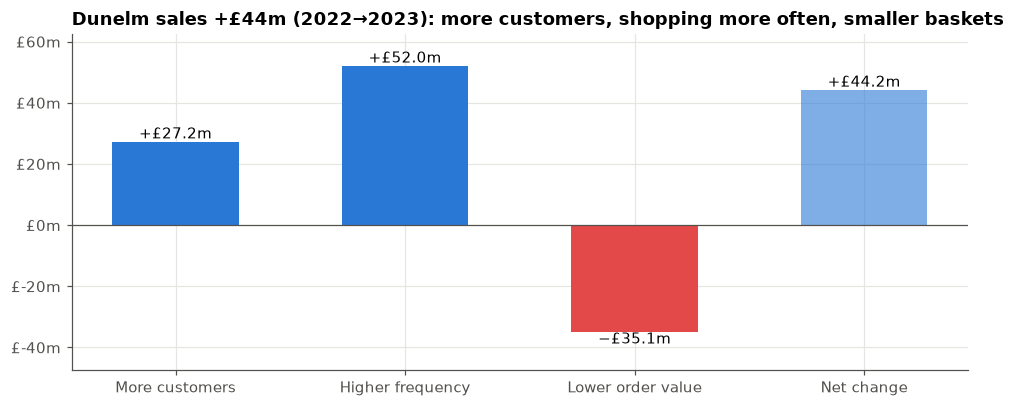

In [36]:
# Growth bridge 2022 → 2023: contribution of each driver (bars start at zero — no truncated axis)
t = decomp[decomp.segment == "Total"].iloc[0]
bridge = pd.Series({"More customers": t.contrib_customers, "Higher frequency": t.contrib_frequency,
                    "Lower order value": t.contrib_aov, "Net change": t.total_change})
fig, ax = plt.subplots(figsize=(9, 3.8))
cols = [C["neg"] if v < 0 else C["dunelm"] for v in bridge]
bars = ax.bar(bridge.index, bridge.values, color=cols, width=0.55)
bars[-1].set_alpha(0.6)
for b, v in zip(bars, bridge.values):
    ax.text(b.get_x() + b.get_width()/2, v, f"{'+' if v >= 0 else '−'}£{abs(v)/1e6:,.1f}m",
            ha="center", va="bottom" if v >= 0 else "top", fontsize=9.5,
            )
ax.axhline(0, color=C["ink2"], lw=0.8); ax.yaxis.set_major_formatter(gbp_m)
ax.set_ylim(bridge.min() * 1.35, bridge.max() * 1.2)
ax.set_title("Dunelm sales +£44m (2022→2023): more customers, shopping more often, smaller baskets")
save(fig, "q1_growth_waterfall")

### 6.7 Inside Dunelm's growth: customers × frequency × order value

**How we approach it**
- **Why:** the market data shows *that* Dunelm grew; the internal data shows *how*. More customers, more visits and bigger baskets each need a different action.
- **The breakdown:** **Sales = Customers × Orders per customer (frequency) × Average order value (AOV)**. AOV can be split further into **units per order × price per unit**.
- **£ contribution of each driver (log decomposition):** the three drivers multiply, so simple subtraction leaves an unexplained "interaction" amount. Using logs turns multiplication into addition, so the three contributions **add up exactly** to the total change:
  contribution = total £ change × ln(driver's ratio) ÷ ln(sales ratio)
- **Caveat:** the segment-level figures don't add up exactly to the total-level drivers, because customers' mix across segments also shifted (Segment 3 grew from 42% to 44% of customers). If segments are defined by shopping frequency, some movement is customers changing segment, not changing behaviour.

**Results (2022 → 2023)**
- **Total sales +£44.2m (+5.8%):**
  - **More customers** (+3.5%, to 6.53m): **+£27.2m**
  - **Higher frequency** (2.12 → 2.27 orders per customer, +6.9%): **+£52.0m**, the biggest driver
  - **Lower order value** (£56.97 → £54.48, −4.4%): **−£35.1m**, giving back almost half of the gains
- **Segment 3 (most frequent shoppers, 56% of sales), growth without value:**
  - Customers **+9.7%** (+£41.8m), but AOV **−8.5%** (£54.14 → £49.55, −£40.1m), so **sales fell 1.3%** despite ~256k more customers.
  - The basket shrank because of **fewer items per order** (4.05 → 3.73 units), not cheaper items (price per unit flat at ~£13.3).
- **Segment 1 (lightest shoppers), fewer customers, much more engaged:** customers −4.6%, but frequency **+19%** (1.19 → 1.41) and AOV +5%, giving sales **+19%** (+£21.3m). Spend per customer rose from £68 to £85.
- **Segment 2 (middle), healthy growth:** frequency **+14%** (1.50 → 1.71), sales **+14.6%** (+£28.6m). AOV dipped slightly (−1.6%): fewer items per order, partly offset by a higher price per unit (£15.19 → £15.97).

> **So what:** Dunelm's growth is **customer-led**: more customers shopping more often. But **baskets are shrinking**, which cost £35m. The problem is concentrated in **Segment 3**, the most valuable group, where customers now buy **fewer items per order**. Protecting basket size in the loyal core (bundles, "complete the room", delivery thresholds) is a high-confidence lever, because it works with customers Dunelm already has.

### 6.8 Reach versus competitors (Market Data 2)
Penetration = households shopping the retailer in the last year ÷ households shopping the market.

retailer,Competitor A,Competitor B,Dunelm
grade_group,,,
All,29.6%,60.2%,31.0%
AB,32.8%,53.8%,32.3%
C1,31.1%,57.8%,32.1%
C2,28.4%,64.6%,31.0%
D,26.6%,67.7%,28.8%
E,23.2%,65.3%,28.5%


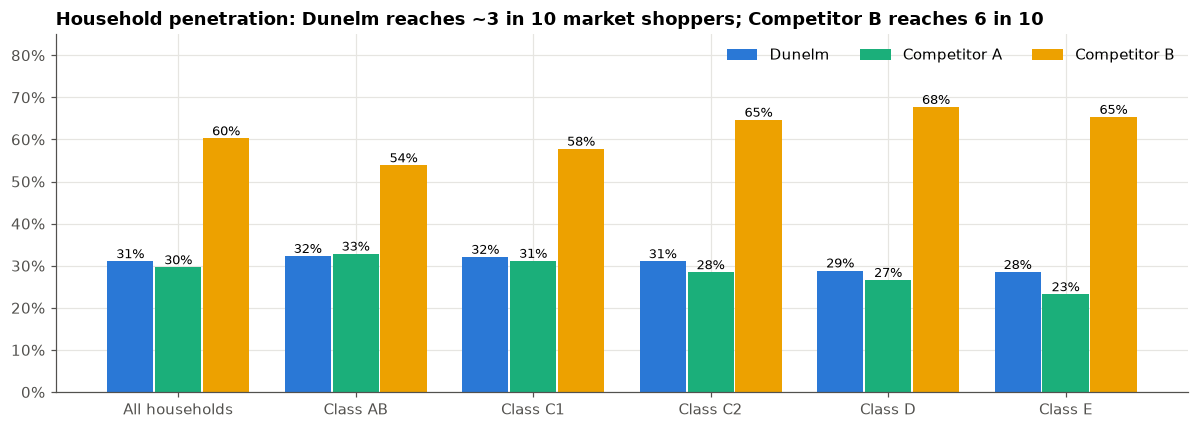

In [37]:
pen = q('''
WITH t AS (SELECT grade_group, households AS total_hh FROM clean_market_hh WHERE retailer = 'Total Market'),
r AS (
    SELECT retailer, grade_group, households FROM clean_market_hh WHERE retailer <> 'Total Market'
    UNION ALL
    SELECT retailer, 'All', SUM(households) FROM clean_market_hh WHERE retailer <> 'Total Market' GROUP BY retailer
),
tt AS (SELECT * FROM t UNION ALL SELECT 'All', SUM(total_hh) FROM t)
SELECT r.retailer, r.grade_group, r.households, tt.total_hh, r.households / tt.total_hh AS penetration
FROM r JOIN tt USING (grade_group)
''')
pen_w = pen.pivot(index="grade_group", columns="retailer", values="penetration").loc[["All","AB","C1","C2","D","E"]]
display(pen_w.style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(pen_w)); w = 0.26
for k, (ret, col) in enumerate([("Dunelm", C["dunelm"]), ("Competitor A", C["comp_a"]), ("Competitor B", C["comp_b"])]):
    bars = ax.bar(x + (k - 1) * (w + 0.01), pen_w[ret], w, color=col, label=ret)
    for b, v in zip(bars, pen_w[ret]):
        ax.text(b.get_x() + b.get_width()/2, v, f"{v:.0%}", ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(x, ["All households"] + [f"Class {g}" for g in pen_w.index[1:]])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0)); ax.set_ylim(0, 0.85)
ax.set_title("Household penetration: Dunelm reaches ~3 in 10 market shoppers; Competitor B reaches 6 in 10")
ax.legend(loc="upper right", ncols=3)
save(fig, "q1_penetration")

### 6.8 Reach versus competitors (Market Data 2)

**How we approach it**
- **Household penetration = households who shopped at the retailer in the last year ÷ households who shopped in the market.** It measures **reach**: how many market shoppers a retailer gets at all.
- **Why:** market share is driven by **reach × depth** (how many households shop with you × how much each spends). Sections 6.1–6.7 covered depth; this covers reach. It's also the only data with **named competitors**.
- **Ratios only, within one source:** Market Data 2 is a separate panel with its own period ("last year"), so its counts are never combined with the internal customer data (see 4.9).
- **By social class**, to see whether any reach gap is broad or concentrated in certain households.

**Results**

| Class | Dunelm | Competitor A | Competitor B | Dunelm vs A | Dunelm vs B |
|---|---|---|---|---|---|
| **All** | **31.0%** | **29.6%** | **60.2%** | **+1.4pp** | **−29.2pp** |
| AB | 32.3% | 32.8% | 53.8% | −0.5pp | −21.5pp |
| C1 | 32.1% | 31.1% | 57.8% | +1.0pp | −25.7pp |
| C2 | 31.0% | 28.4% | 64.6% | +2.6pp | −33.6pp |
| D | 28.8% | 26.6% | 67.7% | +2.2pp | −38.9pp |
| E | 28.5% | 23.2% | 65.3% | +5.3pp | −36.8pp |

- **The three retailers have different reach profiles:**
  - **Competitor A skews upmarket:** its reach falls steadily from **32.8% in AB to 23.2% in E**.
  - **Competitor B skews mass-market:** its reach rises from **53.8% in AB to 65–68% in C2/D/E**.
  - **Dunelm is the most even across classes** (28.5–32.3%), sitting between the two.
- **Versus Competitor A, Dunelm is slightly ahead overall (31.0% vs 29.6%):**
  - **Level in AB** (32.3% vs 32.8%, the only class where A is marginally ahead) and **ahead in C1** (+1.0pp).
  - **Clearly ahead in C2, D and E**, with the lead growing as grade falls, up to **+5.3pp in E**. Dunelm has broader appeal than A beyond affluent households.
- **Versus Competitor B, Dunelm reaches only half as many households (31% vs 60%):**
  - The gap is **smallest in AB (−21.5pp)** and **widest in C2/D/E (−34 to −39pp)**, where B reaches about two in three households.
- **Reading the two together:** Dunelm already **matches the upmarket competitor in affluent households and beats it elsewhere**, but is **far behind the mass-market competitor**, especially in value-conscious households.

> **So what:** Dunelm's biggest headroom is **reach, not depth**: seven in ten market households don't shop there at all.
> - **Against Competitor A, Dunelm is holding its own.** The task is to **protect AB households**, the one class where A is level, so the current lead isn't eroded.
> - **Against Competitor B, the gap is the real growth opportunity**, concentrated in **C2/D/E households**. That's also where Dunelm's customers grew fastest in 2023 (5b.1) and where it already beats Competitor A, so its offer clearly can appeal there. Growing reach means **value perception and relevance for mass-market households**.
> - Each extra point of penetration is about 263k households.

> **So what (Q1): How is Dunelm performing in the context of the market?**
>
> **Answer in one line:** Dunelm is clearly outperforming a flat market, winning real volume rather than relying on price, with 2023 as the turning point. But it still under-trades the market's biggest weeks, its baskets are shrinking, and it reaches only half as many households as its largest competitor.
>
> **Strengths**
> - **Outgrowing a flat market.** The market was flat in 2023 (+0.1%; rest of market −0.4%) while Dunelm grew **+5.8% to £807m**. Value share rose **8.05% → 8.51% (+0.46pp)** and volume share rose too, with gains in **both categories** (Category 1 +0.53pp, Category 2 +0.40pp).
> - **2023 was the turning point.** On a like-for-like basis (weeks 14–52), total share was **flat in 2022 (7.9%)** and jumped to **8.4% in 2023**. Category 1 has gained share **every year since 2021**; Category 2 dipped in 2022 and recovered in 2023.
> - **Real demand, not price.** The rest of the market raised prices (+6.8%) and lost units (−6.7%). Dunelm won units (+4.2%) with only a modest price rise. Its price index fell in both categories (Category 1 106 → 102, Category 2 153 → 144), so Dunelm became **relatively better value** without discounting.
> - **Momentum is continuing.** The 13-week rolling share ended 2023 above the year's average, especially in Category 1 (7.3% vs 6.5%).
> -  **Customer-led growth.** More customers (+3.5%, +£27m) shopping more often (+6.9%, +£52m). Lighter shoppers became much more valuable: spend per customer **+21–30% in Segment 1 and +10–17% in Segment 2, in every grade**. Value-conscious customers are growing fastest (price seekers +5.2%, grades D/E spend per customer +9%), and within each grade price seekers spend almost as much as other customers.
>
> **Weak spots**
> - **Under-trading the customer's peak moments.** Share falls in **January in Category 1** (robust across every test) and in the **Black Friday → Christmas run in Category 2**, where Dunelm wins share back in its own post-Christmas sale. The Category 2 gap widened slightly in 2023. Dunelm trades on its own sale calendar rather than the customer's.
> - **Shrinking baskets in the loyal core.** Average order value fell 4.4% (−£35m), giving back almost half the growth. It's concentrated in **Segment 3**, the most valuable customers: customers +9.7% but AOV −8.5% because of **fewer items per order**, so the segment's sales fell 1.3%.
>   - Segment 3 spend per customer fell **in every grade**, steepest among higher-grade customers (A −10%, B −14%, C1 −10%).
>   - Its share of sales fell from **59.6% to 55.6%** while its share of customers rose, so its value index dropped from **142 to 125**.
> - **Category 1 under-indexes.** Share is 6.5% vs 9.6% in Category 2, despite being priced almost in line with the market, so the gap isn't about price.
> - **Recurring late-summer dip.** In weeks 33–38, Category 2 share falls to ~6.9% vs ~9.5% the rest of the year, in all three years. Worth asking whether this is a deliberate trading choice.
> - **Limited reach.** Dunelm reaches **31%** of market households: slightly ahead of Competitor A (30%, level in AB, ahead in C2/D/E), but **half of Competitor B (60%)**. The gap to B is widest in C2/D/E households (−34 to −39pp).
> - **Caveat:** if customer segments are defined by shopping frequency, part of the segment shifts reflects customers moving between segments, not only changes in behaviour. The direction of the findings is clear; the exact sizes should be treated with care.*

---
# Q2 · What will the market be worth, and what could change that?

### 7.1 Build the series and decompose it
Weekly data (Apr-2021 to Dec-2023) gives just under three seasonal cycles — enough for a seasonal model, but not a complex one.

**Calendar fix for modelling:** 2022 and 2023 both have a week 53, so a plain 52-week season drifts by a week each year and the models misread the January and Christmas peaks as level changes (this was tested: it biases the forecast ~7% low). Folding week 53 into week 52 aligns seasonality on week-of-year while preserving the annual totals. STL then separates trend, seasonality and noise.

143 modelling weeks (2021: wk14–52, 2022–23: 52 positions each)


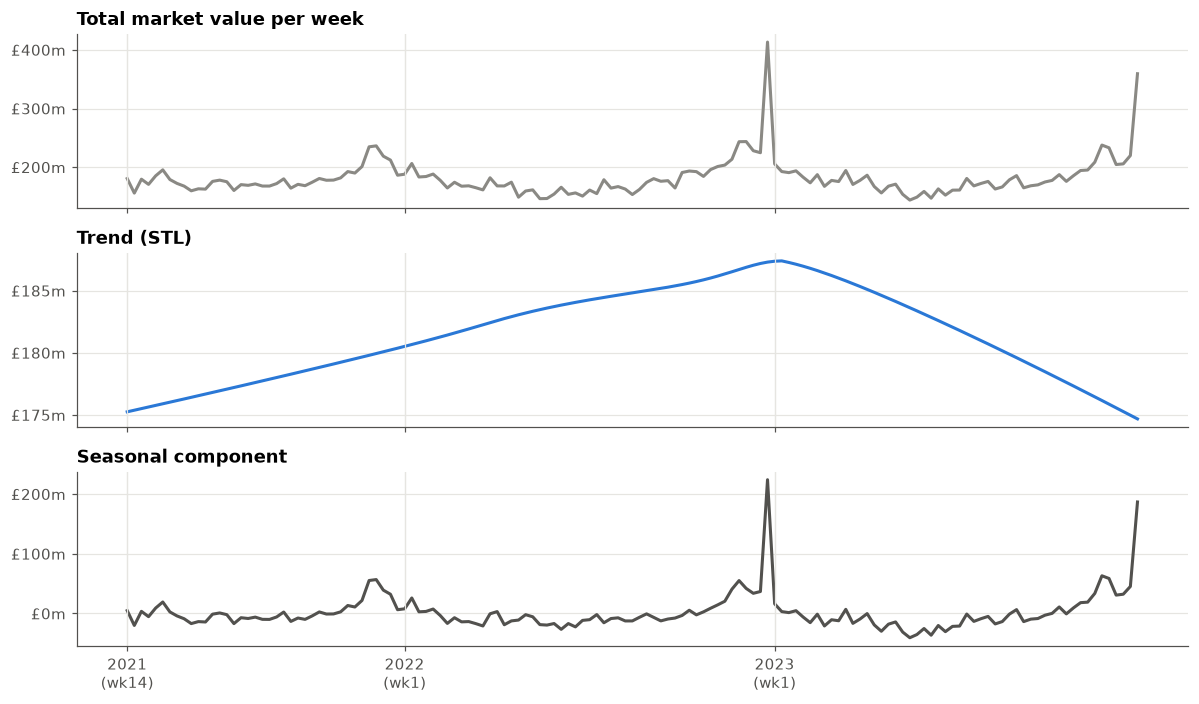

STL trend, average of last 52 weeks vs the 52 before: -1.3%


In [38]:
# Modelling series: fold week 53 into week 52 so every year has 52 seasonal positions aligned on week-of-year.
# Annual totals are preserved (2022 and 2023 still sum to their reported 53-week values).
run('''
CREATE OR REPLACE TABLE mart_model_weekly AS
SELECT yr, LEAST(wk, 52) AS wk52, category,
       SUM(mkt_value) AS mkt_value, SUM(mkt_volume) AS mkt_volume, SUM(dun_value) AS dun_value
FROM clean_market_weekly
GROUP BY yr, LEAST(wk, 52), category
''')
ts = q('''
SELECT ROW_NUMBER() OVER (ORDER BY yr, wk52) AS t, yr, wk52,
       SUM(mkt_value) AS mkt_value,
       SUM(CASE WHEN category='Category 1' THEN mkt_value END) AS cat1_value,
       SUM(CASE WHEN category='Category 2' THEN mkt_value END) AS cat2_value
FROM mart_model_weekly GROUP BY yr, wk52 ORDER BY yr, wk52
''')
reported = q("SELECT yr, SUM(mkt_value) v FROM clean_market_weekly GROUP BY yr").set_index("yr").v
assert np.allclose(ts.groupby("yr").mkt_value.sum().sort_index(), reported.sort_index()), "folding changed annual totals"
print(len(ts), "modelling weeks (2021: wk14–52, 2022–23: 52 positions each)")
YEAR_START = ts.groupby("yr").t.min().to_dict()

stl = STL(ts.mkt_value.values, period=52, robust=True).fit()
fig, axes = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True)
axes[0].plot(ts.t, ts.mkt_value, color=C["market"]); axes[0].set_title("Total market value per week")
axes[1].plot(ts.t, stl.trend, color=C["dunelm"]);     axes[1].set_title("Trend (STL)")
axes[2].plot(ts.t, stl.seasonal, color=C["ink2"]);    axes[2].set_title("Seasonal component")
for a in axes:
    a.yaxis.set_major_formatter(gbp_m)
    for yy, x0 in YEAR_START.items(): a.axvline(x0, color=C["grid"], lw=0.8)
axes[2].set_xticks(list(YEAR_START.values()), [f"{y}\n(wk{14 if y == 2021 else 1})" for y in YEAR_START])
save(fig, "q2_stl")
print(f"STL trend, average of last 52 weeks vs the 52 before: {stl.trend[-52:].mean() / stl.trend[-104:-52].mean() - 1:+.1%}")

### 7.1 Results: the shape of the market

**How we approach it**
- **Start by understanding the series before forecasting it:** how strong the seasonality is, and which way the underlying level is moving.
- **Fold week 53 into week 52** so every year has 52 aligned weeks. Without this, the seasonal pattern drifts by a week each year and models misread Christmas as a fall in the market (tested: ~7% too low). Annual totals are unchanged; the larger spike at the end of 2022 and 2023 is simply two weeks of sales in one position.
- **STL decomposition** splits weekly sales into:
  - **Trend:** the underlying level, with seasonality and one-off weeks removed
  - **Seasonal:** the repeating yearly pattern
  - **Remainder:** noise
  "Robust" STL stops extreme weeks pulling the trend around.

**Results**
- **143 modelling weeks:** 2021 weeks 14–52, plus 52 positions for 2022 and 2023. Just under three seasonal cycles: enough for simple seasonal models, not for complex ones.
- **Seasonality is strong and regular:** a build-up from October, a sharp Black Friday–Christmas peak, then a quieter spring and summer. The same shape every year makes the series predictable in timing.
- **The trend has turned:**
  - It **rose** from about **£175m a week** (mid-2021) to a peak of about **£187m a week** around the turn of 2022/23.
  - It then **declined steadily through 2023**, back to about **£175m a week** by year end.
  - The average trend level in the **last 52 weeks was 1.3% below the 52 before**.
- **Why this differs from the full-year +0.1% in 6.1:** the trend is a smoothed view with peaks removed. It shows the **underlying level weakened through 2023**; the full-year total was held flat by a strong January 2023 (6.2: weeks 14–52 were −1.0%).
- **Caveat:** STL trends are least reliable at the very end of a series, so the *direction* (turning down) is the signal, not the exact steepness of the final months.

> **So what:** The market has **strong, predictable seasonality** and an underlying level that **peaked around the start of 2023 and has been falling since**. That's the starting point for the forecast: unless something changes, the models will carry a flat-to-declining trend forward.

### 7.2 Value is held up by price; volume is falling

In [39]:
mkt_pv = q('''
SELECT category, yr,
       SUM(mkt_value) value, SUM(mkt_volume) volume, SUM(mkt_value)/SUM(mkt_volume) asp
FROM clean_market_weekly WHERE is_lfl_window
GROUP BY category, yr ORDER BY category, yr
''')
mkt_pv["value_g"]  = mkt_pv.groupby("category").value.pct_change()
mkt_pv["volume_g"] = mkt_pv.groupby("category").volume.pct_change()
mkt_pv["asp_g"]    = mkt_pv.groupby("category").asp.pct_change()
display(mkt_pv.dropna().style.format({"value":"£{:,.0f}","volume":"{:,.0f}","asp":"£{:.2f}",
                                      "value_g":"{:+.1%}","volume_g":"{:+.1%}","asp_g":"{:+.1%}"}).hide(axis="index"))

category,yr,value,volume,asp,value_g,volume_g,asp_g
Category 1,2022,"£2,450,333,507","56,262,521",£43.55,+0.5%,-10.7%,+12.6%
Category 1,2023,"£2,384,209,092","53,539,282",£44.53,-2.7%,-4.8%,+2.3%
Category 2,2022,"£4,515,450,861","584,613,968",£7.72,-1.6%,-8.6%,+7.6%
Category 2,2023,"£4,514,344,948","546,157,457",£8.27,-0.0%,-6.6%,+7.0%


#### 7.2 Results: value is held up by price; volume is falling

**How we approach it**
- **Split market value into its two drivers: volume (units) × price per unit.** A flat value number can hide very different stories: steady demand, or falling demand masked by inflation.
- **Why it matters for the forecast:** if value is flat only because prices are rising, the future depends on inflation. When price growth slows, value starts falling unless volume recovers.
- **Like-for-like weeks** (same weeks each year), so years are comparable. 2021 is only used as the base for 2022 growth.
- These growth rates are also the **inputs for the scenarios in 7.5**.

**Results (2023 vs 2022, weeks 14–52)**
- **Volume is falling in both categories:** Category 1 units **−4.8%**, Category 2 units **−6.6%**. Customers are buying fewer items.
- **Price per unit is rising in both:** Category 1 **+2.3%**, Category 2 **+7.0%**.
- **So value was flat to slightly down:** Category 1 **−2.7%**, Category 2 **flat (−0.0%)**.
  - **Category 2:** a 7.0% price rise offset a 6.6% volume fall, so inflation alone held value flat.
  - **Category 1:** price growth slowed sharply (from +12.6% in 2022 to +2.3%), so it could no longer offset falling volume, and value fell.
- **This is the second year in a row of falling volume** (2022: Category 1 −10.7%, Category 2 −8.6%), so it's an established trend, not a one-off.

> **So what:** The market is **shrinking in units and held up by price inflation**. Category 1 shows what happens next: once price growth slows, value falls. As inflation eases across the market, **value is likely to drift down unless volume recovers**. That's why the forecast in 7.3–7.4 is flat-to-declining, and why the scenarios in 7.5 are built on volume × price.

### 7.3 Model selection by backtest
Hold out the last 26 weeks of 2023, fit each candidate on the rest, and score on the holdout with **WAPE** (weighted absolute % error — robust to small weeks) and **bias** (systematic over/under-forecast). Candidates are deliberately simple; with under three seasonal cycles, complex models overfit. Each category is modelled separately because their seasonality differs (Category 1 peaks in January, Category 2 at Black Friday–Christmas).

| Model | Logic |
|---|---|
| Seasonal naïve | Same week last year |
| Seasonal naïve + drift | Same week last year × trailing 26-week YoY ratio |
| Holt-Winters, multiplicative, no trend | Smoothed level × seasonal index |
| Holt-Winters, multiplicative, damped trend | As above with a trend that fades out |
| **Ensemble** | Average of the two best single models per category — forecast combination is usually more robust than picking one winner on a short holdout |

category,model,WAPE,bias
Category 1,Seasonal naïve,7.9%,+2.6%
Category 1,Ensemble (Seasonal naïve + Seasonal naïve + drift),8.1%,+3.2%
Category 1,Seasonal naïve + drift,8.3%,+3.7%
Category 1,Holt-Winters (damped trend),8.7%,-6.2%
Category 1,Holt-Winters (no trend),8.7%,-6.2%
Category 2,Holt-Winters (no trend),5.9%,-1.8%
Category 2,Ensemble (Holt-Winters (no trend) + Holt-Winters (damped trend)),6.0%,-2.1%
Category 2,Holt-Winters (damped trend),6.1%,-2.5%
Category 2,Seasonal naïve,8.2%,+1.4%
Category 2,Seasonal naïve + drift,8.8%,+4.6%


Chosen per category: {'Category 1': ['Seasonal naïve', 'Seasonal naïve + drift'], 'Category 2': ['Holt-Winters (no trend)', 'Holt-Winters (damped trend)']}


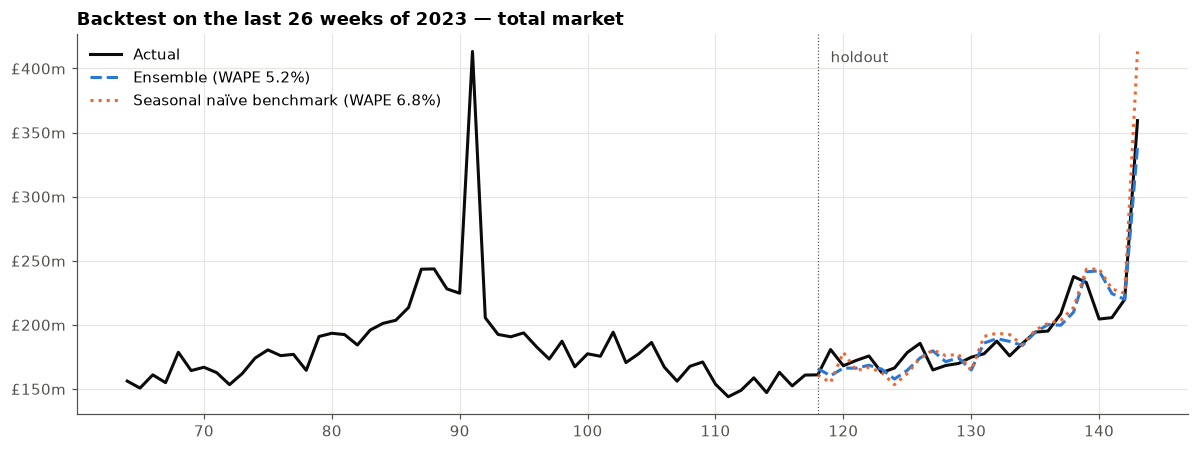

In [40]:
H = 26

def snaive(tr, h):
    return np.array([tr[-52 + (i % 52)] for i in range(h)])
def snaive_drift(tr, h):
    ratio = tr[-26:].sum() / tr[-52-26:-52].sum()
    return snaive(tr, h) * ratio ** (np.arange(h) // 52 + 1)   # compounds once per forecast year
def hw(tr, h, trend):
    m = ExponentialSmoothing(tr, trend=trend, damped_trend=trend is not None, seasonal="mul",
                             seasonal_periods=52, initialization_method="estimated").fit(optimized=True)
    return m.forecast(h)

cands = {"Seasonal naïve": snaive,
         "Seasonal naïve + drift": snaive_drift,
         "Holt-Winters (no trend)": lambda tr, h: hw(tr, h, None),
         "Holt-Winters (damped trend)": lambda tr, h: hw(tr, h, "add")}

def wape(a, f): return np.abs(a - f).sum() / a.sum()
def bias(a, f): return (f.sum() - a.sum()) / a.sum()

bt_rows, preds, chosen = [], {}, {}
for col, cat in [("cat1_value", "Category 1"), ("cat2_value", "Category 2")]:
    s = ts[col].values; tr, te = s[:-H], s[-H:]
    for name, fn in cands.items():
        f = fn(tr, H); preds[(cat, name)] = f
        bt_rows.append(dict(category=cat, model=name, WAPE=wape(te, f), bias=bias(te, f)))
    top2 = sorted([r for r in bt_rows if r["category"] == cat], key=lambda r: r["WAPE"])[:2]
    chosen[cat] = [r["model"] for r in top2]
    f_ens = np.mean([preds[(cat, m)] for m in chosen[cat]], axis=0); preds[(cat, "Ensemble")] = f_ens
    bt_rows.append(dict(category=cat, model="Ensemble (" + " + ".join(chosen[cat]) + ")", WAPE=wape(te, f_ens), bias=bias(te, f_ens)))

bt = pd.DataFrame(bt_rows)
# total-market view of each approach (sum of the two category forecasts)
te_tot = ts.mkt_value.values[-H:]
for name in list(cands) + ["Ensemble"]:
    f = preds[("Category 1", name)] + preds[("Category 2", name)]
    bt.loc[len(bt)] = dict(category="Total", model=name, WAPE=wape(te_tot, f), bias=bias(te_tot, f))
display(bt.sort_values(["category", "WAPE"]).style.format({"WAPE":"{:.1%}","bias":"{:+.1%}"}).hide(axis="index"))
print("Chosen per category:", chosen)

fig, ax = plt.subplots()
ax.plot(ts.t[-80:], ts.mkt_value.values[-80:], color=C["ink"], label="Actual")
ens_tot = preds[("Category 1", "Ensemble")] + preds[("Category 2", "Ensemble")]
sn_tot = preds[("Category 1", "Seasonal naïve")] + preds[("Category 2", "Seasonal naïve")]
w_ens = bt[(bt.category=="Total") & (bt.model=="Ensemble")].WAPE.iloc[0]
w_sn = bt[(bt.category=="Total") & (bt.model=="Seasonal naïve")].WAPE.iloc[0]
ax.plot(ts.t[-H:], ens_tot, color=C["dunelm"], ls="--", label=f"Ensemble (WAPE {w_ens:.1%})")
ax.plot(ts.t[-H:], sn_tot, color=C["cat2"], ls=":", label=f"Seasonal naïve benchmark (WAPE {w_sn:.1%})")
ax.axvline(ts.t.iloc[-H], color=C["ink2"], lw=0.8, ls=":")
ax.text(ts.t.iloc[-H] + 1, ax.get_ylim()[1] * 0.97, "holdout", color=C["ink2"], va="top")
ax.yaxis.set_major_formatter(gbp_m); ax.set_title("Backtest on the last 26 weeks of 2023 — total market")
ax.legend(loc="upper left")
save(fig, "q2_backtest")

### 7.3 Results: model selection by backtest

**How we approach it**
- **Test before trusting:** hide the last 26 weeks of 2023, fit each model on the earlier data, forecast those 26 weeks, and compare with what actually happened. The holdout includes Black Friday and Christmas, the hardest and most important weeks to forecast.
- **Two scores:**
  - **WAPE:** the average size of the error, weighted so big weeks count more (lower is better)
  - **Bias:** whether the model systematically over (+) or under (−) forecasts (closer to 0 is better)
- **Simple models only:** with under three years of history, complex models would overfit. Every model must beat the **seasonal naïve benchmark** ("same week last year") to be worth using.
- **Each category is modelled separately** (their seasonality differs), then added up.
- **Ensemble:** average the two best models per category. With one short holdout, the "winner" could just be lucky; averaging is more reliable.

**Results**
- **Category 1: the simplest model wins.** Seasonal naïve is best (WAPE 7.9%). Holt-Winters **under-forecasts by 6.2%**, reading the recent dip as a lasting fall. Both Holt-Winters versions give identical results, so the model found no trend worth keeping. Category 1's year is "like last year".
- **Category 2: Holt-Winters wins.** The no-trend version is best (WAPE 5.9%, bias −1.8%). The naïve models **over-forecast** (+1.4% to +4.6%) because they copy 2022's Christmas, which was bigger than 2023's.
- **Total market: the ensemble is the most accurate and least biased:** **WAPE 5.2%, bias −0.3%**, better than any single approach and clearly better than the naïve benchmark (6.8%).
- **What the chart shows:** the ensemble tracks the actual weekly pattern closely, including the build-up to Christmas. Both forecasts miss a short dip just before the final peak (weeks ~140–142), a **timing shift** in the Christmas weeks that no seasonal model can predict. The naïve benchmark **overshoots the final week** (~£415m vs £360m actual) by copying 2022's unusually large peak.
- **Honest caveats:**
  - The differences between models are small (about 1–2 points of WAPE) and come from **one 26-week test**, so they're indicative, not decisive.
  - The ensemble's near-zero total bias is partly **two errors cancelling out**: Category 1 over-forecasts (+3.2%) and Category 2 under-forecasts (−2.1%). Within each category, the ensemble is slightly worse than that category's best single model.

> **So what:** The chosen approach (a per-category ensemble of simple seasonal models) forecasts the most recent half-year with about **5% weekly error and almost no overall bias**, beating the naïve benchmark. That's good enough to project the market forward, while being clear that **the uncertainty is real** and comes from a short history and one test window. The forecast intervals in 7.4 reflect this.

### 7.4 Forecast 2024–2026 with prediction intervals
The chosen ensemble is refitted on all data for each category and summed. Intervals come from bootstrapping the backtest errors plus an annual level shock that compounds each year — so uncertainty widens with the horizon, as it should with this little history. Forecast years are on the same basis as the reported 2022–23 figures (which contain 53 weeks); a strict 52-week year would be ~2% (~£190m) lower.

In [41]:
HORIZON, NSIM = 52 * 3, 2000
rng = np.random.default_rng(42)
hist_reported = q("SELECT yr, SUM(mkt_value) v FROM clean_market_weekly WHERE is_full_year GROUP BY yr ORDER BY yr").set_index("yr").v

fc = {}
for col, cat in [("cat1_value", "Category 1"), ("cat2_value", "Category 2")]:
    s = ts[col].values
    point = np.mean([cands[m](s, HORIZON) for m in chosen[cat]], axis=0)
    rel_err = (s[-H:] - preds[(cat, "Ensemble")]) / preds[(cat, "Ensemble")]
    sims = point[None, :] * (1 + rng.choice(rel_err, size=(NSIM, HORIZON)))
    level_sd = max(abs(rel_err.mean()), 0.02)                       # floor of 2% a year
    shock = rng.normal(0, level_sd, size=(NSIM, 3)).cumsum(axis=1)  # compounds year on year
    sims *= (1 + np.repeat(shock, 52, axis=1))
    fc[cat] = (point, sims)

point_total = fc["Category 1"][0] + fc["Category 2"][0]
sims_total = fc["Category 1"][1] + fc["Category 2"][1]
annual_sims = sims_total.reshape(NSIM, 3, 52).sum(axis=2)
annual_point = point_total.reshape(3, 52).sum(axis=1)

forecast_tbl = pd.DataFrame({
    "year": [2022, 2023, 2024, 2025, 2026],
    "type": ["Actual", "Actual", "Forecast", "Forecast", "Forecast"],
    "market_value_£m": list(hist_reported.values / 1e6) + list(annual_point / 1e6),
    "P10_£m": [np.nan, np.nan] + list(np.percentile(annual_sims, 10, axis=0) / 1e6),
    "P90_£m": [np.nan, np.nan] + list(np.percentile(annual_sims, 90, axis=0) / 1e6),
    "Category 1_£m": list(q("SELECT SUM(mkt_value) v FROM clean_market_weekly WHERE is_full_year AND category='Category 1' GROUP BY yr ORDER BY yr").v / 1e6)
                     + list(fc["Category 1"][0].reshape(3, 52).sum(axis=1) / 1e6),
    "Category 2_£m": list(q("SELECT SUM(mkt_value) v FROM clean_market_weekly WHERE is_full_year AND category='Category 2' GROUP BY yr ORDER BY yr").v / 1e6)
                     + list(fc["Category 2"][0].reshape(3, 52).sum(axis=1) / 1e6),
})
forecast_tbl["YoY"] = forecast_tbl["market_value_£m"].pct_change()
display(forecast_tbl.style.format({**{c: "£{:,.0f}m" for c in forecast_tbl.columns if c.endswith("£m")},
                                   "YoY": "{:+.1%}"}, na_rep="").hide(axis="index"))

year,type,market_value_£m,P10_£m,P90_£m,Category 1_£m,Category 2_£m,YoY
2022,Actual,"£9,466m",,,"£3,390m","£6,077m",
2023,Actual,"£9,477m",,,"£3,364m","£6,113m",+0.1%
2024,Forecast,"£9,362m","£9,161m","£9,662m","£3,321m","£6,041m",-1.2%
2025,Forecast,"£9,229m","£8,944m","£9,615m","£3,280m","£5,949m",-1.4%
2026,Forecast,"£9,118m","£8,767m","£9,551m","£3,239m","£5,879m",-1.2%


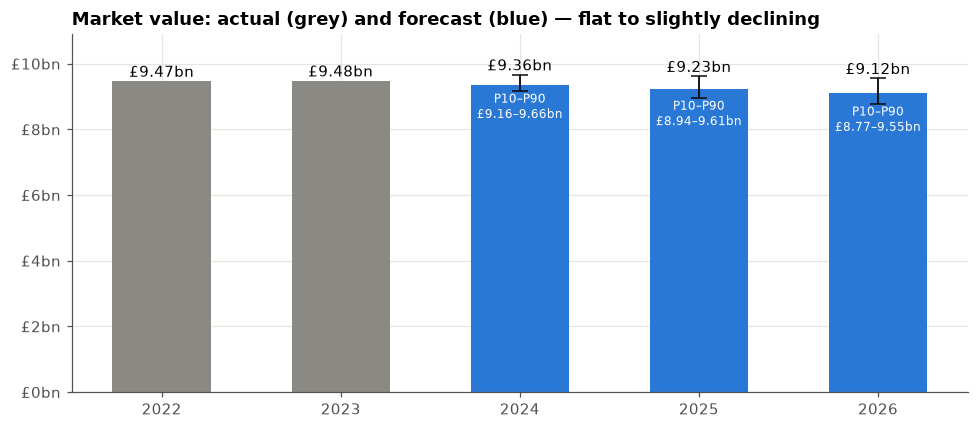

In [42]:
# Annual view is what the director needs; the weekly path is in the backtest chart above
fig, ax = plt.subplots(figsize=(9, 4))
yrs = forecast_tbl.year.astype(str)
vals = forecast_tbl["market_value_£m"].values * 1e6
is_fc = (forecast_tbl.type == "Forecast").values
bars = ax.bar(yrs, vals, color=np.where(is_fc, C["dunelm"], C["market"]), width=0.55)
lo = forecast_tbl["P10_£m"].values * 1e6; hi = forecast_tbl["P90_£m"].values * 1e6
ax.errorbar(yrs[is_fc], vals[is_fc], yerr=[vals[is_fc] - lo[is_fc], hi[is_fc] - vals[is_fc]],
            fmt="none", ecolor=C["ink"], elinewidth=1.2, capsize=5)
for b, v, l, h, f in zip(bars, vals, lo, hi, is_fc):
    ax.text(b.get_x() + b.get_width()/2, (h if f else v) * 1.003, f"£{v/1e9:,.2f}bn", ha="center", va="bottom", fontsize=9.5)
    if f: ax.text(b.get_x() + b.get_width()/2, l * 0.997, f"P10–P90\n£{l/1e9:.2f}–{h/1e9:.2f}bn", ha="center", va="top", fontsize=8, color="white")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"£{x/1e9:,.0f}bn")); ax.set_ylim(0, vals.max() * 1.15)
ax.set_title("Market value: actual (grey) and forecast (blue) — flat to slightly declining")
save(fig, "q2_forecast")

### 7.4 Results: market forecast 2024–2026

**How we approach it**
- **Refit the chosen models on all the data** (Category 1: seasonal naïve + drift; Category 2: Holt-Winters), forecast 3 years of weeks, add the two categories together and sum to annual totals.
- **Same basis as the actuals:** week 53 is folded into week 52, so each forecast year contains the same number of weeks' sales as the reported 2022 and 2023. Year-on-year changes are like-for-like.
- **Uncertainty from real errors, not assumptions:** 2,000 simulations, each adding (a) weekly errors drawn from the backtest and (b) a yearly level shock that **compounds over time**. The **P10–P90 range** is the middle 80% of outcomes: there's a 1-in-10 chance of being below P10 and 1-in-10 above P90.
- **Uncertainty widens each year,** as it should with less than three years of history.

**Results**

| Year | Market | 80% range | Change |
|---|---|---|---|
| 2023 (actual) | £9.48bn | | +0.1% |
| 2024 | **£9.36bn** | £9.16–9.66bn | −1.2% |
| 2025 | **£9.23bn** | £8.94–9.61bn | −1.4% |
| 2026 | **£9.12bn** | £8.77–9.55bn | −1.2% |

- **Central forecast: a slow decline of about 1.2–1.4% a year**, about **−3.8% (−£0.36bn) by 2026**. The underlying trend that turned down during 2023 (7.1) continues gently.
- **Both categories decline at a similar pace:** Category 1 from £3.36bn to £3.24bn, Category 2 from £6.11bn to £5.88bn (about −1.2% a year each).
- **The range widens from about £0.5bn in 2024 to about £0.8bn in 2026.**
- **Growth isn't ruled out, but it's the less likely outcome.** The top of the range (P90) is slightly above the 2023 level in every year, while the central forecast and the bottom of the range point down.
- **Caveat:** the forecast extends the recent past. It assumes the 2023 pattern (falling volumes partly offset by rising prices) continues. It can't anticipate changes in inflation, housing or consumer confidence; those are covered by the scenarios in 7.5.

> **So what:** Plan for a **flat-to-slightly-declining market: about £9.4bn in 2024 easing to about £9.1bn by 2026** (80% range £8.8–9.6bn). Market growth won't carry Dunelm, so **any growth has to come from taking share**. As a guide, holding 2023's share of 8.5% in a market of £9.12bn would mean Dunelm sales *falling* by about £30m by 2026.

### 7.5 Scenarios — what could move the market?
The statistical forecast extrapolates the past. A driver view makes the assumptions explicit: **market value = volume × price**. Three scenarios bracket the plausible range; the inputs are judgement calls to be agreed with the business (and refreshed with ONS retail sales, CPI for household goods, and housing transaction data).

In [43]:
base_2023 = hist_reported[2023]        # same basis as the statistical forecast
vol_trend = mkt_pv[mkt_pv.yr == 2023].assign(w=lambda d: d.value / d.value.sum()).eval("volume_g * w").sum()
asp_trend = mkt_pv[mkt_pv.yr == 2023].assign(w=lambda d: d.value / d.value.sum()).eval("asp_g * w").sum()
print(f"Observed 2023 (weeks 14–52): volume {vol_trend:+.1%}, ASP {asp_trend:+.1%}")

scen = pd.DataFrame({
    "scenario": ["Downside", "Base", "Upside"],
    "volume_growth_pa": [-0.05, -0.03, 0.00],
    "price_growth_pa":  [ 0.01,  0.03,  0.03],
    "narrative": [
        "Weak consumer confidence, low housing transactions; inflation falls fast so price no longer offsets volume loss",
        "Volume decline eases as real incomes recover; price inflation normalises to ~3%",
        "Housing market recovers (moving home drives homewares), volumes stabilise, price holds",
    ]})
for i, yy in enumerate([2024, 2025, 2026], start=1):
    scen[str(yy)] = base_2023 * ((1 + scen.volume_growth_pa) * (1 + scen.price_growth_pa)) ** i / 1e6
display(scen.style.format({"volume_growth_pa":"{:+.0%}","price_growth_pa":"{:+.0%}","2024":"£{:,.0f}m","2025":"£{:,.0f}m","2026":"£{:,.0f}m"}).hide(axis="index"))

Observed 2023 (weeks 14–52): volume -6.0%, ASP +5.4%


scenario,volume_growth_pa,price_growth_pa,narrative,2024,2025,2026
Downside,-5%,+1%,"Weak consumer confidence, low housing transactions; inflation falls fast so price no longer offsets volume loss","£9,093m","£8,725m","£8,371m"
Base,-3%,+3%,Volume decline eases as real incomes recover; price inflation normalises to ~3%,"£9,468m","£9,460m","£9,451m"
Upside,+0%,+3%,"Housing market recovers (moving home drives homewares), volumes stabilise, price holds","£9,761m","£10,054m","£10,356m"


### 7.5 Results: scenarios, what could move the market?

**How we approach it**
- **Why scenarios as well as a forecast:** the statistical forecast (7.4) only extends the past. It can't know if inflation will fall or the housing market will recover. Scenarios make those assumptions **explicit**, so they can be challenged and updated.
- **Simple driver model: market value = volume × price.** Each scenario sets an annual growth rate for volume and price, applied to 2023's actual market (£9.48bn).
- **Anchored on what's happening now:** in 2023 market volume fell **about 6%** and price per unit rose **about 5%** (7.2). The scenarios ask what happens as those trends ease, worsen or reverse.
- **The inputs are judgement calls,** labelled as such, to be agreed with the business and refreshed with external data (household-goods inflation, housing transactions, consumer confidence).

**Results**

| Scenario | Volume / yr | Price / yr | Value / yr | 2024 | 2026 | Story |
|---|---|---|---|---|---|---|
| **Downside** | −5% | +1% | ≈ −4% | £9.09bn | **£8.37bn** | Weak confidence and housing; inflation falls fast, so price no longer offsets falling volume |
| **Base** | −3% | +3% | ≈ flat | £9.47bn | **£9.45bn** | Volume decline eases as real incomes recover; inflation settles at ~3% |
| **Upside** | 0% | +3% | ≈ +3% | £9.76bn | **£10.36bn** | Housing market recovers (moving home drives homewares), volumes stabilise |

- **The range by 2026 is wide: about £8.4bn to £10.4bn**, roughly ±£1bn around today's market. The direction depends mostly on **whether volume keeps falling** and **how fast inflation eases**.
- **Even the base case only holds the market flat.** It assumes the volume decline halves (from −6% to −3%) *and* prices keep rising 3% a year.
- **The statistical forecast (£9.12bn in 2026) sits between the downside and base scenarios.** Both methods point to a **flat-to-declining market**; growth needs volumes to stop falling.
- **What this means for Dunelm if it only holds its 2023 share (8.5%):**
  - Downside: about **£712m** in 2026 (−£94m vs 2023)
  - Base: about **£804m** (flat)
  - Upside: about **£881m** (+£75m)

## Q2 summary: market outlook to 2026 and what could change it

**Factors that could change the market size**

| Driver | Direction | Evidence in our data / why it matters |
|---|---|---|
| **Price inflation** (household goods) | ↑ value now, ↓ as it eases | **The biggest swing factor.** In 2023, price per unit rose ~5% while volume fell ~6%, so inflation alone held value flat. Category 1 shows what happens next: price growth slowed from +13% to +2% and value fell 2.7% |
| **Volume trend** (units bought) | ↓ currently | Market units fell in **both 2022 and 2023, in both categories**. The scenarios hinge on whether this decline eases (base), continues (downside) or stops (upside) |
| **Housing transactions & mortgage rates** | ↑/↓ | Moving home is the biggest trigger for homewares and furniture purchases; a housing recovery is the main route to the upside scenario |
| **Real disposable income & consumer confidence** | ↑/↓ | Spending is discretionary; big-ticket items are delayed first, which hits volume |
| **Promotional calendar** (Black Friday, Christmas, January sales) | Shifts timing | A few weeks carry a large part of the year: the January peak is ~12% of Category 1's market, Black Friday–Christmas ~16% of Category 2's. Deeper promotions shift spend between weeks and lower price per unit |
| **Channel shift & new entrants** (marketplaces, low-cost online players) | ↓ for incumbents | Can add volume but push average prices down and take share from traditional retailers |
| **Retailer exits/closures** | Redistributes share | Spend moves to remaining players: an opportunity if Dunelm captures it |
| **Weather / energy costs** | Mixed | Seasonal products (bedding, heating-related items) respond to cold snaps; high energy bills squeeze discretionary spend |

> **So what (Q2): what will the market be worth?**
>
> **Answer in one line:** Plan for a **flat-to-slightly-declining market: about £9.4bn in 2024 easing to about £9.1bn by 2026** (80% range £8.8–9.6bn), held up by price while volumes fall.
>
> - **The trend has turned.** The market's underlying level peaked around the start of 2023 and declined through the year (−1.3%), even though the full-year total was flat (+0.1%).
> - **Value is held up by inflation, not demand.** Units fell for two years running in both categories; rising prices kept value flat. As inflation eases, value drifts down unless volume recovers.
> - **The forecast is tested, not assumed.** A per-category ensemble of simple seasonal models beat the naïve benchmark on the last 26 weeks of 2023 (**5.2% weekly error, almost no bias**). It projects about **−1.2% a year**, with uncertainty widening each year.
> - **Scenarios bracket the risk: £8.4bn (downside) to £10.4bn (upside) by 2026.** The statistical forecast sits **between the base and downside cases**. Growth needs volumes to stop falling, most likely through a housing recovery.
> - **Implication for Dunelm:** **holding today's 8.5% share is not enough.** It would mean sales of about £776m by 2026 on the central forecast (about −£30m vs 2023), and about £712m in the downside case. **Growth has to come from taking share.**
> - **What to watch:** household-goods inflation, housing transactions and consumer confidence. **Refresh the forecast quarterly** as new data arrives; the history behind it is under three years.

---
# Q3 · Where can Dunelm grow?

Five evidence-based growth levers, each sized with one transparent assumption: reach, basket value, Category 1 cross-sell, peak timing and light-shopper frequency.

### 8.1 Reach — penetration headroom by social class

In [44]:
reach = q('''
WITH p AS (
    SELECT grade_group,
        MAX(CASE WHEN retailer='Total Market' THEN households END) total_hh,
        MAX(CASE WHEN retailer='Dunelm' THEN households END)       dunelm_hh,
        MAX(CASE WHEN retailer='Competitor B' THEN households END) comp_b_hh
    FROM clean_market_hh GROUP BY grade_group
),
mix AS (
    SELECT *, dunelm_hh / SUM(dunelm_hh) OVER () AS dunelm_mix, total_hh / SUM(total_hh) OVER () AS market_mix FROM p
)
SELECT grade_group, total_hh, dunelm_hh,
       dunelm_hh / total_hh                AS dunelm_penetration,
       comp_b_hh / total_hh                AS comp_b_penetration,
       100 * dunelm_mix / market_mix       AS dunelm_profile_index,
       0.01 * total_hh                     AS hh_per_1pp_penetration
FROM mix ORDER BY CASE grade_group WHEN 'AB' THEN 1 WHEN 'C1' THEN 2 WHEN 'C2' THEN 3 WHEN 'D' THEN 4 ELSE 5 END
''')
display(reach.style.format({"total_hh":"{:,.0f}","dunelm_hh":"{:,.0f}","dunelm_penetration":"{:.1%}",
                            "comp_b_penetration":"{:.1%}","dunelm_profile_index":"{:.0f}","hh_per_1pp_penetration":"{:,.0f}"}).hide(axis="index"))

grade_group,total_hh,dunelm_hh,dunelm_penetration,comp_b_penetration,dunelm_profile_index,hh_per_1pp_penetration
AB,"7,086,605","2,288,023",32.3%,53.8%,104,"70,866"
C1,"8,077,562","2,591,040",32.1%,57.8%,103,"80,776"
C2,"3,855,828","1,196,878",31.0%,64.6%,100,"38,558"
D,"4,767,949","1,375,301",28.8%,67.7%,93,"47,679"
E,"2,535,275","721,968",28.5%,65.3%,92,"25,353"


### 8.1 Results: reach, penetration headroom by social class

**How we approach it**
- **Share = reach × depth.** Before looking at how much customers spend, we check how many market households shop at Dunelm at all. That's usually the biggest growth lever for a retailer.
- **Competitor B is the benchmark for what's possible:** its penetration shows how much reach the market can support.
- **Three measures per social class:**
  - **Penetration gap vs Competitor B:** how much headroom exists
  - **Dunelm profile index** = Dunelm's share of its shoppers in that class ÷ the market's share × 100. Above 100 = over-represented; below 100 = under-represented. It tells us if the gap is a **demographic blind spot** or a **general reach issue**.
  - **Households per +1pp of penetration:** how much one extra point of reach is worth, in households, in each class

**Results**
- **Dunelm's reach is fairly even across classes:** 32% in AB/C1, 31% in C2, 28–29% in D/E.
- **The profile is balanced:** index **92–104**, slightly over-represented in AB/C1 (103–104) and slightly under in D/E (92–93). **No class is missing**, so the gap is about **overall reach**, not a demographic blind spot.
- **The gap to Competitor B grows as social grade falls:**
  - AB: 32% vs 54% (**−21.5pp**)
  - C1: 32% vs 58% (−25.7pp)
  - C2/D/E: 29–31% vs **65–68%** (**−34 to −39pp**)
- **Where one point of reach is worth most:**
  - **C1:** 81k households per +1pp, the largest pool (8.1m households)
  - **AB:** 71k per +1pp
  - **C2/D/E together:** 112k per +1pp, and where the gap is widest (11.2m households, 42% of the market)
  - **In total: +1pp of penetration ≈ 263k households.**
- **Caveat:** Market Data 2 doesn't show how many households shop at *both* Dunelm and Competitor B, so the gap shows headroom, not how many B shoppers are already Dunelm customers.

> **So what:** Dunelm's reach is **broad but shallow**: about 3 in 10 households in every class. The biggest headroom is in **C2/D/E**, where Competitor B reaches about 2 in 3 households and Dunelm under 1 in 3. Since price seekers spend almost as much as other customers in the same grade (5b.3), winning these households **adds volume without diluting value**. The largest single pool for each extra point of reach is **C1**.

### 8.2 Customer value by segment, grade and price sensitivity (internal data)

In [45]:
seg = q('''
SELECT segment, yr,
       SUM(customers) customers,
       SUM(customers) / SUM(SUM(customers)) OVER (PARTITION BY yr) AS customer_mix,
       SUM(sales_value) / SUM(SUM(sales_value)) OVER (PARTITION BY yr) AS sales_mix,
       SUM(orders)/SUM(customers) freq, SUM(sales_value)/SUM(orders) aov, SUM(sales_value)/SUM(customers) spc,
       SUM(units)/SUM(orders) upo, SUM(sales_value)/SUM(units) ppu
FROM clean_internal GROUP BY segment, yr ORDER BY segment, yr
''')
display(seg.style.format({"customers":"{:,.0f}","customer_mix":"{:.1%}","sales_mix":"{:.1%}","freq":"{:.2f}",
                          "aov":"£{:.2f}","spc":"£{:.2f}","upo":"{:.2f}","ppu":"£{:.2f}"}).hide(axis="index"))

ps = q('''
SELECT grade_group, yr,
       SUM(CASE WHEN price_seeker_flag=1 THEN customers END) / SUM(customers) AS pct_price_seekers,
       SUM(sales_value) / SUM(customers) AS spend_per_customer,
       SUM(CASE WHEN price_seeker_flag=1 THEN sales_value END)/SUM(CASE WHEN price_seeker_flag=1 THEN customers END) AS spc_price_seeker,
       SUM(CASE WHEN price_seeker_flag=0 THEN sales_value END)/SUM(CASE WHEN price_seeker_flag=0 THEN customers END) AS spc_other
FROM clean_internal GROUP BY GROUPING SETS ((grade_group, yr), (yr))
ORDER BY yr, grade_group NULLS LAST
''')
ps["grade_group"] = ps["grade_group"].fillna("All")
display(ps[ps.yr == 2023].style.format({"pct_price_seekers":"{:.0%}","spend_per_customer":"£{:.2f}",
                                         "spc_price_seeker":"£{:.2f}","spc_other":"£{:.2f}"}).hide(axis="index"))

segment,yr,customers,customer_mix,sales_mix,freq,aov,spc,upo,ppu
Segment1,2022,"1,641,858",26.1%,14.6%,1.19,£57.11,£67.79,2.90,£19.68
Segment1,2023,"1,565,910",24.0%,16.4%,1.41,£59.94,£84.66,3.12,£19.18
Segment2,2022,"2,019,123",32.0%,25.8%,1.50,£64.70,£97.37,4.26,£15.19
Segment2,2023,"2,061,856",31.6%,27.9%,1.71,£63.69,£109.23,3.99,£15.97
Segment3,2022,"2,641,719",41.9%,59.6%,3.18,£54.14,£172.08,4.05,£13.38
Segment3,2023,"2,897,568",44.4%,55.6%,3.13,£49.55,£154.91,3.73,£13.30


grade_group,yr,pct_price_seekers,spend_per_customer,spc_price_seeker,spc_other
AB,2023,9%,£140.06,£137.73,£140.28
C1,2023,40%,£120.28,£119.43,£120.85
C2,2023,27%,£120.27,£120.18,£120.30
D,2023,71%,£110.89,£109.51,£114.21
E,2023,48%,£105.23,£103.95,£106.44
All,2023,34%,£123.62,£117.73,£126.65


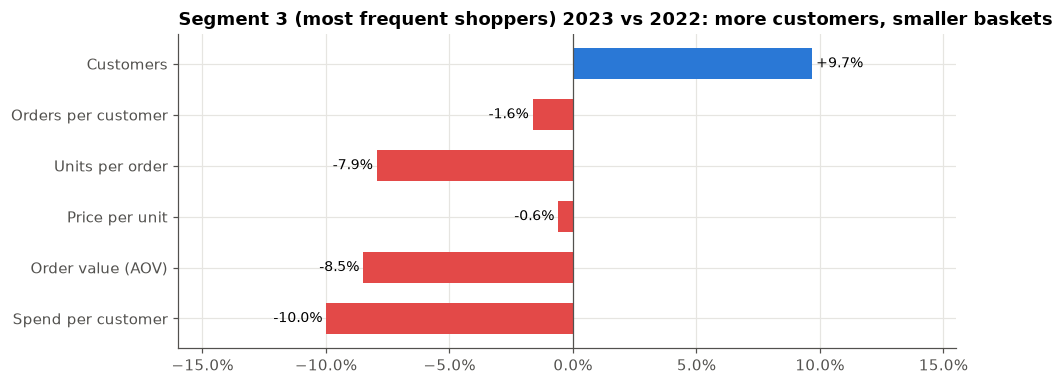

In [46]:
# Segment 3: customers up, basket down — what is happening to the basket?
s3 = seg[seg.segment == "Segment3"].set_index("yr")
chg = pd.Series({"Customers": s3.customers[2023]/s3.customers[2022]-1,
                 "Orders per customer": s3.freq[2023]/s3.freq[2022]-1,
                 "Units per order": s3.upo[2023]/s3.upo[2022]-1,
                 "Price per unit": s3.ppu[2023]/s3.ppu[2022]-1,
                 "Order value (AOV)": s3.aov[2023]/s3.aov[2022]-1,
                 "Spend per customer": s3.spc[2023]/s3.spc[2022]-1})
fig, ax = plt.subplots(figsize=(9, 3.6))
cols = [C["dunelm"] if v >= 0 else C["neg"] for v in chg]
bars = ax.barh(chg.index[::-1], chg.values[::-1], color=cols[::-1], height=0.6)
for b, v in zip(bars, chg.values[::-1]):
    ax.text(v, b.get_y() + b.get_height()/2, f" {v:+.1%} ", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color=C["ink2"], lw=0.8); ax.xaxis.set_major_formatter(pct)
ax.set_xlim(chg.min() * 1.6, chg.max() * 1.6)
ax.set_title("Segment 3 (most frequent shoppers) 2023 vs 2022: more customers, smaller baskets")
save(fig, "q3_segment3")

**Segment 3 in detail: what's behind the falling spend (chart)**

The drivers multiply: **spend per customer = orders per customer × units per order × price per unit**.

| Driver | Change 2022 → 2023 | Share of the spend decline |
|---|---|---|
| Customers | **+9.7%** | (more customers, not part of spend per customer) |
| Orders per customer | −1.6% | ~15% |
| **Units per order** | **−7.9%** | **~80%** |
| Price per unit | −0.6% | ~5% |
| → Order value (AOV) | −8.5% | |
| → **Spend per customer** | **−10.0%** | 100% |

- **About 80% of Segment 3's fall in spend per customer comes from fewer items per order** (4.05 → 3.73). Frequency (−1.6%) and price per unit (−0.6%) barely moved.
- **Customers kept coming back almost as often and paid the same prices; they just put fewer items in the basket.** That rules out "Dunelm got cheaper" or "customers visit less" as the explanation.
- **Customer growth (+9.7%) was cancelled out by lower spend per customer (−10%),** which is why Segment 3's total sales fell 1.3% despite about 256k more customers.
- **Possible causes to investigate:** a shift towards **single-item, need-led trips** (often online or click-and-collect), fewer **add-on purchases** at the till or checkout, or new Segment 3 customers who buy smaller baskets than established ones.

### 8.3 Opportunity sizing
Each lever is sized on 2023 actuals with a stated, deliberately moderate assumption. The levers overlap (e.g. new customers also buy at peak), so **they are not additive** — the point is the relative size and the assumption behind each.

opportunity,value_£,assumption,confidence,% of 2023 Dunelm sales
Reach: +1pp household penetration,£22.3m,"+1pp of 26.3m market households, spending like Segment 1 (£85)",Medium,2.8%
Basket: recover half of Segment 3 AOV fall,£20.8m,Segment 3 AOV back half-way to 2022 level,High,2.6%
Category 1: +0.5pp share,£16.8m,Cross-sell to existing shoppers; Cat1 share 6.5% vs Cat2 9.6%,High,2.1%
Peak: close half the peak share gap,£7.8m,Peak-week share moves half-way to non-peak share (both categories),Medium,1.0%
Frequency: 10% of Segment 1 → Segment 2 behaviour,£3.8m,10% of light shoppers reach mid-segment spend,Medium,0.5%


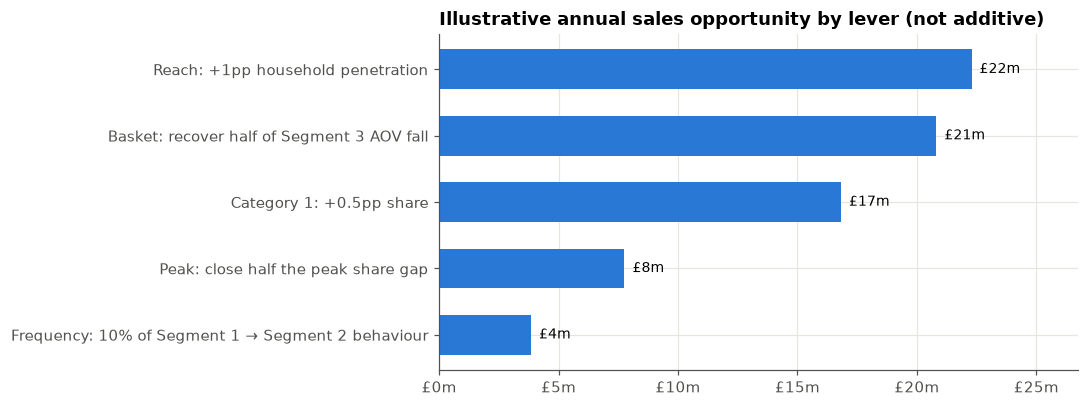

In [47]:
spc_all = kpi[(kpi.segment=="Total") & (kpi.yr==2023)].spend_per_customer.iloc[0]
spc_new = seg[(seg.segment=="Segment1") & (seg.yr==2023)].spc.iloc[0]  # new / light shoppers likely look like Segment 1
total_hh = reach.total_hh.sum()

# 1) Reach: +1pp penetration, new households spend like Segment 1 (light) shoppers
opp_reach = 0.01 * total_hh * spc_new

# 2) Peak share: close half of the peak-vs-non-peak share gap (2023), per category
p23 = q('''
SELECT category,
       SUM(CASE WHEN is_peak THEN mkt_value END) AS peak_mkt,
       SUM(CASE WHEN is_peak THEN dun_value END) / SUM(CASE WHEN is_peak THEN mkt_value END) AS sh_peak,
       SUM(CASE WHEN NOT is_peak THEN dun_value END) / SUM(CASE WHEN NOT is_peak THEN mkt_value END) AS sh_np
FROM mart_peak WHERE yr = 2023 GROUP BY category
''')
opp_peak = (p23.peak_mkt * (p23.sh_np - p23.sh_peak).clip(lower=0) / 2).sum()

# 3) Category 1 share +0.5pp (cross-sell into existing shoppers)
cat1_mkt = q("SELECT mkt_value FROM mart_annual WHERE yr=2023 AND category='Category 1'").mkt_value.iloc[0]
opp_cat1 = 0.005 * cat1_mkt

# 4) Segment 3 basket: recover half of the 2022→2023 AOV decline
s3o = seg[(seg.segment=="Segment3")].set_index("yr")
opp_aov = 0.5 * (s3o.aov[2022] - s3o.aov[2023]) * (s3o.customers[2023] * s3o.freq[2023])

# 5) Frequency: move 10% of Segment 1 customers to Segment 2 spend levels
s1 = seg[(seg.segment=="Segment1") & (seg.yr==2023)].iloc[0]; s2 = seg[(seg.segment=="Segment2") & (seg.yr==2023)].iloc[0]
opp_freq = 0.10 * s1.customers * (s2.spc - s1.spc)

opps = pd.DataFrame([
    ("Reach: +1pp household penetration", opp_reach, "+1pp of 26.3m market households, spending like Segment 1 (£%.0f)" % spc_new, "Medium"),
    ("Peak: close half the gap (Jan Cat 1; BF–Christmas Cat 2)", opp_peak, "Peak-week share moves half-way to other-week share; indicative, depends on peak definition (6.6)", "Medium"),
    ("Category 1: +0.5pp share", opp_cat1, "Cross-sell to existing shoppers; Cat1 share 6.5% vs Cat2 9.6%", "High"),
    ("Basket: recover half of Segment 3 AOV fall", opp_aov, "Segment 3 AOV back half-way to 2022 level", "High"),
    ("Frequency: 10% of Segment 1 → Segment 2 behaviour", opp_freq, "10% of light shoppers reach mid-segment spend", "Medium"),
], columns=["opportunity", "value_£", "assumption", "confidence"]).sort_values("value_£", ascending=False)
opps["% of 2023 Dunelm sales"] = opps["value_£"] / kpi[(kpi.segment=="Total") & (kpi.yr==2023)].sales_value.iloc[0]
display(opps.style.format({"value_£": lambda v: f"£{v/1e6:,.1f}m", "% of 2023 Dunelm sales": "{:.1%}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(10, 3.8))
o = opps.iloc[::-1]
bars = ax.barh(o.opportunity, o["value_£"], color=C["dunelm"], height=0.6)
for b, v in zip(bars, o["value_£"]):
    ax.text(v, b.get_y() + b.get_height()/2, f"  £{v/1e6:,.0f}m", va="center", fontsize=9)
ax.xaxis.set_major_formatter(gbp_m); ax.set_xlim(0, o["value_£"].max() * 1.2)
ax.set_title("Illustrative annual sales opportunity by lever (not additive)")
save(fig, "q3_opportunity_sizing")

### 8.3 Results: opportunity sizing

**How we approach it**
- **Turn findings into priorities:** each opportunity comes from a Q1 weak spot and is valued using 2023 actuals plus **one stated, moderate assumption**, so anyone can challenge it and the number scales directly.
- **Deliberately conservative:** new households are valued at **light-shopper spend** (Segment 1, £85), not the average (£124); recoveries are "halfway", not full.
- **Confidence reflects control:** levers that work with **existing customers and Dunelm's own decisions** (range, bundles, cross-sell) are rated higher than those that need to change market behaviour (reach, peaks).
- **Not additive:** the levers overlap (e.g. cross-selling Category 1 also raises basket size; new customers also shop at peak). The chart shows **relative size**, not a total.

**Results**

| Rank | Opportunity | Annual value | % of 2023 sales | Confidence |
|---|---|---|---|---|
| 1 | **Reach:** +1pp household penetration | **£22.3m** | 2.8% | Medium |
| 2 | **Basket:** recover half of Segment 3's AOV fall | **£20.8m** | 2.6% | **High** |
| 3 | **Category 1:** +0.5pp share via cross-sell | **£16.8m** | 2.1% | **High** |
| 4 | **Peak:** close half the share gap in January (Cat 1) and Black Friday → Christmas (Cat 2) | £7.8m | 1.0% | Medium, indicative |
| 5 | **Frequency:** 10% of Segment 1 shop like Segment 2 | £3.8m | 0.5% | Medium |

- **Reach and basket are the two biggest levers, about £21–22m each.** They work on different things: reach brings **new households**, basket gets **more from the loyal core**.
- **Reach has the most upside:** the estimate scales directly. **+2pp ≈ £45m**, and if new households spent like the average customer (£124), **+1pp ≈ £33m**. Competitor B's 60% shows how far there is to go.
- **Basket and Category 1 are the highest-confidence levers (~£38m between them):**
  - The basket problem is **fewer items per order**, which Dunelm can address directly (bundles, "complete the room", add-on prompts).
  - Category 1 is **already priced at market level**, so the gap is about awareness and cross-selling, not price.
  - They partly overlap: selling more Category 1 items to existing shoppers also raises basket size.
- **Peak and frequency are smaller but quick and cheap to test,** good candidates for early pilots. The peak value depends on how peak weeks are defined (6.6), so treat it as an order of magnitude.
- **Not yet sized:** the **late-summer dip in Category 2** (weeks 33–38, share ~6.9% vs ~9.5% the rest of the year). Worth confirming whether it's a deliberate trading choice before sizing it.

> **So what (Q3):** Dunelm has **five clear growth levers worth about £4–22m a year each**. In a flat-to-declining market, holding share alone would cost about **£30m by 2026** (Q2), so **no single lever is enough: Dunelm needs two or three working together**. The recommended priority:
> 1. **Fix the basket in the loyal core** (high confidence, existing customers)
> 2. **Grow reach in C2/D/E households**, where the gap to Competitor B is largest and price seekers spend almost as much as others (biggest upside)
> 3. **Cross-sell Category 1** (high confidence, priced at market already)
>
> **Peak timing** and **light-shopper frequency** follow as quick, low-cost tests.

### Q3 summary: where can Dunelm grow?

> **So what (Q3):**
>
> **Answer in one line:** In a flat-to-declining market, Dunelm's growth has to come from **reaching more households** and **getting more from its loyal core**. Five levers are worth about **£4–22m a year each**, and holding share alone would cost about £30m by 2026, so **two or three need to work together**.
>
> - **Reach is the biggest prize (~£22m per +1pp of penetration).** Dunelm reaches about 3 in 10 households in every class (28–32%), with a balanced profile (index 92–104), so this is a **reach and relevance issue, not a demographic blind spot**. The gap to Competitor B is widest in **C2/D/E**, where B reaches 65–68%. The £22m is conservative (light-shopper spend); at average spend, +1pp is worth about £33m. C1 is the largest single pool (81k households per point).
> - **Fix basket leakage in the loyal core (~£21m, highest confidence).** Segment 3 drives 56% of sales; its customers grew 9.7%, but spend per customer fell 10%. **About 80% of that fall comes from fewer items per order**, while visits and prices held steady. The lever is **cross-selling, bundles, "complete the room" and add-on prompts**, all within Dunelm's control and with customers it already has.
> - **Category 1 under-indexes (~£17m per +0.5pp, high confidence).** Share is 6.5% vs 9.6% in Category 2, despite pricing almost in line with the market (index 102). It's a **cross-sell and awareness gap** among people who already shop at Dunelm.
> - **Compete on the customer's calendar (~£8m, indicative).** Dunelm under-trades **January in Category 1** (robust across every test) and the **Black Friday → Christmas run in Category 2**, then wins share back in its own post-Christmas sale. It currently trades on its own sale calendar rather than when customers spend most.
> - **Price seekers are an opportunity, not a risk.** They're 34% of customers (71% in grade D) and growing faster (+5.2% vs +2.7%). **Within each grade they spend almost as much as other customers** (0–4% less); the overall 7% gap is mostly because they're concentrated in lower-spending grades. Winning value-conscious C2/D/E households can add customers **without diluting spend**, as long as Dunelm competes on **value perception, not deeper discounts** that shrink baskets.
> - **Move light shoppers up (~£4m, quick to test).** Segment 1 frequency already rose 19%. Nudging 10% of light shoppers to mid-segment behaviour is a low-cost CRM test.
> - **Still to investigate:** the recurring **late-summer dip in Category 2** (weeks 33–38, share ~6.9% vs ~9.5%). Confirm whether it's deliberate before sizing it.
>
> **Recommended priority:** (1) fix the basket in the loyal core, (2) grow reach in C2/D/E households, (3) cross-sell Category 1. Then pilot peak timing and light-shopper frequency as quick, low-cost tests.

---
# Q4 · What should Dunelm do, and how will we know it worked?

### 9.1 Action plan
| # | Play | Actions | Primary KPI | Guardrail KPIs | How we measure |
|---|---|---|---|---|---|
| 1 | **Reach new households** | Brand media in under-penetrated regions; marketplace & partnership listings; local store activation; refer-a-friend | Household penetration (Market Data 2), new-customer count | Marketing cost per new customer; new-customer 2nd-order rate | **Geo test & control** (matched regions, synthetic control) |
| 2 | **Win the peak** | Black Friday / Christmas range & gifting edit; peak-specific promotions and availability; CRM countdown | Value share in peak weeks (Market Data 1) | Gross margin %; share in non-peak weeks (no cannibalisation) | **Difference-in-differences**: peak share change minus non-peak share change, vs prior year |
| 3 | **Category 1 cross-sell** | Personalised recommendations; "complete the room" bundles; in-store adjacencies | % of customers buying Category 1; Category 1 share | Category 2 sales per customer; returns | **Randomised CRM holdout** (customer level) |
| 4 | **Grow basket value** | Free-delivery threshold tests; bundles & multibuy; Segment 3 loyalty rewards tied to basket size | AOV & units per order (Segment 3) | Frequency (don't trade visits for baskets); margin | **A/B test** on threshold/bundles; CRM holdout |
| 5 | **Move light shoppers up** | Triggered journeys after first purchase; seasonal reminders | Orders per customer; migration Segment 1 → 2 | Unsubscribe rate; discount depth | **Randomised CRM holdout** |

### 9.2 KPI baseline (2023) — the scorecard we would track

In [48]:
pk = peak[peak.yr == 2023].set_index("category")
scorecard = pd.DataFrame([
    ("Market",   "Market value (£m)",                    hist_reported[2023] / 1e6,                   "£{:,.0f}m"),
    ("Share",    "Dunelm value share",                   headline.set_index("category").value_share_2023["Total"], "{:.2%}"),
    ("Share",    "Category 1 value share",               headline.set_index("category").value_share_2023["Category 1"], "{:.2%}"),
    ("Share",    "Peak-week value share, Category 2",    pk.share_peak["Category 2"],              "{:.2%}"),
    ("Reach",    "Household penetration",                pen_w.loc["All","Dunelm"],                "{:.1%}"),
    ("Customer", "Active customers (m)",                 kpi[(kpi.segment=='Total')&(kpi.yr==2023)].customers.iloc[0]/1e6, "{:.2f}m"),
    ("Customer", "Orders per customer",                  kpi[(kpi.segment=='Total')&(kpi.yr==2023)].freq.iloc[0], "{:.2f}"),
    ("Customer", "Average order value",                  kpi[(kpi.segment=='Total')&(kpi.yr==2023)].aov.iloc[0], "£{:.2f}"),
    ("Customer", "Segment 3 AOV",                        s3o.aov[2023],                            "£{:.2f}"),
    ("Customer", "Spend per customer",                   spc_all,                                  "£{:.2f}"),
    ("Share",    "Peak-week value share, Category 1 (January)", pk.share_peak["Category 1"],     "{:.2%}"),
    ("Reach",    "Household penetration, C2/D/E",
                 reach[reach.grade_group.isin(["C2","D","E"])].dunelm_hh.sum()
                 / reach[reach.grade_group.isin(["C2","D","E"])].total_hh.sum(),                 "{:.1%}"),
    ("Customer", "Segment 3 items per order",                   s3o.upo[2023],                    "{:.2f}"),
    ("Customer", "Segment 1 orders per customer",               s1.freq,                          "{:.2f}"),
], columns=["area", "kpi", "baseline_2023", "fmt"])
scorecard["baseline_2023"] = [f.format(v) for v, f in zip(scorecard.baseline_2023, scorecard.fmt)]
display(scorecard.drop(columns="fmt").style.hide(axis="index"))

area,kpi,baseline_2023
Market,Market value (£m),"£9,477m"
Share,Dunelm value share,8.51%
Share,Category 1 value share,6.51%
Share,"Peak-week value share, Category 2",8.50%
Reach,Household penetration,31.0%
Customer,Active customers (m),6.53m
Customer,Orders per customer,2.27
Customer,Average order value,£54.48
Customer,Segment 3 AOV,£49.55
Customer,Spend per customer,£123.62


### 9.2 Results: KPI baseline (2023 scorecard)

**How we approach it**
- **You can't measure progress without a fixed starting point.** Before any action launches, we record the 2023 value of every KPI the plan will track.
- **The scorecard is a KPI tree, not a list:**
  - **Outcomes** (what the director cares about): market value, Dunelm share, penetration
  - **Drivers** (what explains the outcomes): customers × orders per customer × order value
  - If share moves, the drivers show **why**: more customers, more visits, or bigger baskets.
- **Each KPI links to a play in 9.1,** so every action has a baseline to be judged against.

**Results (2023 baseline)**

| Level | KPI | 2023 | Links to play |
|---|---|---|---|
| Market context | Market value | £9,477m | Forecast to ease to ~£9.1bn by 2026 (Q2) |
| **Outcome** | Dunelm value share | **8.51%** | All plays |
| Outcome | Category 1 share | 6.51% | Category 1 cross-sell |
| Outcome | Peak-week share, Category 2 (Black Friday → Christmas) | 8.50% (vs 9.82% in other weeks) | Compete on the customer's calendar |
| **Outcome** | Household penetration | **31.0%** (Competitor B: 60.2%) | Reach new households |
| Driver | Active customers | 6.53m | Reach |
| Driver | Orders per customer | 2.27 | Move light shoppers up |
| Driver | Average order value | £54.48 | Grow basket value |
| Driver | **Segment 3 AOV** | **£49.55** (2022: £54.14) | Grow basket value |
| Outcome | Peak-week share, Category 1 (January) | 5.83% (vs 6.60% in other weeks) | Compete on the customer's calendar |
| Outcome | Household penetration, C2/D/E | 29.5% (Competitor B: ~66%) | Reach new households |
| Driver | **Segment 3 items per order** | **3.73** (2022: 4.05) | Grow basket value (primary KPI) |
| Driver | Segment 1 orders per customer | 1.41 (2022: 1.19) | Move light shoppers up |
| Driver | Spend per customer | £123.62 | All customer plays |

- **The two outcomes to move most:** **share (8.51%)** and **penetration (31.0%)**. Penetration has the most headroom against Competitor B.
- **The two drivers that most need fixing:** **Segment 3 AOV** (down £4.59 in a year) and **peak-week share** (1.3pp below the rest of the year in Category 2).
- **Context for targets:** in a market forecast to decline ~1.2% a year, holding share at 8.51% means sales **fall**. Targets should be set on **share and drivers**, not on sales alone.

> **So what:** The scorecard gives every play a **clear starting point and a single number to move**. It's reviewed monthly (customer drivers) and quarterly (share and penetration), so the business can see not just *whether* performance changes, but *which driver* moved it.

### 9.3 Measurement design — size the tests *before* launching
A senior analyst agrees the minimum detectable effect (MDE) up front, so a "no result" is a real answer rather than an under-powered test.

**(a) Customer-level CRM tests (plays 1, 3 and 5).** Customer-level spend is not in this dataset, so the spread is an assumption: retail spend per customer is typically highly skewed with a coefficient of variation (CV) around 1.5. The table shows customers needed per arm (80% power, 5% two-sided).

In [49]:
power = NormalIndPower()
rows = []
for cv in [1.0, 1.5, 2.0]:
    for mde in [0.02, 0.03, 0.05]:
        es = mde / cv                      # standardised effect: uplift / CV
        n = power.solve_power(effect_size=es, alpha=0.05, power=0.8, alternative="two-sided")
        rows.append(dict(CV=cv, MDE=mde, customers_per_arm=math.ceil(n)))
pw = pd.DataFrame(rows).pivot(index="CV", columns="MDE", values="customers_per_arm")
pw.columns = [f"detect +{c:.0%} spend" for c in pw.columns]
display(pw.style.format("{:,.0f}"))
seg1_n = s1.customers
holdout = seg1_n * 0.10
for cv in [1.5, 2.0]:
    es = power.solve_power(nobs1=holdout, alpha=0.05, power=0.8, ratio=9)   # 10% control vs 90% treated
    print(f"CV {cv}: a 10% Segment 1 holdout ({holdout:,.0f} customers) can detect a {es*cv:.1%} uplift in spend")

,detect +2% spend,detect +3% spend,detect +5% spend
CV,,,
1.000000,"39,245","17,442","6,280"
1.500000,"88,300","39,245","14,128"
2.000000,"156,978","69,768","25,117"


CV 1.5: a 10% Segment 1 holdout (156,591 customers) can detect a 1.1% uplift in spend
CV 2.0: a 10% Segment 1 holdout (156,591 customers) can detect a 1.5% uplift in spend


**(b) Market-share tests (plays 2 and 4).** Weekly share noise from Market Data 1 tells us how big a share change is detectable. We remove seasonality by comparing each week with the same week last year, then compute the MDE for a campaign of *k* weeks (national data — region-level noise will be higher, so treat as a lower bound).

In [50]:
noise = q('''
WITH s AS (
    SELECT category, yr, wk, dun_value_share,
           dun_value_share - LAG(dun_value_share) OVER (PARTITION BY category, wk ORDER BY yr) AS yoy_diff
    FROM clean_market_weekly WHERE is_lfl_window
)
SELECT category, STDDEV_SAMP(yoy_diff) AS sd_weekly_share_yoy, COUNT(yoy_diff) AS n
FROM s WHERE yoy_diff IS NOT NULL AND yr = 2023 GROUP BY category
''')
z = stats.norm.ppf(0.975) + stats.norm.ppf(0.8)
for k in [4, 8, 12]:
    noise[f"MDE_{k}wk_pp"] = z * noise.sd_weekly_share_yoy / np.sqrt(k) * 100
display(noise.style.format({"sd_weekly_share_yoy":"{:.4f}", **{c:"{:.2f}pp" for c in noise.columns if c.startswith("MDE")}}).hide(axis="index"))

category,sd_weekly_share_yoy,n,MDE_4wk_pp,MDE_8wk_pp,MDE_12wk_pp
Category 1,0.0069,39,0.96pp,0.68pp,0.55pp
Category 2,0.0133,39,1.86pp,1.31pp,1.07pp


**(c) Difference-in-differences template (play 2, peak share).** The same SQL runs on test/control regions, or on peak vs non-peak weeks. Shown here on the 2022→2023 data as the baseline the 2024 peak plan would be judged against.

In [51]:
did = q('''
WITH x AS (
    SELECT yr, category, is_peak AS treated,
           SUM(dun_value) / SUM(mkt_value) AS share
    FROM mart_peak GROUP BY ALL
),
p AS (
    SELECT category,
        MAX(CASE WHEN treated AND yr=2023 THEN share END) - MAX(CASE WHEN treated AND yr=2022 THEN share END)         AS delta_treated,
        MAX(CASE WHEN NOT treated AND yr=2023 THEN share END) - MAX(CASE WHEN NOT treated AND yr=2022 THEN share END) AS delta_control
    FROM x GROUP BY category
)
SELECT category, delta_treated*100 AS peak_share_chg_pp, delta_control*100 AS nonpeak_share_chg_pp,
       (delta_treated - delta_control)*100 AS did_pp
FROM p ORDER BY category
''')
display(did.style.format("{:+.2f}pp", subset=["peak_share_chg_pp","nonpeak_share_chg_pp","did_pp"]).hide(axis="index"))

category,peak_share_chg_pp,nonpeak_share_chg_pp,did_pp
Category 1,+0.42pp,+0.57pp,-0.15pp
Category 2,-0.16pp,+0.46pp,-0.62pp


### 9.3 Results: measurement design, sizing the tests before launch

**How we approach it**
- **Decide how to prove success before acting.** A test that's too small can't detect a real effect, so a "no result" means nothing. We work out in advance **how big an effect each test can detect** (the minimum detectable effect, MDE).
- **Choose the test by what can be randomised:**
  - **Customers** (CRM, app, website): random holdout groups, the most reliable design
  - **Regions** (local media, stores): matched test and control areas
  - **Nothing can be randomised** (national peak campaign): **difference-in-differences**, comparing targeted weeks with untargeted weeks
- **Standard settings:** 80% power (80% chance of detecting a real effect) and 5% significance (5% risk of a false alarm).

**(a) Customer-level tests: how many customers are needed?**

| Spend variability (CV) | Detect +2% | Detect +3% | Detect +5% |
|---|---|---|---|
| 1.0 | 39k | 17k | 6k |
| **1.5 (typical)** | **88k** | **39k** | **14k** |
| 2.0 (very variable) | 157k | 70k | 25k |

- Customer-level spend isn't in the data, so its variability is **assumed** (CV 1.0–2.0 is typical in retail).
- **Dunelm has the scale for very sensitive tests.** Segment 1 alone has 1.57m customers; a **10% holdout (157k)** can detect an uplift of **about 1–1.5%** in spend (1.1% at typical variability, 1.5% when spending is very variable), because a 10% holdout is compared against the 90% who get the campaign.
- **CRM tests are cheap, fast and well powered**: the right way to prove the basket, Category 1 and light-shopper plays.

**(b) Market-share tests: how big a change can be detected?**

| Category | Weekly share noise | 4-week campaign | 8 weeks | 12 weeks |
|---|---|---|---|---|
| Category 1 | 0.69pp | 0.96pp | 0.68pp | **0.55pp** |
| Category 2 | 1.33pp | 1.86pp | 1.31pp | **1.07pp** |

- Weekly share was compared with the **same week last year**, so seasonality doesn't count as noise.
- **National share is too noisy to judge one campaign.** Even over 12 weeks, Category 2 share would need to move **~1pp** to be detectable. For comparison, Dunelm's entire 2023 gain in Category 2 was +0.4pp.
- Category 1 is about twice as stable, so shifts of ~0.6pp over 12 weeks are detectable.
- These are national figures; **regional data will be noisier**, so treat them as a best case.

**(c) Difference-in-differences: baseline for the peak play**

| Category | Peak-week share change | Other weeks' change | **Difference** |
|---|---|---|---|
| Category 1 | +0.42pp | +0.57pp | **−0.15pp** |
| Category 2 | −0.16pp | +0.46pp | **−0.62pp** |

- **The logic:** other weeks show what would have happened anyway, so subtracting them isolates what's specific to the peak weeks. This assumes peak and other weeks would otherwise move together, which is worth checking over more years.
- **In 2023, Dunelm gained share in non-peak weeks but fell behind in peak weeks**, especially in Category 2 (−0.62pp relative).
- **That's the bar for the 2024 peak plan:** success means the difference turns **positive**. Peak weeks here use the 15% definition from 6.6, so keep the same definition when measuring 2024.

> **So what:** Customer-level tests are **sensitive enough to prove even small uplifts (~1–1.5%)**, so the basket, Category 1 and light-shopper plays can be proven quickly and cheaply with holdouts. **National market share is too noisy to judge individual campaigns**, so it's the **long-term outcome**, tracked quarterly. Incrementality is proven with **holdouts and geo tests**, and the peak plan is judged by whether peak-week share **stops falling behind** the rest of the year.

### 9.4 Summary: what Dunelm should do, and how we'll know it worked

> **So what (Q4):**
>
> **Answer in one line:** Five focused plays, in priority order, each with **one primary KPI, guardrails and a test sized before launch**. Customer-level tests prove what works quickly and cheaply; market share is tracked as the long-term outcome. Every quarter, budget moves to the plays that proved incremental.
>
> **The plan (priority order)**
>
> | # | Play | Primary KPI | 2023 baseline | Indicative target* | How we prove it |
> |---|---|---|---|---|---|
> | 1 | **Grow basket value in the loyal core** (bundles, "complete the room", add-on prompts, delivery thresholds) | Segment 3 items per order / AOV | 3.73 items / £49.55 | AOV ≈ £51.85 (halfway back to 2022) | A/B tests + CRM holdout |
> | 2 | **Reach new households**, focused on C2/D/E (value message, local media, marketplaces, referrals) | Household penetration (C2/D/E) | 31.0% (29.5%) | +1pp → 32.0% | Geo test & control |
> | 3 | **Cross-sell Category 1** (recommendations, room bundles, store placement) | Category 1 share | 6.51% | +0.5pp → 7.0% | CRM holdout |
> | 4 | **Compete on the customer's calendar** (January for Cat 1; Black Friday → Christmas for Cat 2) | Peak-week share vs other weeks | Cat 2: 8.50% vs 9.82% | Gap halved; DiD turns positive (2023: −0.62pp) | Difference-in-differences |
> | 5 | **Move light shoppers up** (post-first-purchase journeys, seasonal reminders) | Segment 1 orders per customer | 1.41 | 10% of Segment 1 reach Segment 2 spend | CRM holdout |
>
> *\*Targets match the moderate assumptions used to size each opportunity in Q3 (8.3), so delivering them would deliver the sized value.*
>
> **Guardrails (to stop "winning the wrong way")**
> - **Margin and discount depth** on every play: grow on value perception, not deeper discounts.
> - **Frequency** on the basket play: bigger baskets mustn't come from fewer visits.
> - **Non-peak share** on the peak play: no simple shifting of sales between weeks.
> - **Cost per new customer and second-order rate** on the reach play: new customers must stick.
>
> **How we'll know it worked**
> - **Customer-level tests are sensitive and cheap:** a 10% holdout of Segment 1 can detect a **~1–1.5% uplift** in spend.** in spend. Plays 1, 3 and 5 can be proven within weeks.
> - **National market share is too noisy to judge one campaign** (Category 2 needs ~1pp over 12 weeks to be detectable), so share is the **strategic outcome**, not the test metric.
> - **Every test is agreed in advance:** hypothesis, primary KPI, minimum detectable effect, duration and stop rule. Results are reported with confidence intervals, as incremental impact vs control.
>
> **Review rhythm:** weekly share tracker · monthly customer KPI tree (customers × frequency × AOV) · per-test read-outs · **quarterly** penetration review, opportunity re-sizing and budget re-allocation.
>
> **Data requests to sharpen the plan:** customer-level transactions (to measure Category 1 cross-shopping and spend variability for test sizing), margin by category, channel (store vs online), and regional market data (for geo tests).

---
## 10. Limitations and next steps

### Data limitations
- **Short history:** under three seasonal cycles (April 2021 – December 2023), including a pandemic-affected 2021 (shops reopened in April 2021). The forecast is backtested on one 26-week window only, so it should be refreshed quarterly and checked against external economic data.
- **Anonymised categories:** findings would be sharper with real category names. Price points suggest Category 1 is higher-ticket (~£44 per unit) and Category 2 lower-ticket (~£8).
- **Sources can't be linked:** Market Data 2 is a separate household panel with its own, undefined period ("last year"). Its counts can't be joined to internal customer data, and even the social-grade mixes differ (C1 = 50% of internal customers vs 32% of panel households), so grade is probably assigned differently. Each source is used **separately**: the panel for **reach**, internal data for **customer value**.
- **Single snapshot of reach:** Market Data 2 has one period only, so penetration trends can't be tracked yet.
- **Segment definitions unknown:** if segments are based on shopping frequency, some segment changes reflect customers moving between segments rather than changing behaviour. Directions are reliable; exact sizes should be treated with care.
- **Calendar inferred:** the week numbering fits a Sunday–Saturday calendar with 1 January in week 1 (144 of 146 weeks match). This explains the duplicated week, but should be confirmed with the data owner.
- **No competitor sales:** only penetration is available for Competitors A and B, not their sales, share or growth.
- **No margin, channel (store vs online), regional or customer-level data.** This limits profit-based sizing, geo tests, and measuring cross-shopping between categories.

### Method limitations
- **Price per unit mixes price and product mix:** the price index shows direction reliably, but not like-for-like pricing (e.g. Category 2's index of 144 mostly reflects mix).
- **Peak weeks depend on a threshold:** the 15% definition is a judgement. Sensitivity tests (5–25%) confirm the Category 1 January finding; the Category 2 finding is specific to the Black Friday → Christmas run, so the peak opportunity (~£8m) is indicative.
- **Opportunity sizes are sales, not profit,** use one moderate assumption each, and overlap, so they show relative size, not a total.
- **Test sizes assume spend variability** (CV 1.0–2.0) in the absence of customer-level data.
- **Scenario inputs are judgement calls,** to be agreed with the business.

### Next steps
1. **Validate with the business:** confirm the week calendar and segment definitions; ask whether the Category 2 late-summer dip and the timing of Dunelm's own sales are deliberate.
2. **Data requests:** customer-level transactions, margin by category, channel split, regional market data, and repeat waves of the household panel.
3. **Turn sales into profit:** add margin and cost estimates to the opportunity sizing to rank plays by return, not just sales.
4. **Launch the first tests:** start with the high-confidence, customer-level plays (Segment 3 basket and Category 1 cross-sell) using CRM holdouts, then set up a geo test for the reach play.
5. **Refresh quarterly:** update the forecast, the scorecard and the opportunity sizing as new data arrives, and move budget to the plays that prove incremental.

## 11. Exports for the presentation

In [42]:
with pd.ExcelWriter(OUT_DIR / "dunelm_analysis_outputs.xlsx") as xw:
    dq.to_excel(xw, "DQ register", index=False)
    headline.to_excel(xw, "Q1 headline", index=False)
    lfl_tbl.to_excel(xw, "Q1 LFL 3yr")
    pv.to_excel(xw, "Q1 price-volume", index=False)
    price_idx.to_excel(xw, "Q1 price index", index=False)
    peak.to_excel(xw, "Q1 peak share", index=False)
    decomp.to_excel(xw, "Q1 growth drivers", index=False)
    pen_w.to_excel(xw, "Q1 penetration")
    bt.to_excel(xw, "Q2 backtest", index=False)
    forecast_tbl.to_excel(xw, "Q2 forecast", index=False)
    scen.to_excel(xw, "Q2 scenarios", index=False)
    reach.to_excel(xw, "Q3 reach", index=False)
    seg.to_excel(xw, "Q3 segments", index=False)
    opps.to_excel(xw, "Q3 opportunities", index=False)
    pw.to_excel(xw, "Q4 power CRM")
    noise.to_excel(xw, "Q4 MDE share", index=False)
    did.to_excel(xw, "Q4 DiD baseline", index=False)

print("Tables →", OUT_DIR / "dunelm_analysis_outputs.xlsx")
print("Charts →", sorted(p.name for p in FIG_DIR.glob("*.png")))

Tables → outputs/dunelm_analysis_outputs.xlsx
Charts → ['dq_outliers.png', 'q1_growth_waterfall.png', 'q1_penetration.png', 'q1_price_volume.png', 'q1_seasonality_share.png', 'q1_share_trend.png', 'q2_backtest.png', 'q2_forecast.png', 'q2_stl.png', 'q3_opportunity_sizing.png', 'q3_segment3.png']


In [43]:
# Headline numbers recomputed from the data (checks the executive summary)
h = headline.set_index("category")
print(f"Market 2023: £{h.market_2023_m['Total']:,.0f}m, growth {h.market_growth['Total']:+.1%}")
print(f"Dunelm 2023: £{h.dunelm_2023_m['Total']:,.0f}m, growth {h.dunelm_growth['Total']:+.1%}")
print(f"Value share: {h.value_share_2022['Total']:.2%} → {h.value_share_2023['Total']:.2%}")
print(f"Share by category 2023: Cat1 {h.value_share_2023['Category 1']:.2%}, Cat2 {h.value_share_2023['Category 2']:.2%}")
print(f"Penetration: Dunelm {pen_w.loc['All','Dunelm']:.1%}, Comp A {pen_w.loc['All','Competitor A']:.1%}, Comp B {pen_w.loc['All','Competitor B']:.1%}")
print(f"Forecast (P50): " + ", ".join(f"{int(r.year)} £{r['market_value_£m']:,.0f}m" for _, r in forecast_tbl[forecast_tbl.type=='Forecast'].iterrows()))
print(f"Customers {decomp.set_index('segment').customer_growth['Total']:+.1%}, frequency {decomp.set_index('segment').frequency_growth['Total']:+.1%}, AOV {decomp.set_index('segment').aov_growth['Total']:+.1%}")

Market 2023: £9,477m, growth +0.1%
Dunelm 2023: £807m, growth +5.8%
Value share: 8.05% → 8.51%
Share by category 2023: Cat1 6.51%, Cat2 9.61%
Penetration: Dunelm 31.0%, Comp A 29.6%, Comp B 60.2%
Forecast (P50): 2024 £9,362m, 2025 £9,229m, 2026 £9,118m
Customers +3.5%, frequency +6.9%, AOV -4.4%
